# 1. Belgium Netherlands Border

***Note:*** All experiment logs are available on [Weights & Biases](https://wandb.ai/sudhujoshi-smai/smai-a3-q1/workspace?nw=nwusersudhujoshi).

In [13]:
# Imports necessary libraries along with folder cleanup and wandb login.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
import os
import shutil
import nbformat

artifacts_dir = 'runs-q1'
if os.path.exists(artifacts_dir):
    print(f"Removing old artifacts directory: {artifacts_dir}")
    shutil.rmtree(artifacts_dir)
print(f"Creating clean artifacts directory: {artifacts_dir}")
os.makedirs(artifacts_dir)

# Define the local wandb directory name
wandb_dir = 'wandb'

# Check if the directory exists and remove it
if os.path.exists(wandb_dir):
    print(f"Removing old wandb directory: {wandb_dir}")
    shutil.rmtree(wandb_dir)
    
import wandb
wandb.login()

# Fix seed for reproducible randomization.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)
np.random.seed(seed) 

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="magma", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

Removing old artifacts directory: runs-q1
Creating clean artifacts directory: runs-q1
Removing old wandb directory: wandb
Seed generated: 1027714457


## 1.1 Image Processing and Dataset Creation

In [14]:
class BorderDataset:
    """
    Dataset class to handle the Belgium-Netherlands border image.
    It converts the image to a binary mask and provides shuffled samples.
    """
    def __init__(self, image_path):
        try:
            with Image.open(image_path) as img:
                self.image = img.convert("RGB")
        except FileNotFoundError:
            print(f"Error: The file at {image_path} was not found.")
            return

        self.width, self.height = self.image.size
        if self.width != 50 or self.height != 50:
            print(f"Warning: Image size is {self.width}x{self.height}, not 50x50.")

        self.binary_mask = self._create_binary_mask()
        self.all_samples = self._create_samples()

    def _create_binary_mask(self):
        img_array = np.array(self.image)
        mask = np.zeros((self.height, self.width), dtype=int)
        
        orange_rgb = np.array([255, 165, 0])
        purple_rgb = np.array([128, 0, 128])
        
        dist_to_orange = np.linalg.norm(img_array - orange_rgb, axis=-1)
        dist_to_purple = np.linalg.norm(img_array - purple_rgb, axis=-1)
        
        mask[dist_to_purple < dist_to_orange] = 1
        return mask

    def _create_samples(self):
        """
        Creates a list of all samples in the format ((x, y), L).
        Coordinates are normalized to the range [0, 1].
        """
        samples = []
        for y in range(self.height):
            for x in range(self.width):
                normalized_x = x / (self.width - 1)
                normalized_y = y / (self.height - 1)
                label = self.binary_mask[y, x]
                
                coordinates = np.array([normalized_x, normalized_y])
                
                samples.append((coordinates, label))
        return samples

    def get_shuffled_samples(self):
        """
        Randomly returns all the pixels from the image in a shuffled order.
        """
        rng.shuffle(self.all_samples)
        return self.all_samples

dataset = BorderDataset('data/Q1/border.png')

## 1.2 Neural Network Implementation from Scratch

### 1.2.1 Linear Layer Class

In [15]:
class Linear:
    def __init__(self, input_dim, output_dim, activation):
        self.activation = activation()
        self.biases = np.zeros((output_dim, 1))

        # Weight initialization
        if activation.__name__ == "ReLU":
            scale = np.sqrt(2. / input_dim)
        else: 
            scale = np.sqrt(1. / input_dim)
        self.weights = rng.standard_normal(size=(output_dim, input_dim)) * scale
        
        # Storing cumulative gradients
        self.grad_weights = np.zeros_like(self.weights)
        self.grad_biases = np.zeros_like(self.biases)

        # Add new variables for Adam optimizer state
        self.m_weights = np.zeros_like(self.weights)
        self.v_weights = np.zeros_like(self.weights)
        self.m_biases = np.zeros_like(self.biases)
        self.v_biases = np.zeros_like(self.biases)

    def forward(self, x):
        self.input = x
        self.z = np.dot(self.weights, self.input) + self.biases
        self.output = self.activation.forward(self.z)
        return self.output

    def backward(self, grad_output):
        grad_z = self.activation.backward(grad_output)
        
        grad_w = np.dot(grad_z, self.input.T)
        grad_b = np.sum(grad_z, axis=1, keepdims=True)
        
        self.grad_weights += grad_w
        self.grad_biases += grad_b
        
        grad_input = np.dot(self.weights.T, grad_z)
        return grad_input

### 2. Activation Function Classes

In [16]:
class Identity:
    def forward(self, x):
        return x

    def backward(self, grad_output):
        return grad_output

class ReLU:
    def forward(self, x):
        self.input = x
        return np.maximum(0, x)

    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

class Tanh:
    def forward(self, x):
        self.output = np.tanh(x)
        return self.output

    def backward(self, grad_output):
        return grad_output * (1 - self.output**2)
            
class Sigmoid:
    def forward(self, x):
        self.output = 1 / (1 + np.exp(-x))
        return self.output

    def backward(self, grad_output):
        return grad_output * self.output * (1 - self.output)

### Model Class

In [17]:
def mse_loss(y_pred, y_true):
    y_true = np.array(y_true).reshape(y_pred.shape)
    loss = np.mean((y_pred - y_true)**2)
    grad = 2 * (y_pred - y_true) / y_true.size
    return loss, grad

def bce_loss(y_pred, y_true):
    y_true = np.array(y_true).reshape(y_pred.shape)
    # Clip predictions to avoid log(0)
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    grad = (y_pred - y_true) / (y_pred * (1 - y_pred) * y_true.size)

    return loss, grad

class Model:
    def __init__(self, layers, loss_fn='mse'):
        self.layers = layers
        if loss_fn == 'mse':
            self.loss_function = mse_loss
        elif loss_fn == 'bce':
            self.loss_function = bce_loss
        else:
            raise ValueError("Unsupported loss function. Use 'mse' or 'bce'.")
        
        self.t = 0
        
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, grad):
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def train(self, x, y):
        y_pred = self.forward(x.T) 
        loss, grad_loss = self.loss_function(y_pred, y.T)
        self.backward(grad_loss)
        return loss

    def zero_grad(self):
        for layer in self.layers:
            layer.grad_weights.fill(0)
            layer.grad_biases.fill(0)

    def update(self, learning_rate, beta1=0.9, beta2=0.999, epsilon=1e-8):
        """
        Updates the model's parameters using the Adam optimizer.
        """
        self.t += 1
        for layer in self.layers:
            # Update biased first moment estimate (like momentum)
            layer.m_weights = beta1 * layer.m_weights + (1 - beta1) * layer.grad_weights
            layer.m_biases = beta1 * layer.m_biases + (1 - beta1) * layer.grad_biases

            # Update biased second raw moment estimate (adaptive learning rate part)
            layer.v_weights = beta2 * layer.v_weights + (1 - beta2) * (layer.grad_weights**2)
            layer.v_biases = beta2 * layer.v_biases + (1 - beta2) * (layer.grad_biases**2)

            # Compute bias-corrected moment estimates
            m_hat_w = layer.m_weights / (1 - beta1**self.t)
            m_hat_b = layer.m_biases / (1 - beta1**self.t)
            v_hat_w = layer.v_weights / (1 - beta2**self.t)
            v_hat_b = layer.v_biases / (1 - beta2**self.t)

            # Update weights and biases
            layer.weights -= learning_rate * m_hat_w / (np.sqrt(v_hat_w) + epsilon)
            layer.biases -= learning_rate * m_hat_b / (np.sqrt(v_hat_b) + epsilon)

        self.zero_grad()

    def predict(self, x):
        return self.forward(x)

    def save_to(self, path):
        params = {f'w{i}': layer.weights for i, layer in enumerate(self.layers)}
        params.update({f'b{i}': layer.biases for i, layer in enumerate(self.layers)})
        np.savez(path, **params)
        print(f"Model saved to {path}")

    def load_from(self, path):
        data = np.load(path)
        for i, layer in enumerate(self.layers):
            if f'w{i}' not in data or f'b{i}' not in data:
                raise ValueError(f"File {path} is missing parameters for layer {i}.")
            
            w_shape = data[f'w{i}'].shape
            b_shape = data[f'b{i}'].shape
            
            if w_shape != layer.weights.shape or b_shape != layer.biases.shape:
                raise ValueError(
                    f"Dimension mismatch in layer {i}. "
                    f"Expected W:{layer.weights.shape}, B:{layer.biases.shape}; "
                    f"Got W:{w_shape}, B:{b_shape}."
                )
            
            layer.weights = data[f'w{i}']
            layer.biases = data[f'b{i}']
        print(f"Model loaded from {path}")

# Other Helper Functions

def calculate_accuracy(model, dataset):
    """Calculates accuracy on the entire dataset in a vectorized manner."""
    all_x = np.array([sample[0] for sample in dataset.all_samples])
    all_y_true = np.array([sample[1] for sample in dataset.all_samples]).reshape(-1, 1)

    all_y_pred = model.predict(all_x.T)

    predictions = (all_y_pred.T > 0.5).astype(int)
    accuracy = np.mean(predictions == all_y_true)
    
    return accuracy

def count_parameters(model):
    """Counts the total number of trainable parameters in the model."""
    total_params = 0
    for layer in model.layers:
        total_params += layer.weights.size + layer.biases.size
    return total_params

In [18]:
def train_loop(model, dataset, epochs, batch_size, learning_rate, 
    grad_accumulation_steps=1, patience=10, relative_loss_threshold=0.01):
    """
    Implements the core training logic. Does not initialize or finish wandb runs.
    """
    
    start_time = time.time()
    # Use the unique WandB run ID to name the folder for artifacts.
    run_folder = f"runs-q1/{wandb.run.id}"
    os.makedirs(run_folder, exist_ok=True)
    
    losses = []
    samples_seen = 0
    epoch_losses = []

    for epoch in range(epochs):
        shuffled_data = dataset.get_shuffled_samples()
        batch_iterator = (shuffled_data[i:i + batch_size] for i in range(0, len(shuffled_data), batch_size))
        
        num_batches = (len(shuffled_data) + batch_size - 1) // batch_size
        progress_bar = tqdm(enumerate(batch_iterator), total=num_batches, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        
        current_epoch_loss = 0
        
        for i, batch in progress_bar:
            if not batch: 
                continue

            X_batch = np.array([item[0] for item in batch])
            Y_batch = np.array([item[1] for item in batch]).reshape(-1, 1) 

            # Pass the entire batch to the model for a single, efficient update
            batch_loss = model.train(X_batch, Y_batch) 
            
            # The rest of your loop can stay mostly the same
            losses.append(batch_loss) # Assuming model.train now returns the avg loss for the batch
            samples_seen += len(batch)
            current_epoch_loss += batch_loss * len(batch)

            if (i + 1) % grad_accumulation_steps == 0:
                model.update(learning_rate)
        
        # Ensure any remaining gradients are applied at the end of the epoch
        model.update(learning_rate)

        avg_epoch_loss = current_epoch_loss / len(shuffled_data)
        epoch_losses.append(avg_epoch_loss)
        
        # # Time Series Logging to WandB
        # current_accuracy = calculate_accuracy(model, dataset)
        # wandb.log({
        #     "epoch_loss": avg_epoch_loss,
        #     "epoch_accuracy": current_accuracy
        # })
        
        if epoch >= patience:
            last_patience_epoch_loss = epoch_losses[epoch - patience]
            if avg_epoch_loss >= (1 - relative_loss_threshold) * last_patience_epoch_loss:
                print(f"\nEarly stopping triggered at epoch {epoch + 1}.")
                break
            
    end_time = time.time()
    time_taken = end_time - start_time
    print(f"Epoch {epoch+1} complete. Total samples seen: {samples_seen}. Time: {time_taken:.2f}s.")
    
    
    plt.figure(figsize=(12, 6))
    x_axis = np.linspace(0, samples_seen, len(losses), endpoint=False)
    loss_df = pd.DataFrame({"Samples Seen": x_axis, "Loss": losses})
    window_size = 50
    loss_df['Smoothed Loss'] = loss_df['Loss'].rolling(window=window_size).mean()
    sns.lineplot(data=loss_df, x="Samples Seen", y="Loss", alpha=0.4, label='Raw Loss (per batch)')
    sns.lineplot(data=loss_df, x="Samples Seen", y="Smoothed Loss", label=f'Smoothed Trend (window={window_size})')
    plt.legend()

    plt.text(0.95, -0.1, username, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title("Loss vs. Samples Seen", fontsize=14, fontweight='bold')
    plt.xlabel("No. of Samples Seen", fontsize=12)
    plt.ylabel("Loss", fontsize=12)
    plt.tight_layout()

    plot_path = os.path.join(run_folder, "loss_plot.png")
    plt.savefig(plot_path, bbox_inches="tight", dpi=300)

    wandb.log({"loss_vs_samples_plot": wandb.Image(plot_path)})

    plt.show()
    plt.close()
    
    print("Saving final model.")
    model_path = os.path.join(run_folder, "final_model.npz")
    model.save_to(model_path)
    wandb.save(model_path)
    
    # Calculate final metrics
    final_accuracy = calculate_accuracy(model, dataset)
    final_loss = epoch_losses[-1] if epoch_losses else None

    print(f"Model has {count_parameters(model)} trainable parameters.")
    print(f"Final accuracy: {final_accuracy:.2%}")
    print(f"Final Loss: {final_loss}")
    
        
    return model, run_folder, samples_seen, time_taken, epoch_losses

## 1.3 Sanity Check

The XOR function is used to check if our activation functions are written correctly. A function $f$, is said to be **linear** if for any inputs $x_1$ and $x_2$ and any scalars $a$ and $b$, the following equality holds:

$$
f(ax_1 + bx_2) = af(x_1) + bf(x_2)
$$

Since XOR is a **non-linear** function, a linear activation like the **identity** function is expected to fail and not provide 100% accuracy.

In [19]:
def test_xor_relu():
    print("\nTesting Activation: ReLU")
    # Prepare the XOR data as a single batch
    X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    Y_xor = np.array([0, 1, 1, 0]).reshape(-1, 1)

    model = Model(layers=[Linear(2, 8, ReLU), Linear(8, 1, Sigmoid)], loss_fn='bce')

    # Train on the entire batch at once
    for epoch in range(3000):
        model.train(X_xor, Y_xor)
        model.update(learning_rate=0.1)

    # Predict on the entire batch
    # model.predict expects (input_dim, num_samples), so we transpose X
    pred_raw = model.predict(X_xor.T)
    # Transpose predictions back to (num_samples, 1) to compare with Y
    predictions = (pred_raw.T > 0.5).astype(int)
    
    accuracy = np.mean(predictions == Y_xor) * 100
    print(f"Final Accuracy for ReLU: {accuracy:.2f}%")

def test_xor_tanh():
    print("\nTesting Activation: Tanh")
    X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    Y_xor = np.array([0, 1, 1, 0]).reshape(-1, 1)

    model = Model(layers=[Linear(2, 8, Tanh), Linear(8, 1, Sigmoid)], loss_fn='bce')

    for epoch in range(3000):
        model.train(X_xor, Y_xor)
        model.update(learning_rate=0.1)

    pred_raw = model.predict(X_xor.T)
    predictions = (pred_raw.T > 0.5).astype(int)
    accuracy = np.mean(predictions == Y_xor) * 100
    print(f"Final Accuracy for Tanh: {accuracy:.2f}%")

def test_xor_sigmoid():
    print("\nTesting Activation: Sigmoid")
    X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    Y_xor = np.array([0, 1, 1, 0]).reshape(-1, 1)

    model = Model(layers=[Linear(2, 8, Sigmoid), Linear(8, 1, Sigmoid)], loss_fn='bce')

    for epoch in range(3000):
        model.train(X_xor, Y_xor)
        model.update(learning_rate=0.1)

    pred_raw = model.predict(X_xor.T)
    predictions = (pred_raw.T > 0.5).astype(int)
    accuracy = np.mean(predictions == Y_xor) * 100
    print(f"Final Accuracy for Sigmoid: {accuracy:.2f}%")
    
def test_xor_identity():
    print("\nTesting Activation: Identity")
    X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
    Y_xor = np.array([0, 1, 1, 0]).reshape(-1, 1)

    model = Model(layers=[Linear(2, 8, Identity), Linear(8, 1, Sigmoid)], loss_fn='bce')

    for epoch in range(3000):
        model.train(X_xor, Y_xor)
        model.update(learning_rate=0.1)

    pred_raw = model.predict(X_xor.T)
    predictions = (pred_raw.T > 0.5).astype(int)
    accuracy = np.mean(predictions == Y_xor) * 100
    print(f"Final Accuracy for Identity: {accuracy:.2f}%")
    
    
def run_xor_sanity_checks():
    """
    Runs the XOR sanity check for all implemented activation functions.
    """
    print("Running Sanity Checks for Activation Functions:")
    
    test_xor_relu()
    test_xor_tanh()
    test_xor_sigmoid()
    test_xor_identity()

run_xor_sanity_checks()

Running Sanity Checks for Activation Functions:

Testing Activation: ReLU
Final Accuracy for ReLU: 100.00%

Testing Activation: Tanh
Final Accuracy for Tanh: 100.00%

Testing Activation: Sigmoid
Final Accuracy for Sigmoid: 100.00%

Testing Activation: Identity
Final Accuracy for Identity: 50.00%


### 1.3.2 Gradient Approximation

In [20]:
def check_gradients():
    print("\nRunning Sanity Check: Gradient Approximation")
    WIDTH = 8
    model = Model(layers=[
        Linear(2, WIDTH, Tanh),
        Linear(WIDTH, WIDTH, ReLU), 
        Linear(WIDTH, WIDTH, Identity), 
        Linear(WIDTH, 1, Sigmoid)
    ], loss_fn='bce')

    x = np.array([[0.5, 0.3]]) 
    y = np.array([[0.9]])
    
    model.train(x, y)
    backprop_grad = model.layers[0].grad_weights[0, 0]
    epsilon = 1e-5
    original_weight = model.layers[0].weights[0, 0]
    
    # L(theta + epsilon)
    model.layers[0].weights[0, 0] = original_weight + epsilon
    # We must manually transpose x for the direct model.forward call
    y_pred_plus = model.forward(x.T)
    # The loss function also expects the transposed y
    loss_plus, _ = bce_loss(y_pred_plus, y.T)
    
    # L(theta - epsilon)
    model.layers[0].weights[0, 0] = original_weight - epsilon
    y_pred_minus = model.forward(x.T)
    loss_minus, _ = bce_loss(y_pred_minus, y.T)

    model.layers[0].weights[0, 0] = original_weight
    
    numerical_grad = (loss_plus - loss_minus) / (2 * epsilon)
    
    print(f"Backpropagation Gradient: {backprop_grad:.8f}")
    print(f"Numerical Gradient:     {numerical_grad:.8f}")
    
    if np.isclose(backprop_grad, numerical_grad, atol=1e-6):
        print("Gradient check passed.")
    else:
        print("Gradient check failed.")

check_gradients()


Running Sanity Check: Gradient Approximation
Backpropagation Gradient: 0.03242076
Numerical Gradient:     0.03242076
Gradient check passed.


## 1.4 Map Prediction and Analysis

I ran sweeps over various hyperparameters to get the required accuracy. Wandb worked out favourable hyperparameters to utilize for plotting various hyperparameters with respect to each other. 

I make extensive use of visualization through parallel coordinates since it is a flexible way to observe relations between parameters quickly. The plots given below are taken from the **wandb** project given above.

*To wait is human, to work while waiting, divine.*

In [21]:
def generate_and_save_maps(model, dataset, run_folder):
    """
    Generates ground truth, prediction, and error maps in a vectorized manner.
    """
    width, height = dataset.width, dataset.height
    ground_truth_map = dataset.binary_mask

    # 1. Create a grid of all (x, y) coordinates.
    # `np.meshgrid` creates two 2D arrays: one for x-coords, one for y-coords.
    x_coords, y_coords = np.meshgrid(np.arange(width), np.arange(height))

    # 2. Normalize and stack the coordinates into a single batch array.
    # The shape will be (2, width * height) for the model.
    normalized_x = x_coords.flatten() / (width - 1)
    normalized_y = y_coords.flatten() / (height - 1)
    all_coords = np.vstack((normalized_x, normalized_y))

    # 3. Get all predictions in a single forward pass.
    predictions_flat = model.predict(all_coords)

    # 4. Reshape the flat predictions back into the image dimensions.
    predicted_map = predictions_flat.reshape((height, width))

    # The rest of the function remains the same.
    binary_predicted_map = (predicted_map > 0.5).astype(int)
    accuracy = np.mean(binary_predicted_map == ground_truth_map)
    print(f"\nFinal Pixel Accuracy: {accuracy * 100:.2f}%")
    
    error_map = np.abs(binary_predicted_map - ground_truth_map)
    
    # Plotting Logic
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    sns.heatmap(ground_truth_map, ax=axes[0], square=True, cbar=False)
    axes[0].set_title("Ground Truth Map")
    axes[0].axis("off")

    sns.heatmap(binary_predicted_map, ax=axes[1], square=True, cbar=False)
    axes[1].set_title(f"Model Prediction (Accuracy: {accuracy:.2%})")
    axes[1].axis("off")
    
    sns.heatmap(error_map, ax=axes[2], square=True, cbar=False)
    axes[2].set_title("Error Map (Misclassified Pixels)")
    axes[2].axis("off")
    
    plt.text(0.95, -0.1, username, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    maps_path = os.path.join(run_folder, "comparison_maps.png")
    plt.savefig(maps_path, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

### 1.4.2 Sweep & Save

wandb: ERROR Error while calling W&B API: Post "http://anaconda2.default.svc.cluster.local/validate": read tcp 10.53.226.5:35140->10.55.247.53:80: read: connection reset by peer (<Response [500]>)


Create sweep with ID: 1m5i79bd
Sweep URL: https://wandb.ai/sudhujoshi-smai/smai-a3-q1/sweeps/1m5i79bd


wandb: Agent Starting Run: 9l17fxj3 with config:
wandb: 	batch_size: 128
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.000666038152223563
wandb: 	width: 128



Sweep Run
Config: Depth=3, Width=128, LR=0.0007, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 2.44s.


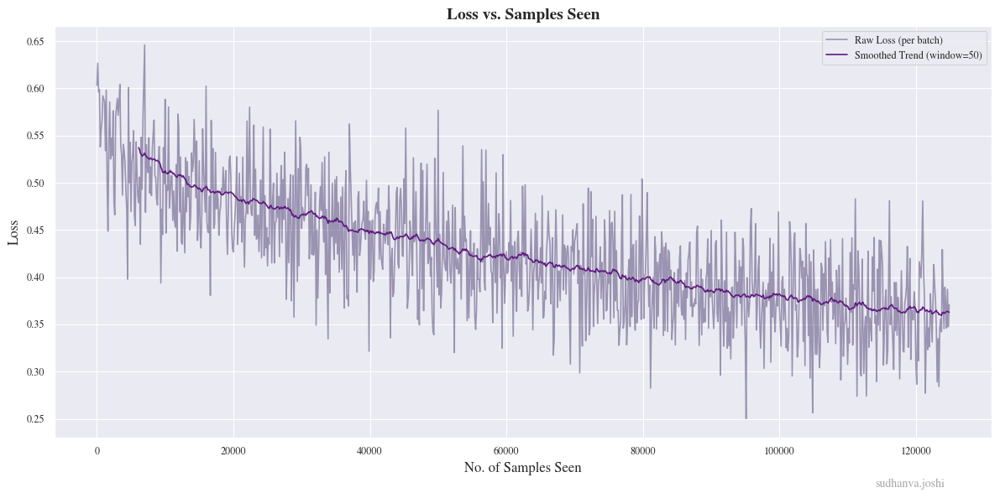

Saving final model.
Model saved to runs-q1/9l17fxj3/final_model.npz
Model has 17025 trainable parameters.
Final accuracy: 83.40%
Final Loss: 0.360581949379285

Final Pixel Accuracy: 83.40%


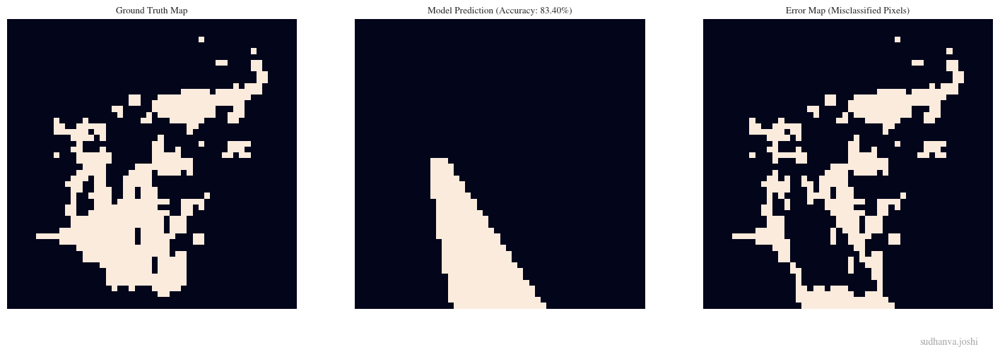

batch_size,128
final_accuracy,0.834
final_loss,0.36058
grad_steps,4
learning_rate,0.00067
samples_to_converge,125000
time_to_converge,2.43639
total_parameters,17025


wandb: Agent Starting Run: j2x17tj5 with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00017275948639674602
wandb: 	width: 256



Sweep Run
Config: Depth=3, Width=256, LR=0.0002, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 9.55s.


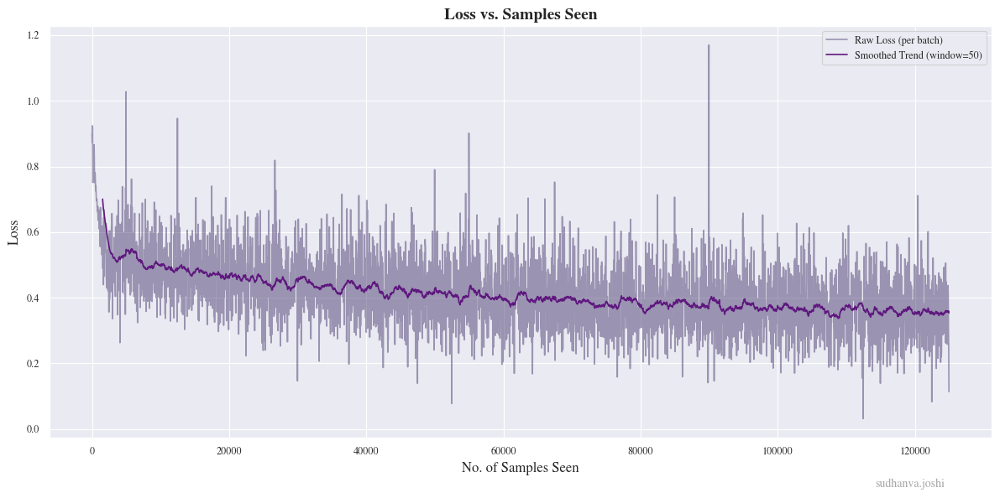

Saving final model.
Model saved to runs-q1/j2x17tj5/final_model.npz
Model has 66817 trainable parameters.
Final accuracy: 83.60%
Final Loss: 0.3572169519775169

Final Pixel Accuracy: 83.60%


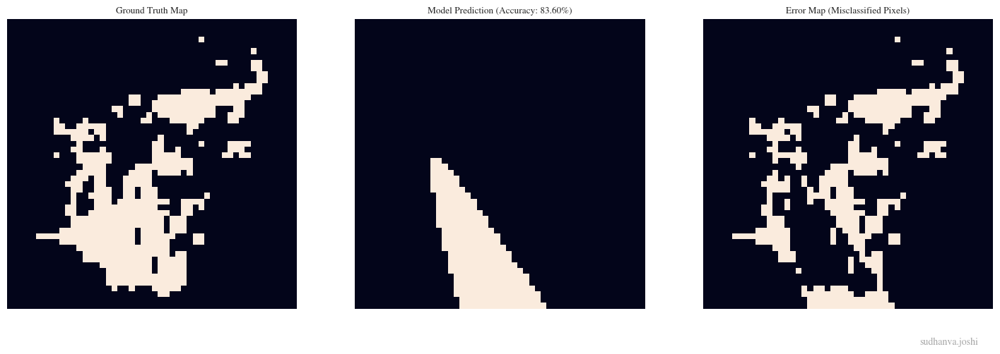

batch_size,32
final_accuracy,0.836
final_loss,0.35722
grad_steps,4
learning_rate,0.00017
samples_to_converge,125000
time_to_converge,9.55291
total_parameters,66817


wandb: Agent Starting Run: 44fw0kdl with config:
wandb: 	batch_size: 64
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0007598252258077277
wandb: 	width: 32



Sweep Run
Config: Depth=4, Width=32, LR=0.0008, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.27s.


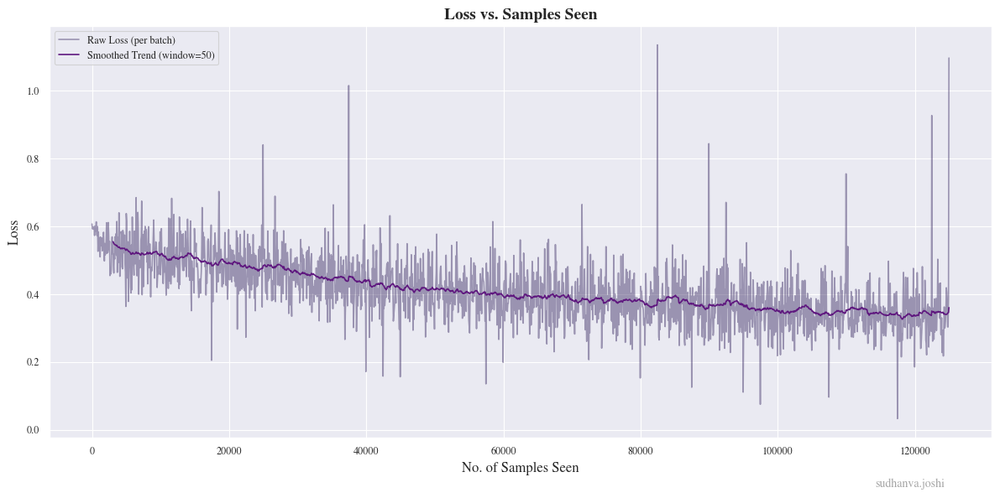

Saving final model.
Model saved to runs-q1/44fw0kdl/final_model.npz
Model has 2241 trainable parameters.
Final accuracy: 84.52%
Final Loss: 0.33800357250350355

Final Pixel Accuracy: 84.52%


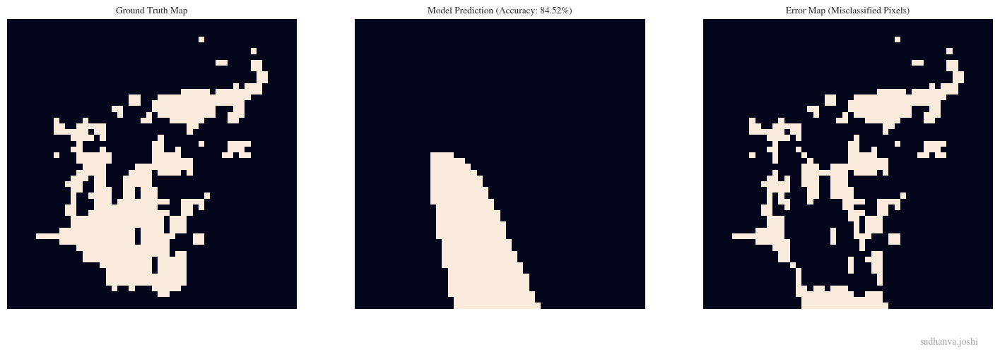

batch_size,64
final_accuracy,0.8452
final_loss,0.338
grad_steps,4
learning_rate,0.00076
samples_to_converge,125000
time_to_converge,1.27054
total_parameters,2241


wandb: Agent Starting Run: jksmdmay with config:
wandb: 	batch_size: 128
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0006775379389966199
wandb: 	width: 64



Sweep Run
Config: Depth=4, Width=64, LR=0.0007, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 1.27s.


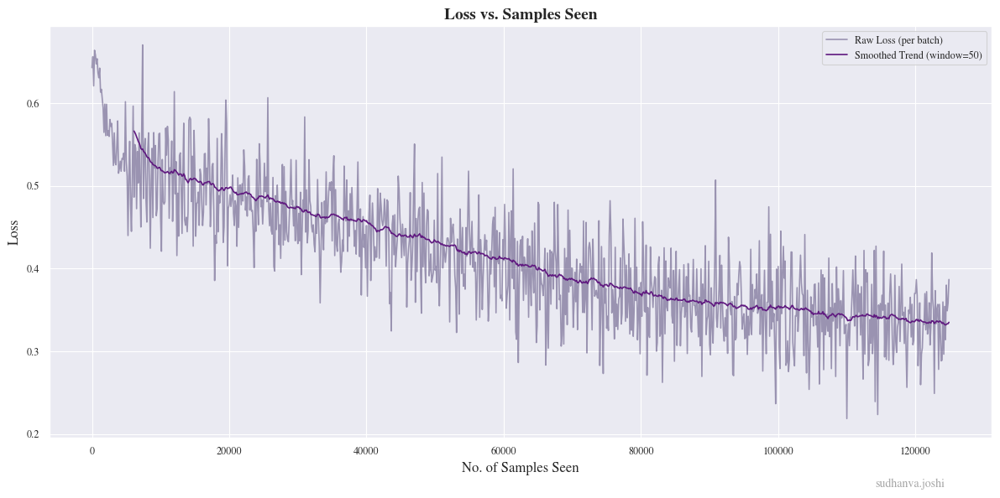

Saving final model.
Model saved to runs-q1/jksmdmay/final_model.npz
Model has 8577 trainable parameters.
Final accuracy: 84.48%
Final Loss: 0.33442885740377315

Final Pixel Accuracy: 84.48%


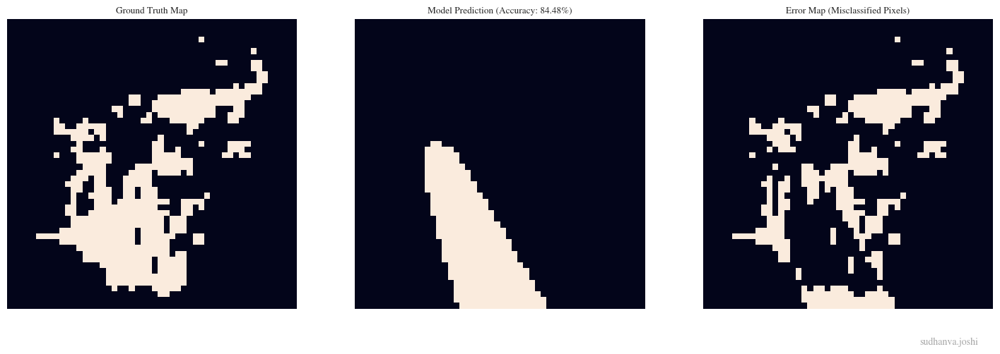

batch_size,128
final_accuracy,0.8448
final_loss,0.33443
grad_steps,4
learning_rate,0.00068
samples_to_converge,125000
time_to_converge,1.27261
total_parameters,8577


wandb: Agent Starting Run: 4350oiqp with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0005951252501005268
wandb: 	width: 256



Sweep Run
Config: Depth=3, Width=256, LR=0.0006, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 23.26s.


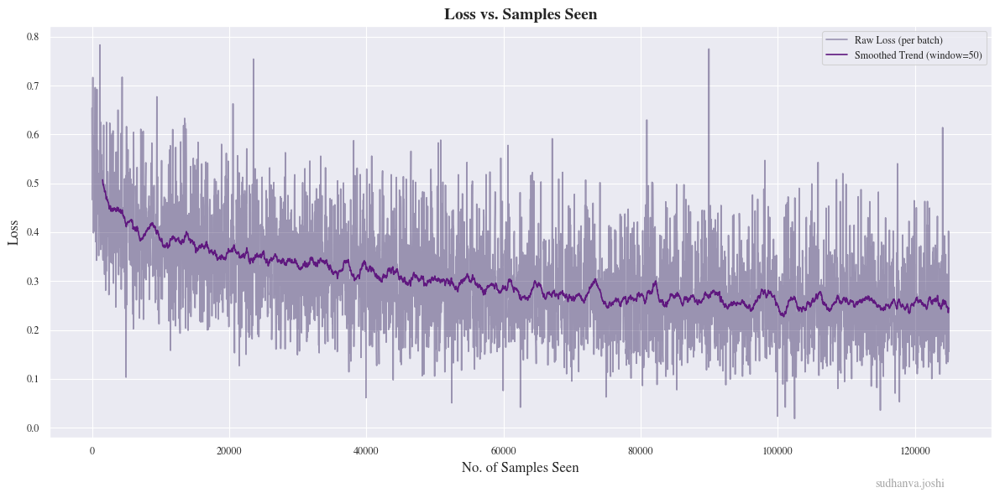

Saving final model.
Model saved to runs-q1/4350oiqp/final_model.npz
Model has 66817 trainable parameters.
Final accuracy: 89.08%
Final Loss: 0.2518224150505753

Final Pixel Accuracy: 89.08%


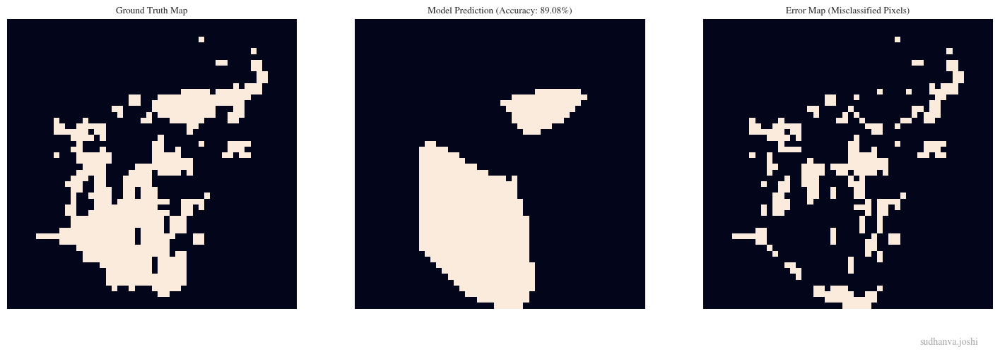

batch_size,32
final_accuracy,0.8908
final_loss,0.25182
grad_steps,1
learning_rate,0.0006
samples_to_converge,125000
time_to_converge,23.25571
total_parameters,66817


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: mpiglmcx with config:
wandb: 	batch_size: 32
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0006607073705367842
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0007, Batch=32



Early stopping triggered at epoch 47.
Epoch 47 complete. Total samples seen: 117500. Time: 24.71s.


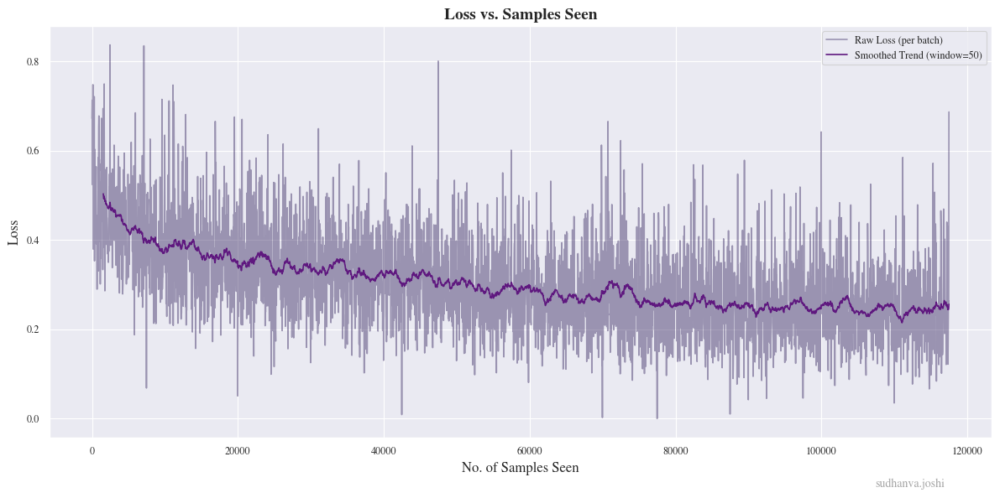

Saving final model.
Model saved to runs-q1/mpiglmcx/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 87.72%
Final Loss: 0.2520459082875

Final Pixel Accuracy: 87.72%


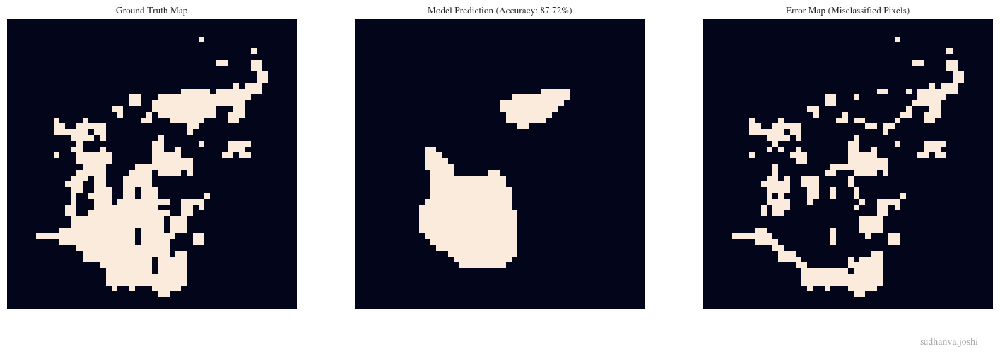

batch_size,32
final_accuracy,0.8772
final_loss,0.25205
grad_steps,2
learning_rate,0.00066
samples_to_converge,117500
time_to_converge,24.70744
total_parameters,132609


wandb: Agent Starting Run: ce4kgnrh with config:
wandb: 	batch_size: 32
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007663171639602289
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0008, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 36.16s.


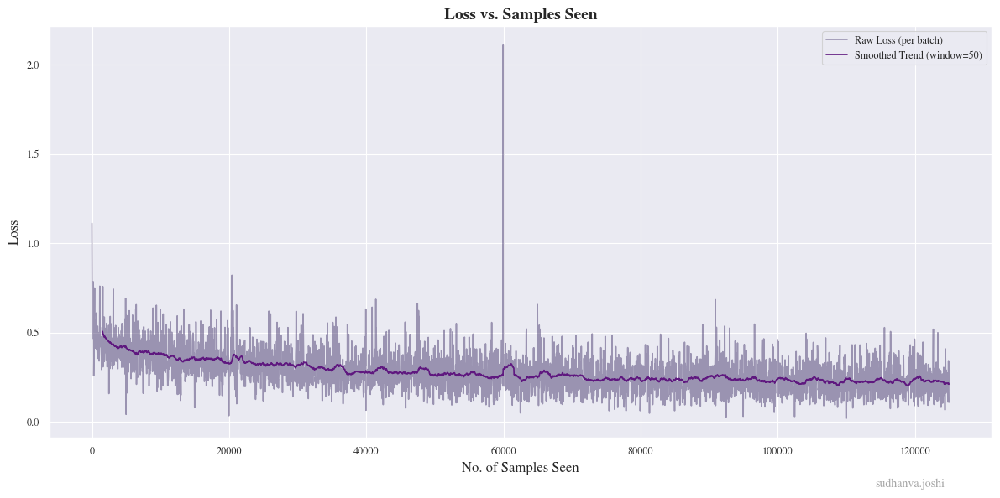

Saving final model.
Model saved to runs-q1/ce4kgnrh/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 89.80%
Final Loss: 0.22287799439470124

Final Pixel Accuracy: 89.80%


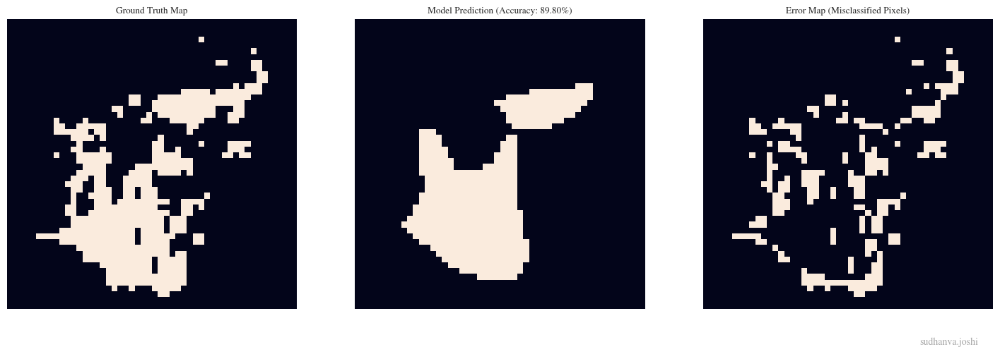

batch_size,32
final_accuracy,0.898
final_loss,0.22288
grad_steps,1
learning_rate,0.00077
samples_to_converge,125000
time_to_converge,36.16323
total_parameters,132609


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: 7t65eqcx with config:
wandb: 	batch_size: 32
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0009517275882309852
wandb: 	width: 256



Sweep Run
Config: Depth=5, Width=256, LR=0.0010, Batch=32



Early stopping triggered at epoch 29.
Epoch 29 complete. Total samples seen: 72500. Time: 48.52s.


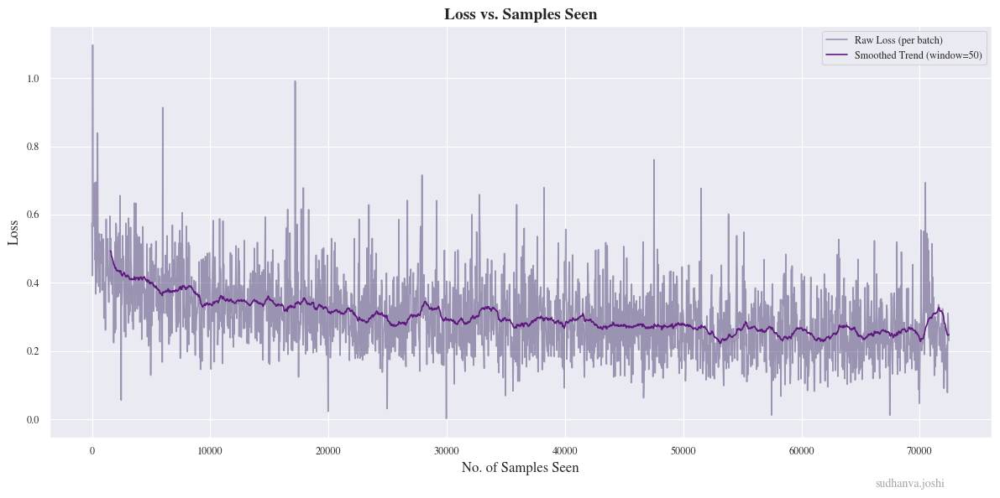

Saving final model.
Model saved to runs-q1/7t65eqcx/final_model.npz
Model has 198401 trainable parameters.
Final accuracy: 89.08%
Final Loss: 0.2878047199075572

Final Pixel Accuracy: 89.08%


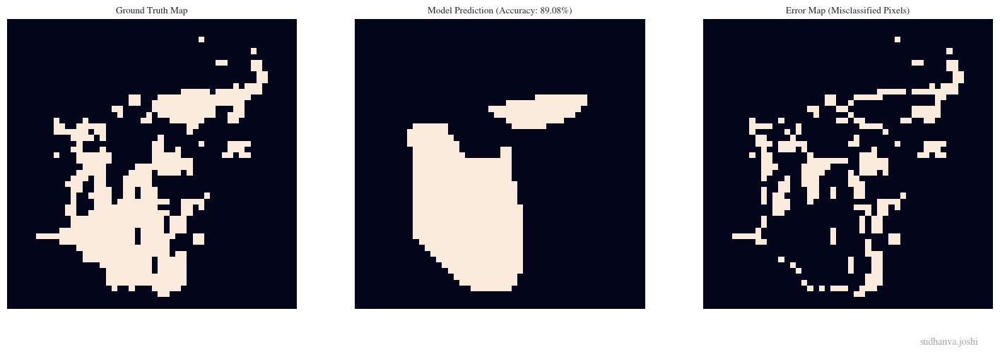

batch_size,32
final_accuracy,0.8908
final_loss,0.2878
grad_steps,1
learning_rate,0.00095
samples_to_converge,72500
time_to_converge,48.51797
total_parameters,198401


wandb: Agent Starting Run: 93pkxl6s with config:
wandb: 	batch_size: 32
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007558772087306977
wandb: 	width: 256



Sweep Run
Config: Depth=5, Width=256, LR=0.0008, Batch=32



Early stopping triggered at epoch 28.
Epoch 28 complete. Total samples seen: 70000. Time: 29.09s.


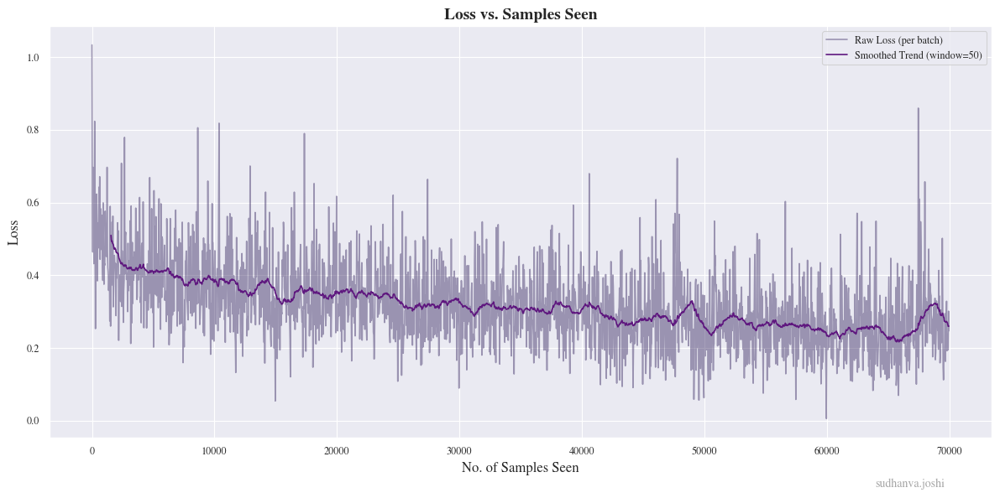

Saving final model.
Model saved to runs-q1/93pkxl6s/final_model.npz
Model has 198401 trainable parameters.
Final accuracy: 89.44%
Final Loss: 0.286519064064332

Final Pixel Accuracy: 89.44%


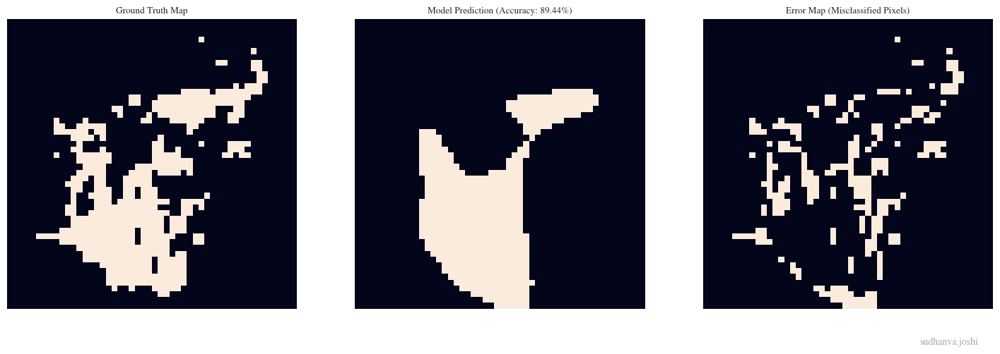

batch_size,32
final_accuracy,0.8944
final_loss,0.28652
grad_steps,1
learning_rate,0.00076
samples_to_converge,70000
time_to_converge,29.09097
total_parameters,198401


wandb: Agent Starting Run: 77x3tsv6 with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0009361078634866584
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0009, Batch=16



Early stopping triggered at epoch 45.
Epoch 45 complete. Total samples seen: 112500. Time: 33.29s.


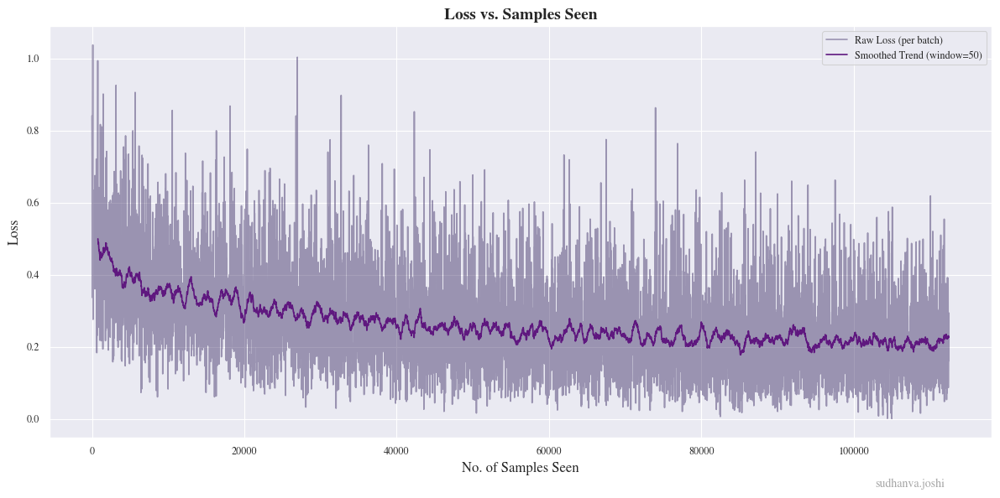

Saving final model.
Model saved to runs-q1/77x3tsv6/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 89.60%
Final Loss: 0.21562373467486945

Final Pixel Accuracy: 89.60%


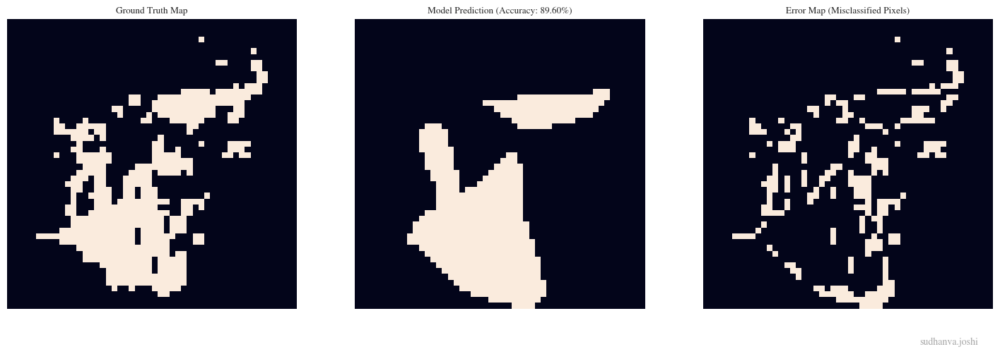

batch_size,16
final_accuracy,0.896
final_loss,0.21562
grad_steps,1
learning_rate,0.00094
samples_to_converge,112500
time_to_converge,33.28689
total_parameters,132609


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: 1q05ptrv with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0008964672994136991
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0009, Batch=16



Early stopping triggered at epoch 33.
Epoch 33 complete. Total samples seen: 82500. Time: 24.05s.


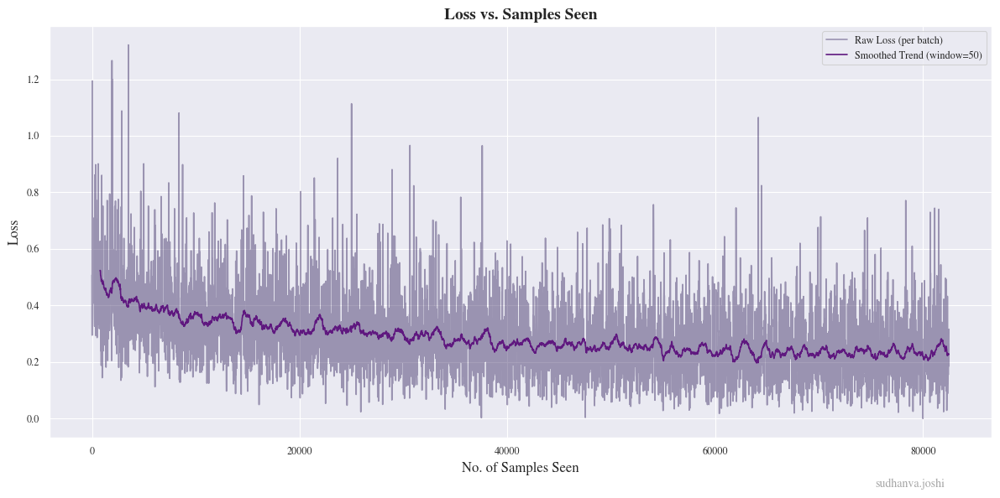

Saving final model.
Model saved to runs-q1/1q05ptrv/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 89.40%
Final Loss: 0.24148535985996905

Final Pixel Accuracy: 89.40%


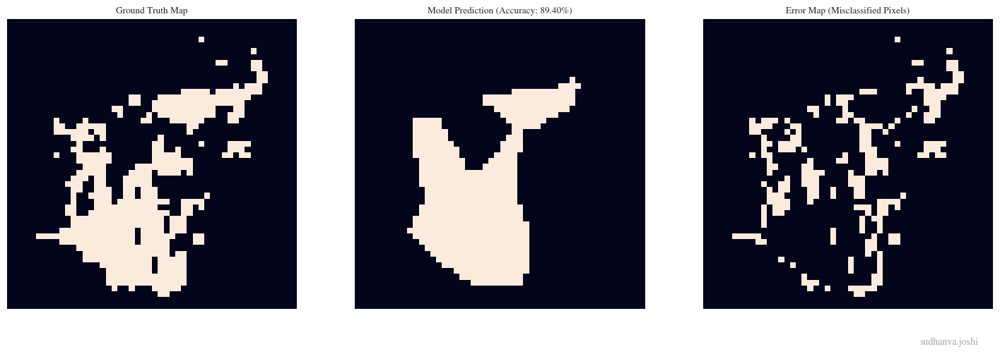

batch_size,16
final_accuracy,0.894
final_loss,0.24149
grad_steps,1
learning_rate,0.0009
samples_to_converge,82500
time_to_converge,24.0468
total_parameters,132609


wandb: Agent Starting Run: x26eoetb with config:
wandb: 	batch_size: 64
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0008440008441309157
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0008, Batch=64



Early stopping triggered at epoch 36.
Epoch 36 complete. Total samples seen: 90000. Time: 15.30s.


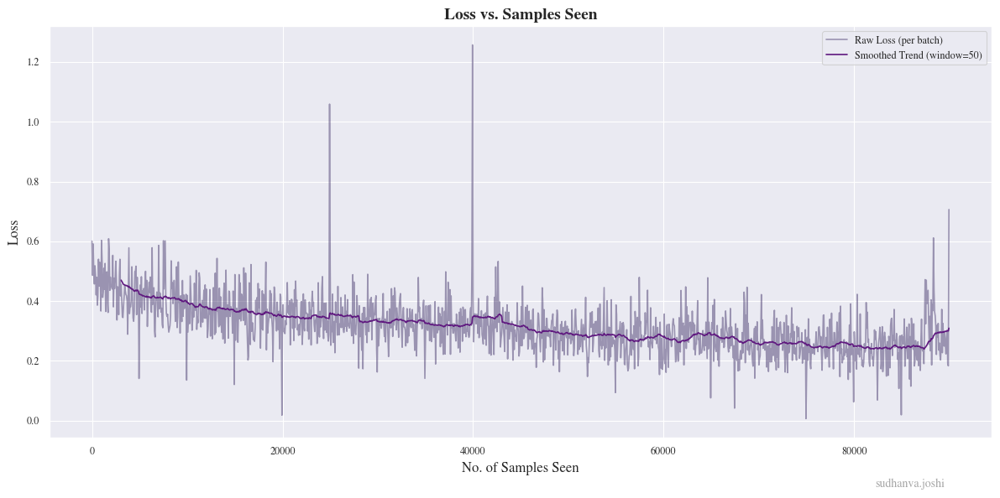

Saving final model.
Model saved to runs-q1/x26eoetb/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 84.52%
Final Loss: 0.3105561245301367

Final Pixel Accuracy: 84.52%


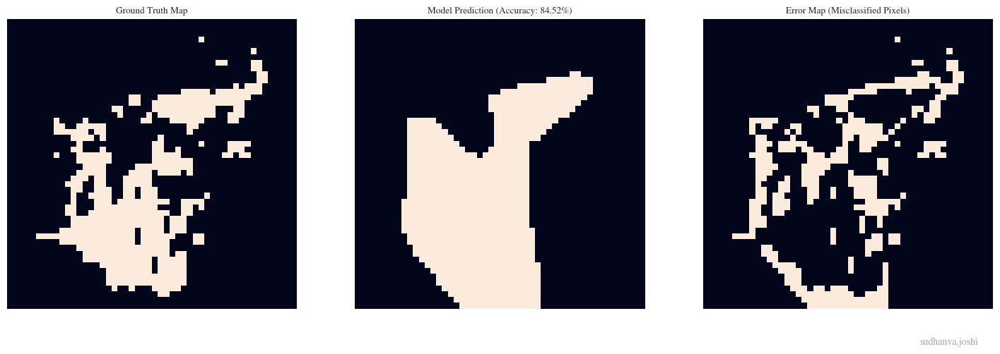

batch_size,64
final_accuracy,0.8452
final_loss,0.31056
grad_steps,1
learning_rate,0.00084
samples_to_converge,90000
time_to_converge,15.30308
total_parameters,132609


wandb: Agent Starting Run: y47u7p5n with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0009735282279083682
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0010, Batch=16



Early stopping triggered at epoch 42.
Epoch 42 complete. Total samples seen: 105000. Time: 55.17s.


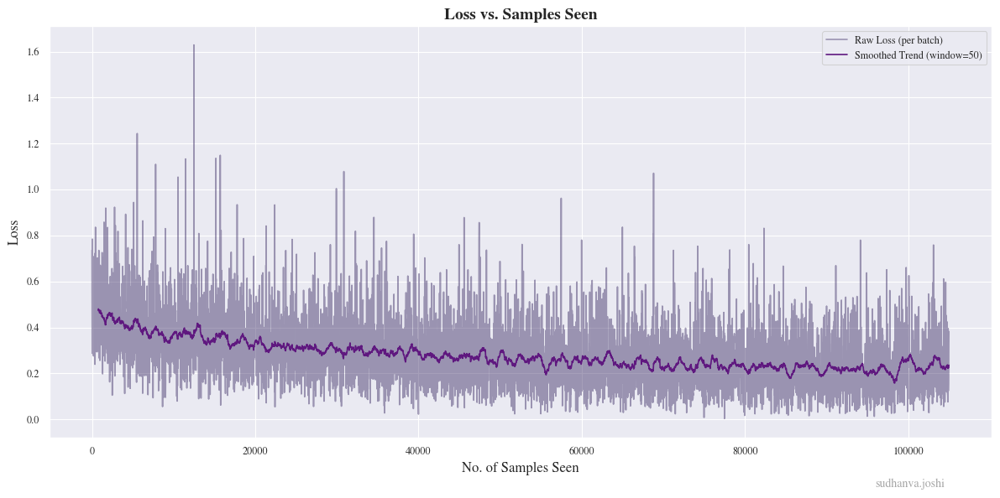

Saving final model.
Model saved to runs-q1/y47u7p5n/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 90.76%
Final Loss: 0.2419930729104015

Final Pixel Accuracy: 90.76%


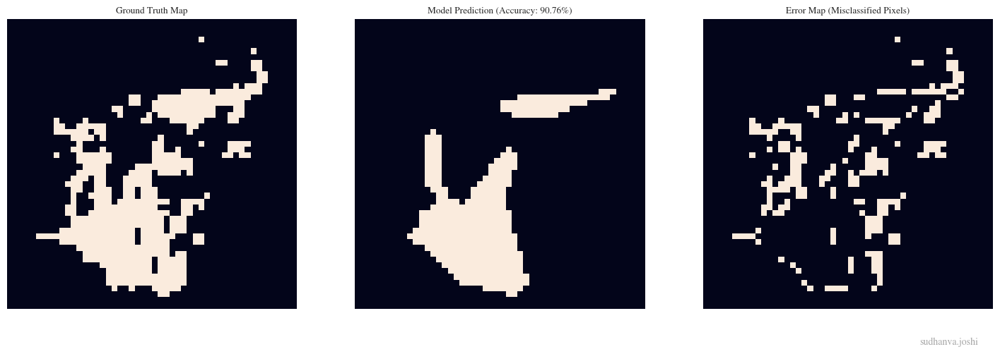

batch_size,16
final_accuracy,0.9076
final_loss,0.24199
grad_steps,1
learning_rate,0.00097
samples_to_converge,105000
time_to_converge,55.16839
total_parameters,264193


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: yn009qo5 with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0009831668512581284
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0010, Batch=16



Early stopping triggered at epoch 45.
Epoch 45 complete. Total samples seen: 112500. Time: 61.56s.


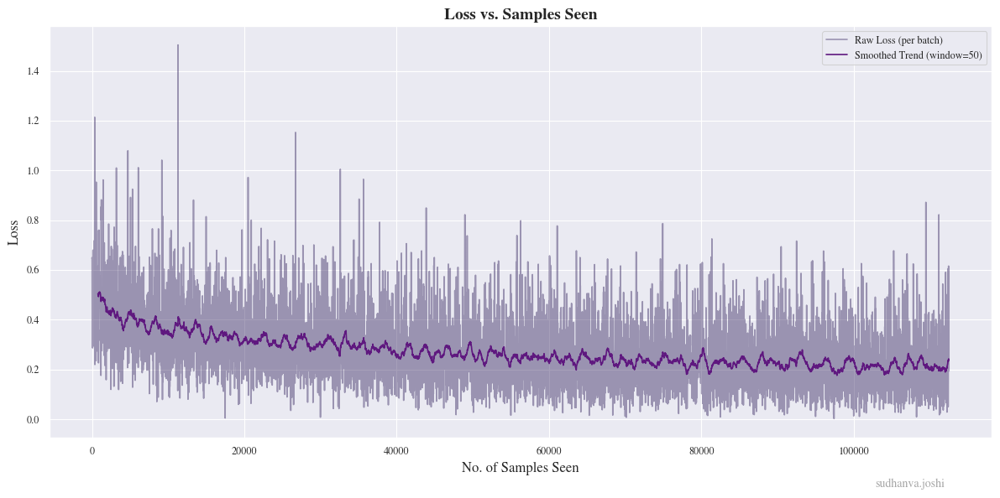

Saving final model.
Model saved to runs-q1/yn009qo5/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 90.36%
Final Loss: 0.21885824740223517

Final Pixel Accuracy: 90.36%


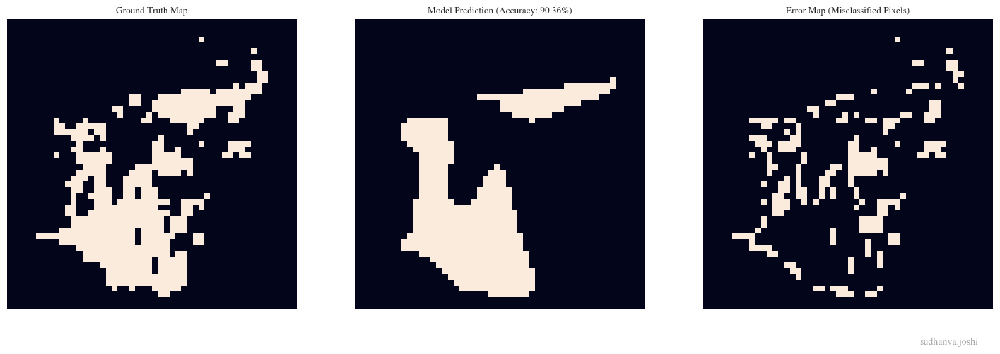

batch_size,16
final_accuracy,0.9036
final_loss,0.21886
grad_steps,1
learning_rate,0.00098
samples_to_converge,112500
time_to_converge,61.5648
total_parameters,264193


wandb: Agent Starting Run: dr45kblf with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007941589785599751
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0008, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 79.17s.


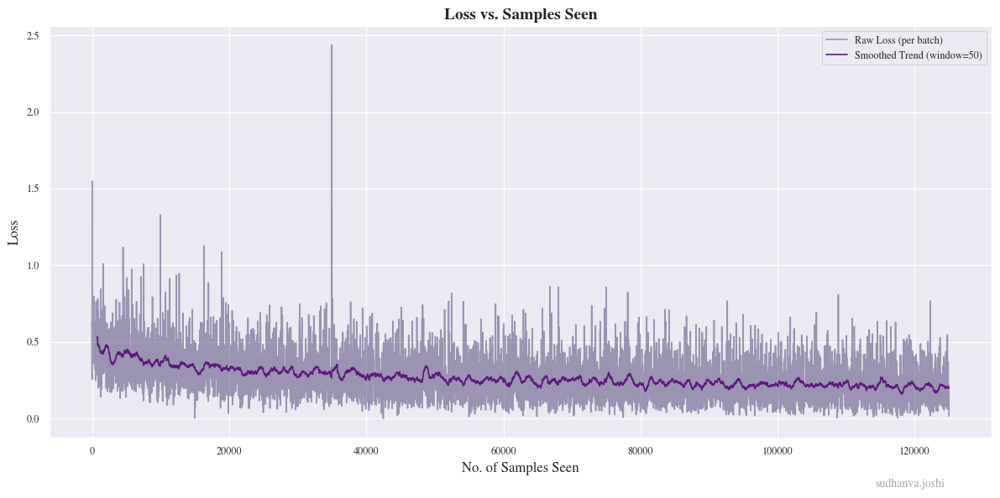

Saving final model.
Model saved to runs-q1/dr45kblf/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 91.32%
Final Loss: 0.1980559645963915

Final Pixel Accuracy: 91.32%


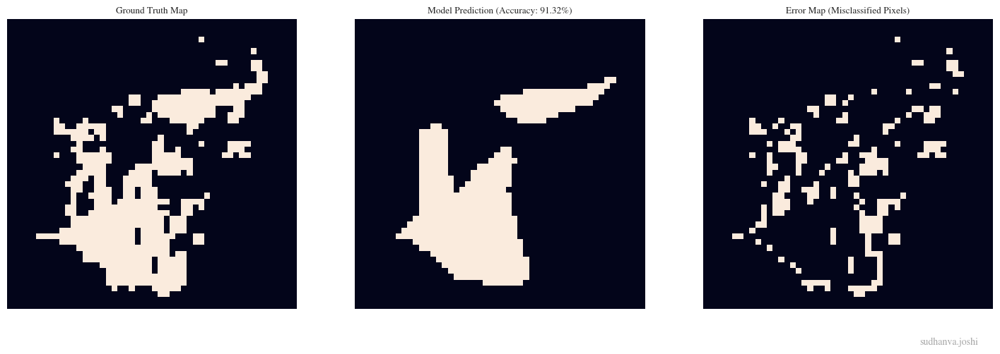

batch_size,16
final_accuracy,0.9132
final_loss,0.19806
grad_steps,1
learning_rate,0.00079
samples_to_converge,125000
time_to_converge,79.17297
total_parameters,264193


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: v1ulw1uj with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0008362703374096574
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0008, Batch=32



Early stopping triggered at epoch 30.
Epoch 30 complete. Total samples seen: 75000. Time: 43.09s.


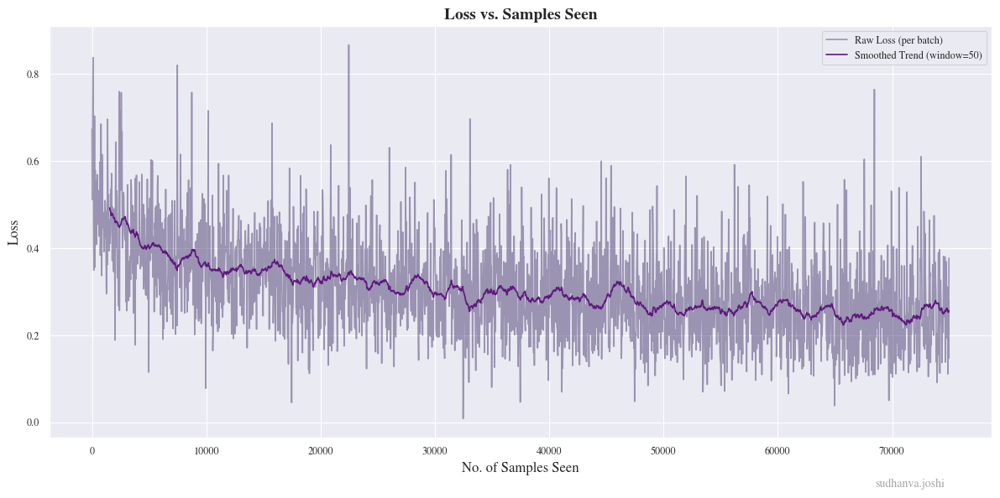

Saving final model.
Model saved to runs-q1/v1ulw1uj/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 86.04%
Final Loss: 0.26628129691469554

Final Pixel Accuracy: 86.04%


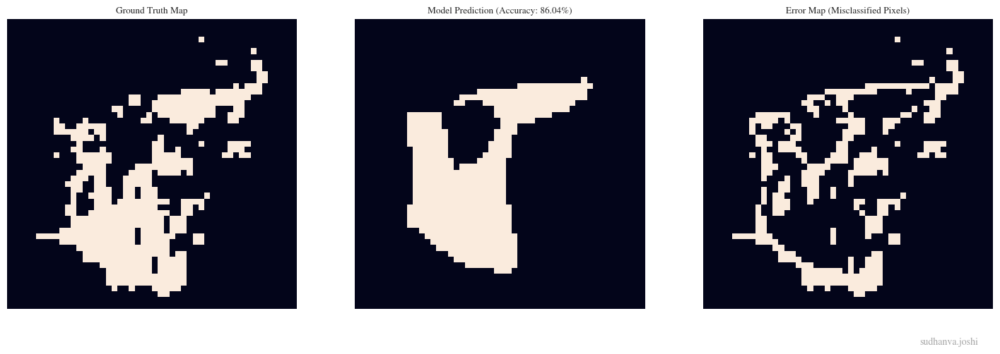

batch_size,32
final_accuracy,0.8604
final_loss,0.26628
grad_steps,1
learning_rate,0.00084
samples_to_converge,75000
time_to_converge,43.09416
total_parameters,264193


wandb: Agent Starting Run: fvku5or2 with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0008587588299976811
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0009, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 162.13s.


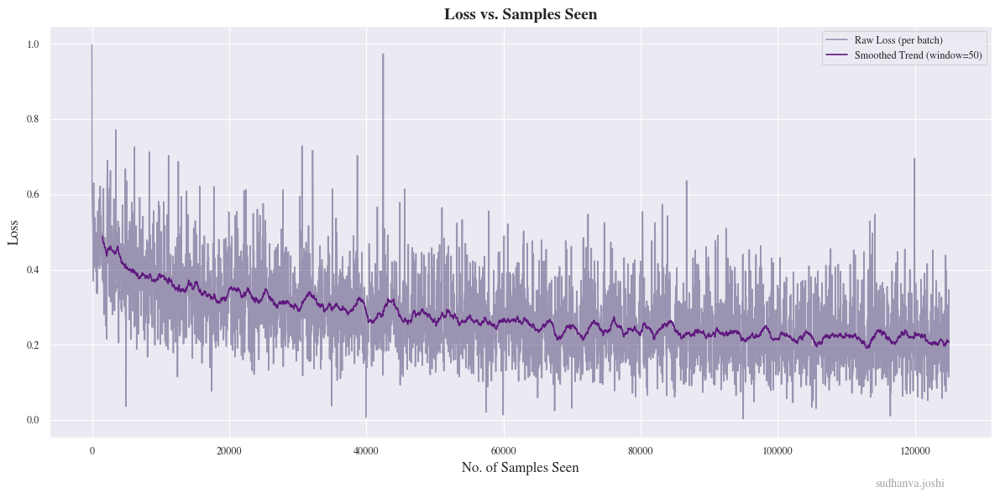

Saving final model.
Model saved to runs-q1/fvku5or2/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 91.20%
Final Loss: 0.21240899036775981

Final Pixel Accuracy: 91.20%


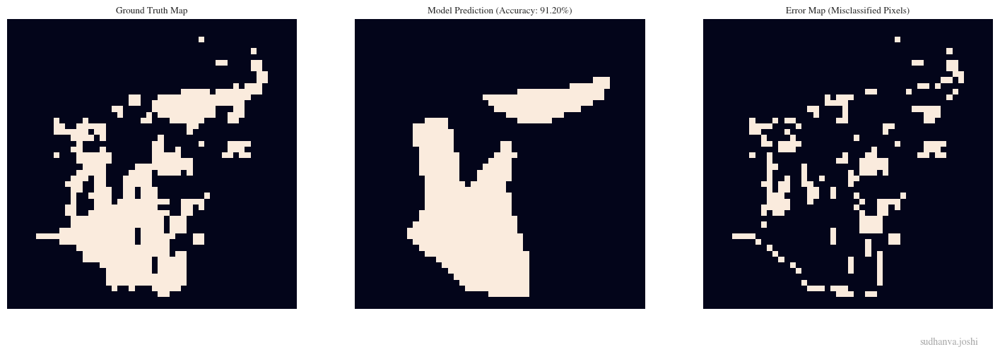

batch_size,32
final_accuracy,0.912
final_loss,0.21241
grad_steps,1
learning_rate,0.00086
samples_to_converge,125000
time_to_converge,162.1347
total_parameters,264193


wandb: Agent Starting Run: k1dfpg6r with config:
wandb: 	batch_size: 128
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0008842487386787729
wandb: 	width: 256



Sweep Run
Config: Depth=3, Width=256, LR=0.0009, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 10.72s.


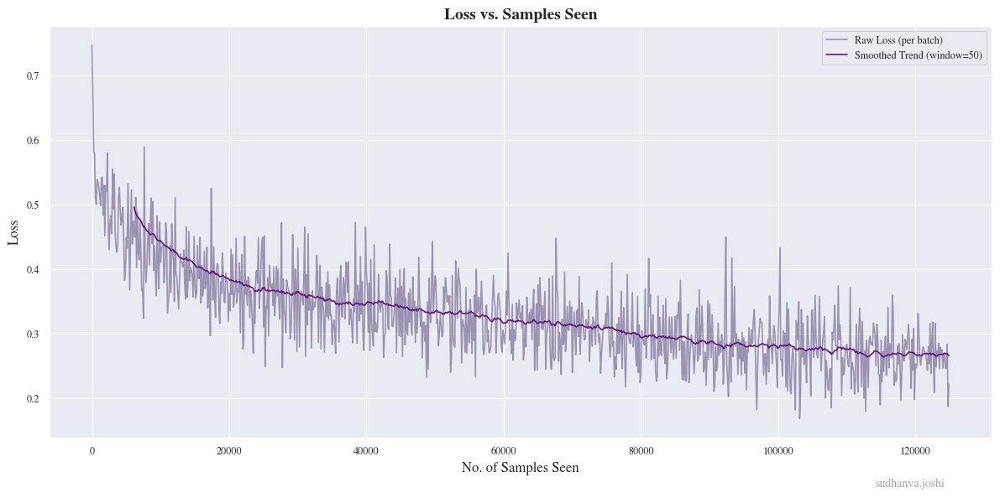

Saving final model.
Model saved to runs-q1/k1dfpg6r/final_model.npz
Model has 66817 trainable parameters.
Final accuracy: 88.12%
Final Loss: 0.2615674153008276

Final Pixel Accuracy: 88.12%


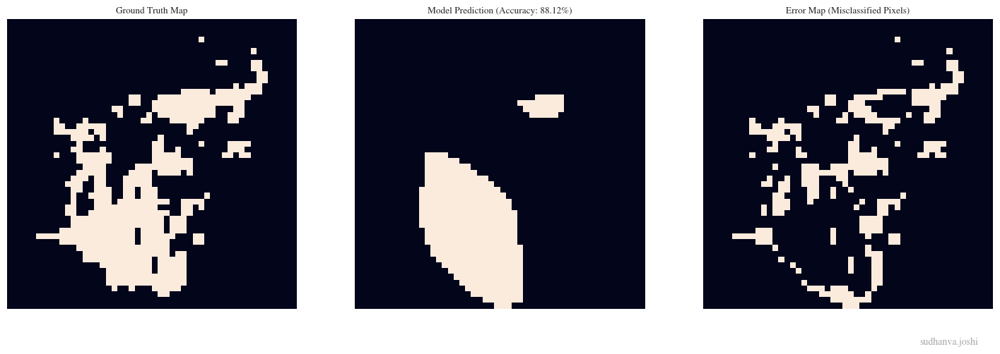

batch_size,128
final_accuracy,0.8812
final_loss,0.26157
grad_steps,1
learning_rate,0.00088
samples_to_converge,125000
time_to_converge,10.72301
total_parameters,66817


wandb: Agent Starting Run: ol2eq8pk with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0002307388524473328
wandb: 	width: 128



Sweep Run
Config: Depth=4, Width=128, LR=0.0002, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 5.73s.


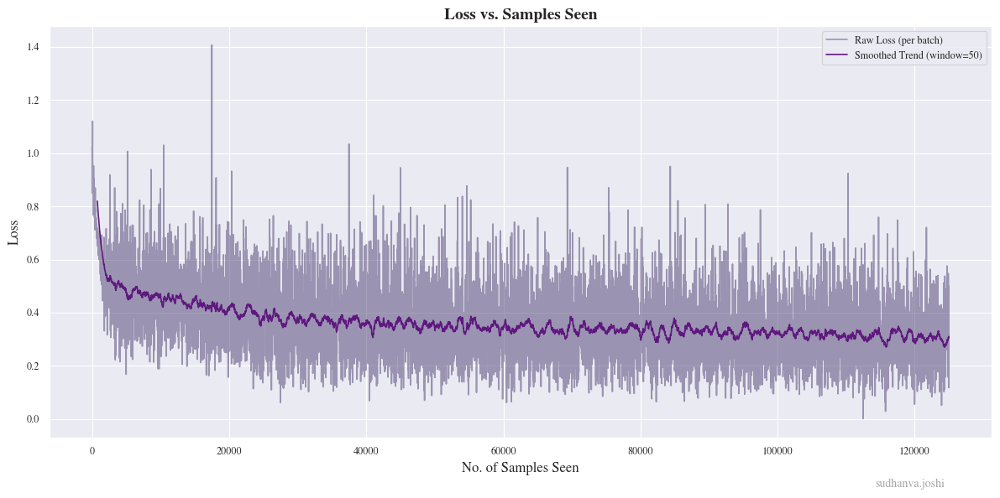

Saving final model.
Model saved to runs-q1/ol2eq8pk/final_model.npz
Model has 33537 trainable parameters.
Final accuracy: 85.32%
Final Loss: 0.30437819024148216

Final Pixel Accuracy: 85.32%


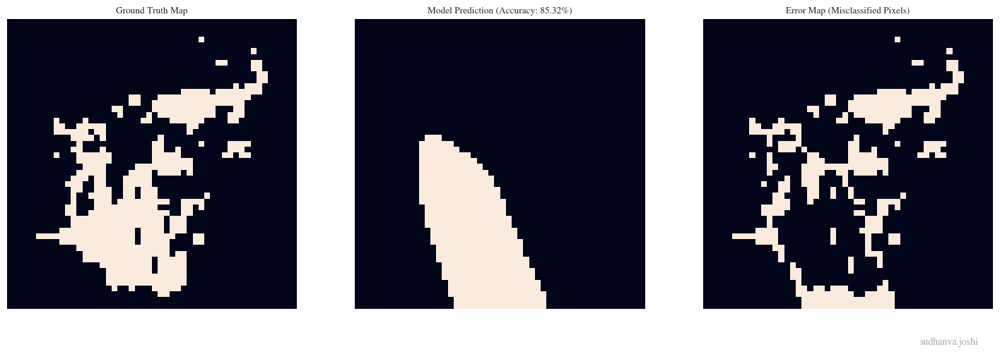

batch_size,16
final_accuracy,0.8532
final_loss,0.30438
grad_steps,4
learning_rate,0.00023
samples_to_converge,125000
time_to_converge,5.72878
total_parameters,33537


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: 0pfh6zdd with config:
wandb: 	batch_size: 128
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0006633939593828332
wandb: 	width: 64



Sweep Run
Config: Depth=4, Width=64, LR=0.0007, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 1.53s.


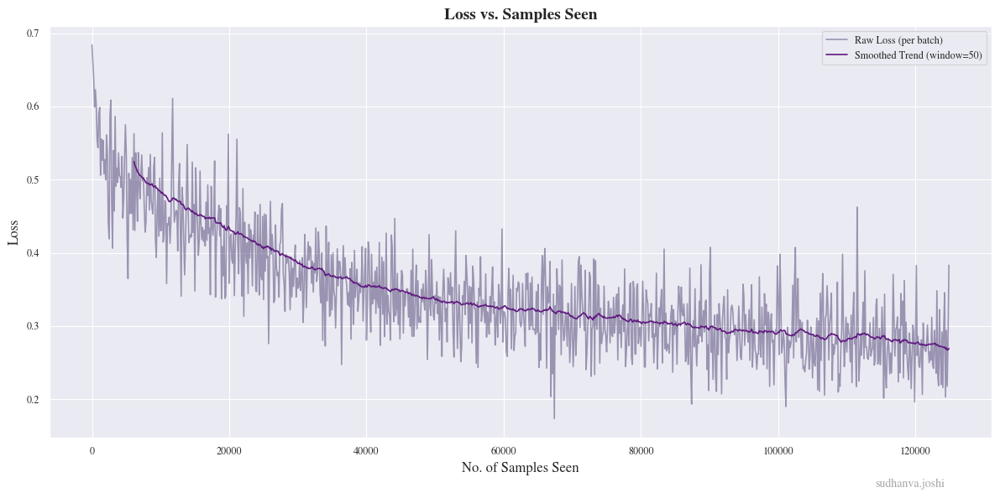

Saving final model.
Model saved to runs-q1/0pfh6zdd/final_model.npz
Model has 8577 trainable parameters.
Final accuracy: 86.84%
Final Loss: 0.2689223636959907

Final Pixel Accuracy: 86.84%


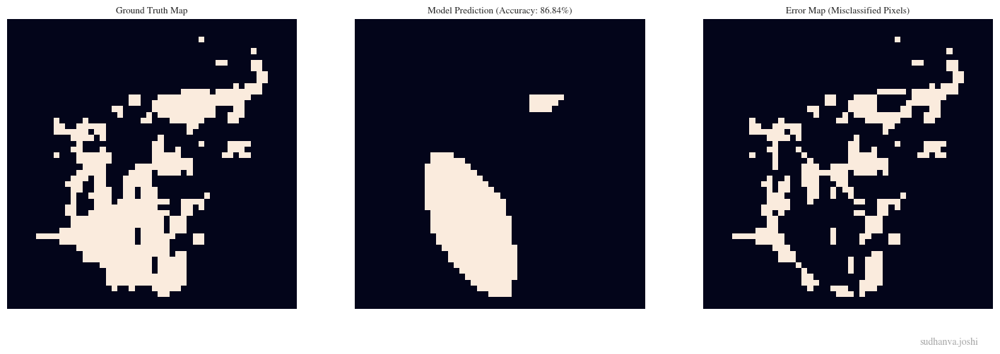

batch_size,128
final_accuracy,0.8684
final_loss,0.26892
grad_steps,1
learning_rate,0.00066
samples_to_converge,125000
time_to_converge,1.52984
total_parameters,8577


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: w96f02st with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.00014082831287502587
wandb: 	width: 128



Sweep Run
Config: Depth=4, Width=128, LR=0.0001, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 15.01s.


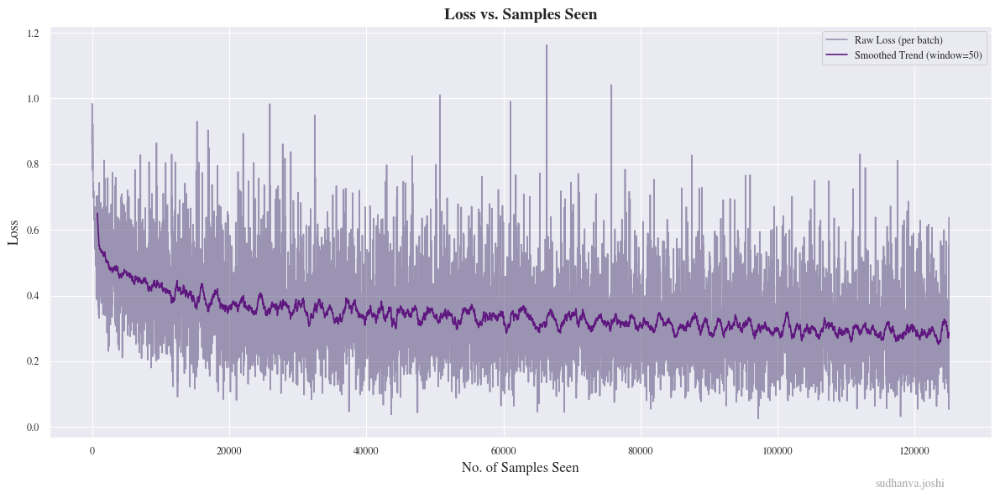

Saving final model.
Model saved to runs-q1/w96f02st/final_model.npz
Model has 33537 trainable parameters.
Final accuracy: 87.28%
Final Loss: 0.2845738580649854

Final Pixel Accuracy: 87.28%


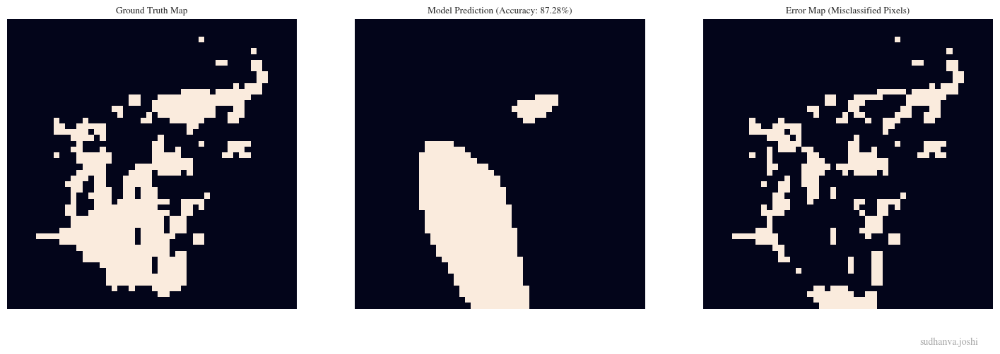

batch_size,16
final_accuracy,0.8728
final_loss,0.28457
grad_steps,1
learning_rate,0.00014
samples_to_converge,125000
time_to_converge,15.01262
total_parameters,33537


wandb: Agent Starting Run: kdo0mjqz with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0009511160648563308
wandb: 	width: 128



Sweep Run
Config: Depth=6, Width=128, LR=0.0010, Batch=16



Early stopping triggered at epoch 33.
Epoch 33 complete. Total samples seen: 82500. Time: 9.55s.


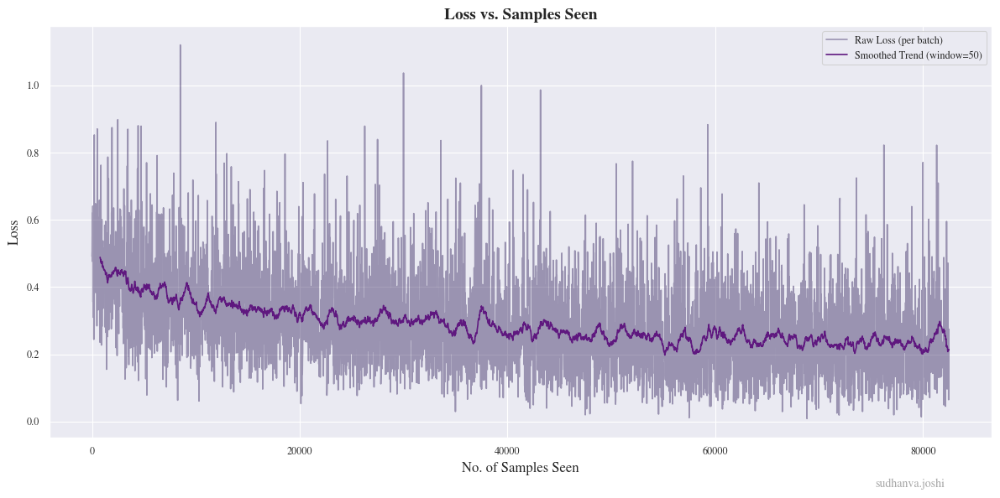

Saving final model.
Model saved to runs-q1/kdo0mjqz/final_model.npz
Model has 66561 trainable parameters.
Final accuracy: 90.68%
Final Loss: 0.24616009860564955

Final Pixel Accuracy: 90.68%


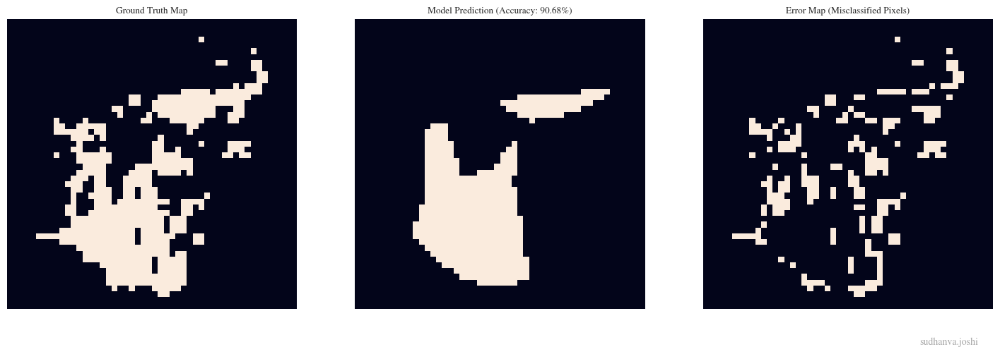

batch_size,16
final_accuracy,0.9068
final_loss,0.24616
grad_steps,2
learning_rate,0.00095
samples_to_converge,82500
time_to_converge,9.55481
total_parameters,66561


wandb: Agent Starting Run: 90ecun0h with config:
wandb: 	batch_size: 16
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0009777159830196423
wandb: 	width: 256



Sweep Run
Config: Depth=5, Width=256, LR=0.0010, Batch=16



Early stopping triggered at epoch 34.
Epoch 34 complete. Total samples seen: 85000. Time: 26.29s.


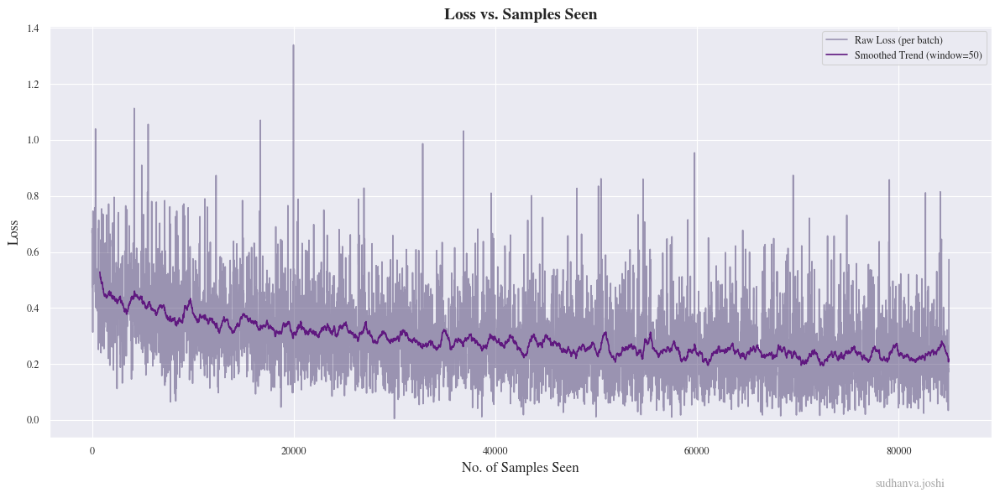

Saving final model.
Model saved to runs-q1/90ecun0h/final_model.npz
Model has 198401 trainable parameters.
Final accuracy: 90.80%
Final Loss: 0.2417280897652348

Final Pixel Accuracy: 90.80%


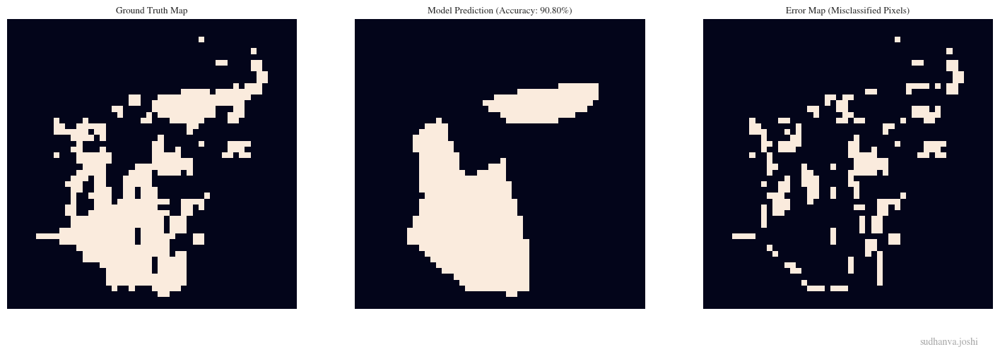

batch_size,16
final_accuracy,0.908
final_loss,0.24173
grad_steps,2
learning_rate,0.00098
samples_to_converge,85000
time_to_converge,26.29177
total_parameters,198401


wandb: Agent Starting Run: dmg7yfs4 with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007244686499527204
wandb: 	width: 128



Sweep Run
Config: Depth=6, Width=128, LR=0.0007, Batch=32



Early stopping triggered at epoch 35.
Epoch 35 complete. Total samples seen: 87500. Time: 7.03s.


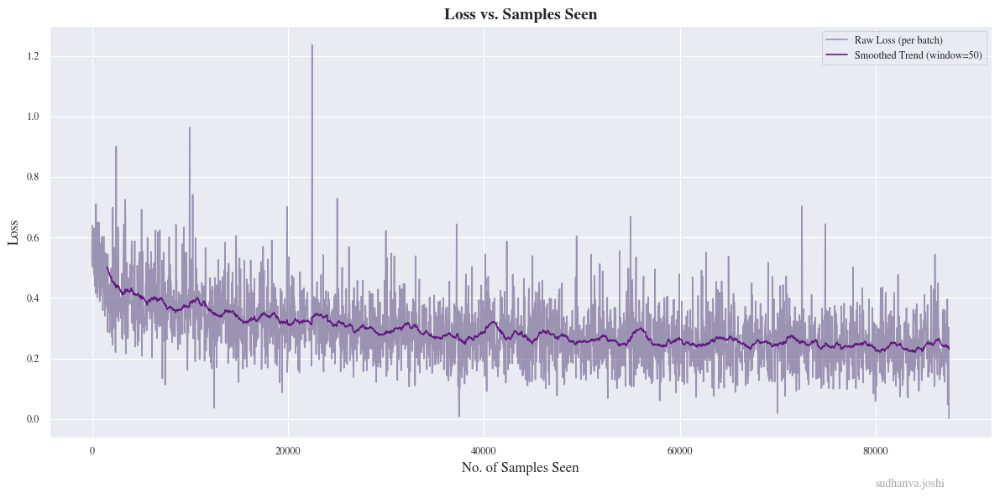

Saving final model.
Model saved to runs-q1/dmg7yfs4/final_model.npz
Model has 66561 trainable parameters.
Final accuracy: 89.36%
Final Loss: 0.24490638016077523

Final Pixel Accuracy: 89.36%


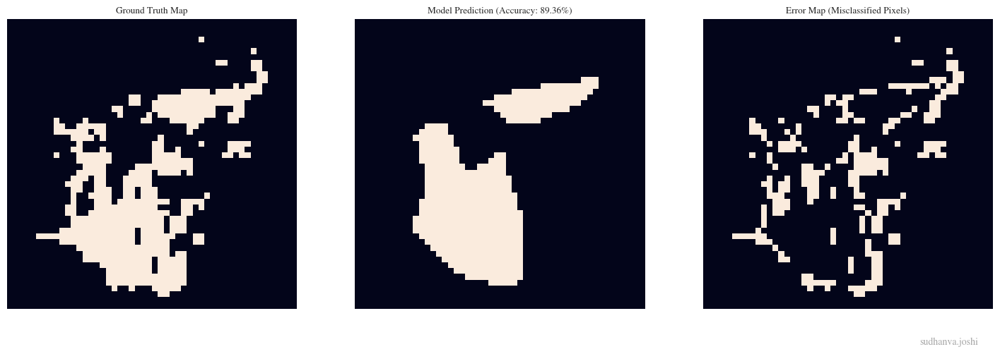

batch_size,32
final_accuracy,0.8936
final_loss,0.24491
grad_steps,1
learning_rate,0.00072
samples_to_converge,87500
time_to_converge,7.02564
total_parameters,66561


wandb: Agent Starting Run: r0cq6x2i with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0003968881950497947
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0004, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 1.32s.


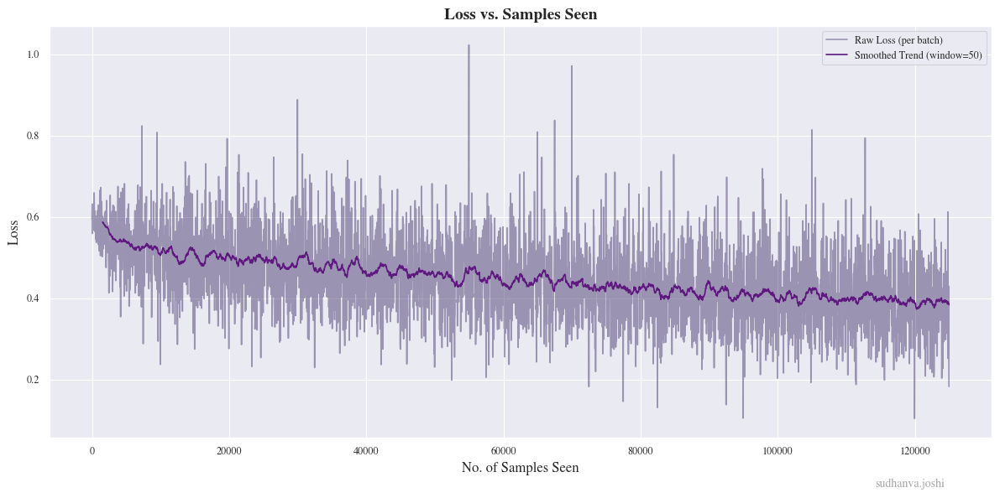

Saving final model.
Model saved to runs-q1/r0cq6x2i/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 81.88%
Final Loss: 0.38981451606448947

Final Pixel Accuracy: 81.88%


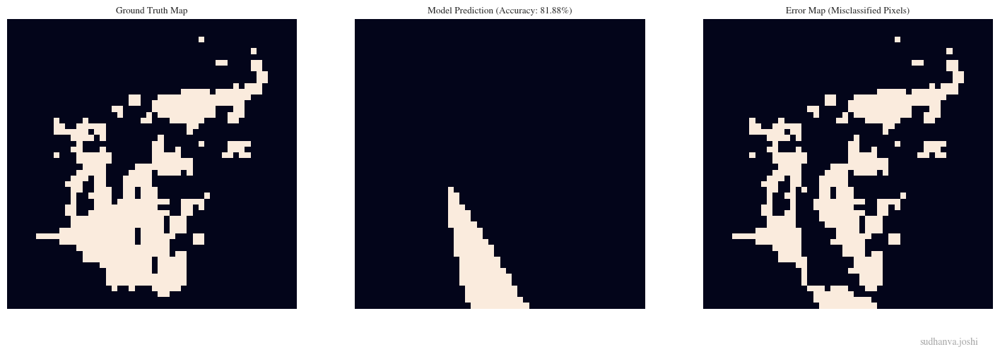

batch_size,32
final_accuracy,0.8188
final_loss,0.38981
grad_steps,4
learning_rate,0.0004
samples_to_converge,125000
time_to_converge,1.31546
total_parameters,1185


wandb: Agent Starting Run: y46a9uyp with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00047897335731106864
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0005, Batch=16



Early stopping triggered at epoch 48.
Epoch 48 complete. Total samples seen: 120000. Time: 15.81s.


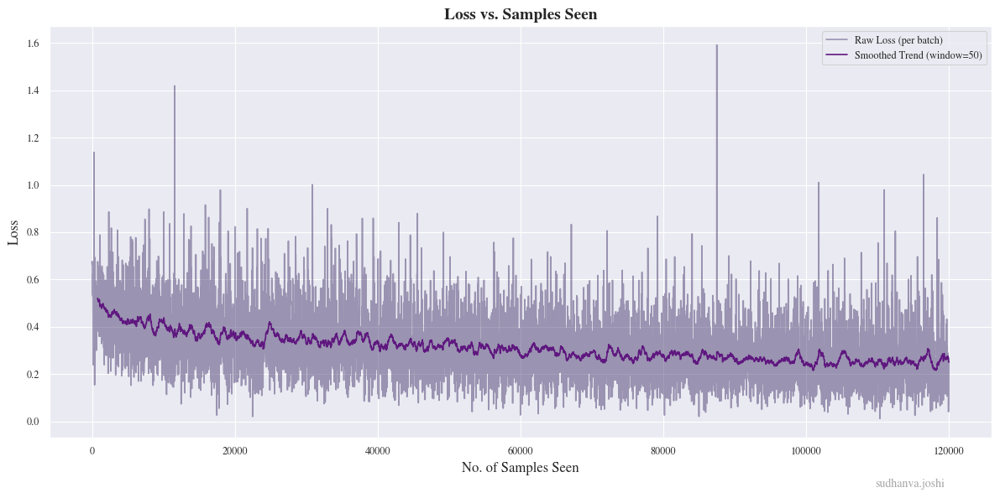

Saving final model.
Model saved to runs-q1/y46a9uyp/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 87.72%
Final Loss: 0.255111554943671

Final Pixel Accuracy: 87.72%


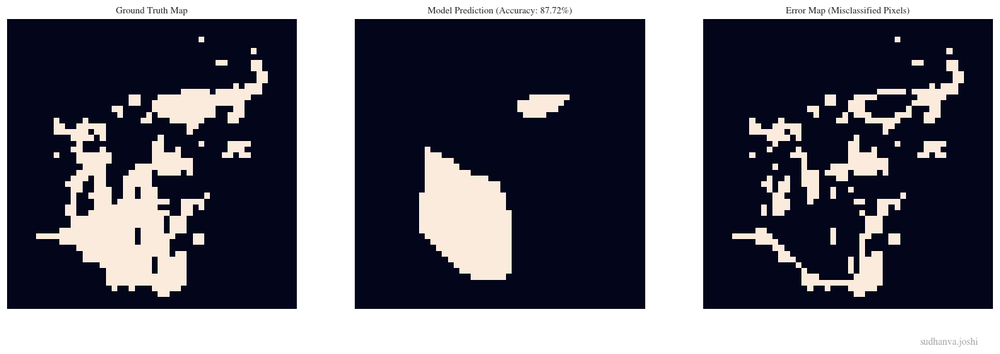

batch_size,16
final_accuracy,0.8772
final_loss,0.25511
grad_steps,4
learning_rate,0.00048
samples_to_converge,120000
time_to_converge,15.80991
total_parameters,132609


wandb: Agent Starting Run: w8eobvsc with config:
wandb: 	batch_size: 64
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0009364820226283902
wandb: 	width: 32



Sweep Run
Config: Depth=5, Width=32, LR=0.0009, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.86s.


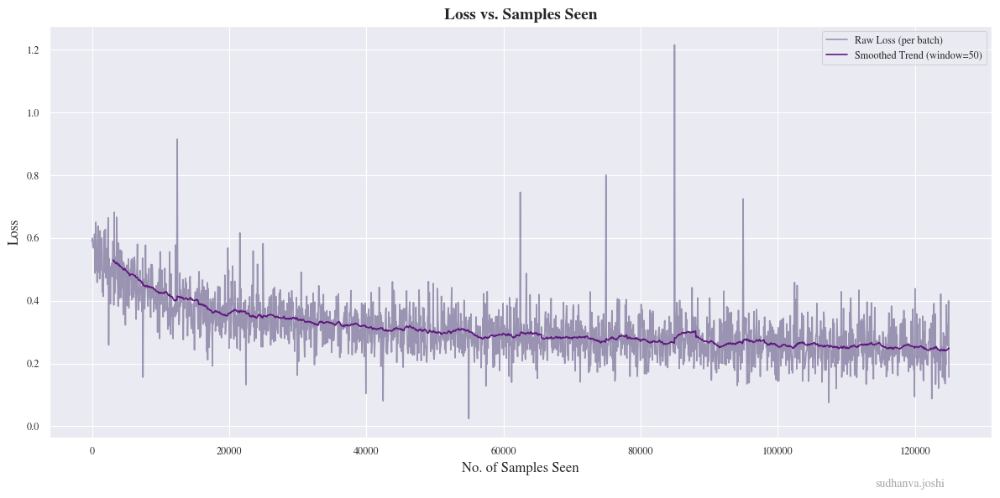

Saving final model.
Model saved to runs-q1/w8eobvsc/final_model.npz
Model has 3297 trainable parameters.
Final accuracy: 87.68%
Final Loss: 0.25023502015526095

Final Pixel Accuracy: 87.68%


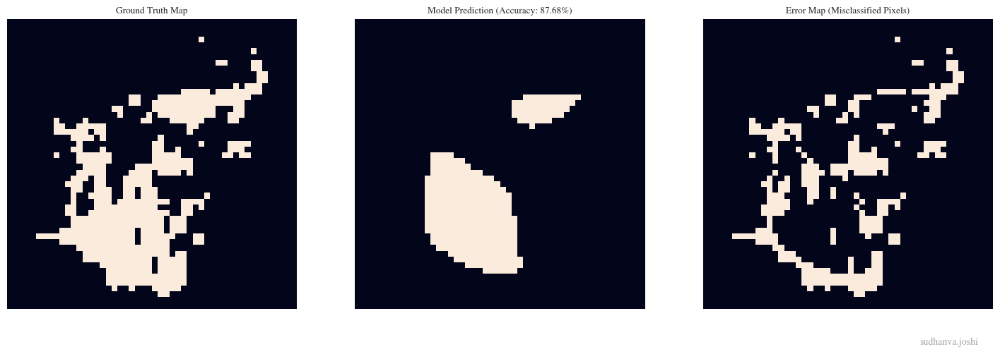

batch_size,64
final_accuracy,0.8768
final_loss,0.25024
grad_steps,1
learning_rate,0.00094
samples_to_converge,125000
time_to_converge,1.85594
total_parameters,3297


wandb: Agent Starting Run: kbcdidtw with config:
wandb: 	batch_size: 64
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.000673984836621394
wandb: 	width: 256



Sweep Run
Config: Depth=5, Width=256, LR=0.0007, Batch=64



Early stopping triggered at epoch 24.
Epoch 24 complete. Total samples seen: 60000. Time: 16.47s.


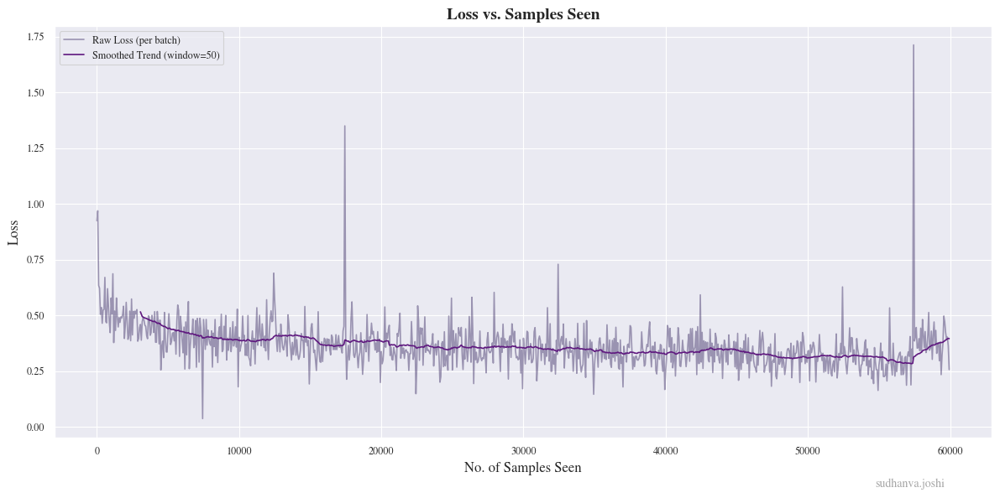

Saving final model.
Model saved to runs-q1/kbcdidtw/final_model.npz
Model has 198401 trainable parameters.
Final accuracy: 84.32%
Final Loss: 0.38774758716682656

Final Pixel Accuracy: 84.32%


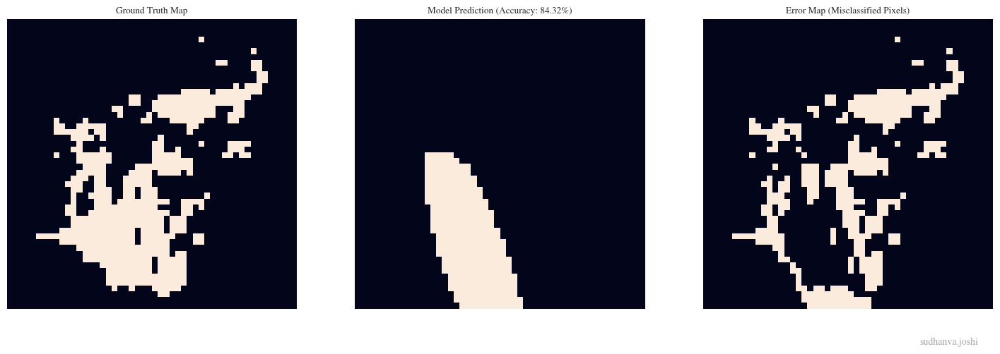

batch_size,64
final_accuracy,0.8432
final_loss,0.38775
grad_steps,2
learning_rate,0.00067
samples_to_converge,60000
time_to_converge,16.47088
total_parameters,198401


wandb: Agent Starting Run: n5hif6g6 with config:
wandb: 	batch_size: 16
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007942305972885814
wandb: 	width: 128



Sweep Run
Config: Depth=5, Width=128, LR=0.0008, Batch=16



Early stopping triggered at epoch 46.
Epoch 46 complete. Total samples seen: 115000. Time: 16.93s.


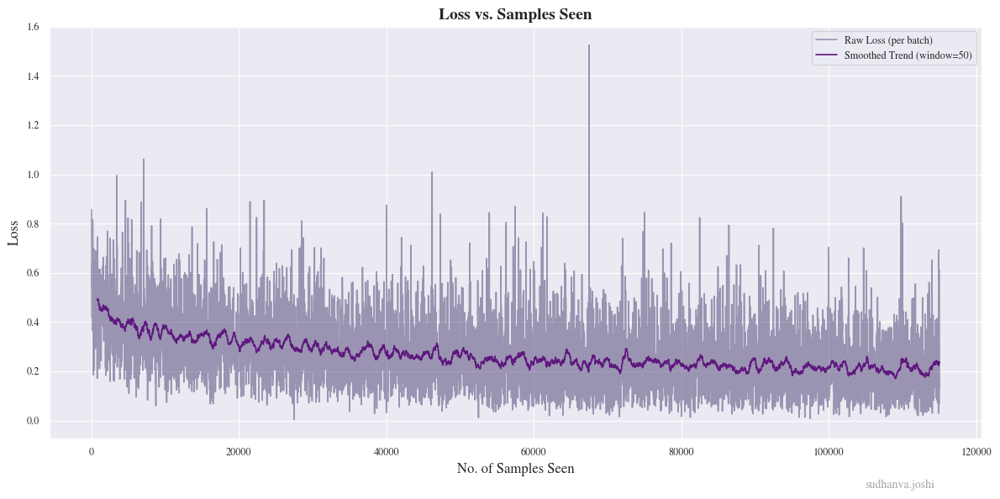

Saving final model.
Model saved to runs-q1/n5hif6g6/final_model.npz
Model has 50049 trainable parameters.
Final accuracy: 91.60%
Final Loss: 0.2168695074209791

Final Pixel Accuracy: 91.60%


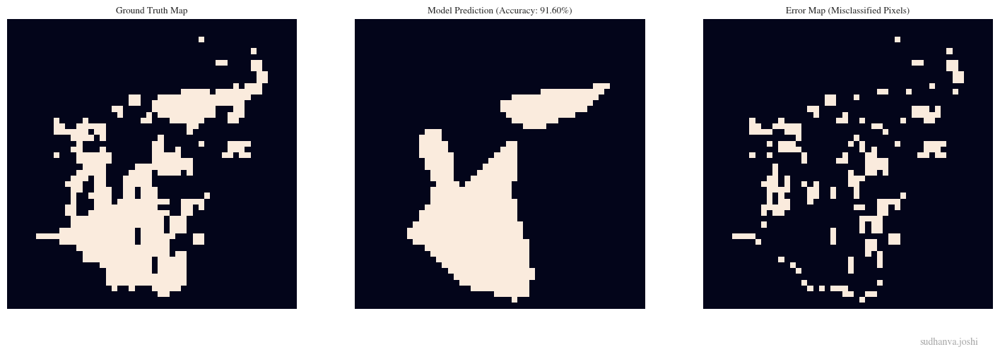

batch_size,16
final_accuracy,0.916
final_loss,0.21687
grad_steps,1
learning_rate,0.00079
samples_to_converge,115000
time_to_converge,16.9281
total_parameters,50049


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: bgjeyb2m with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0006055353867270131
wandb: 	width: 128



Sweep Run
Config: Depth=3, Width=128, LR=0.0006, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 4.38s.


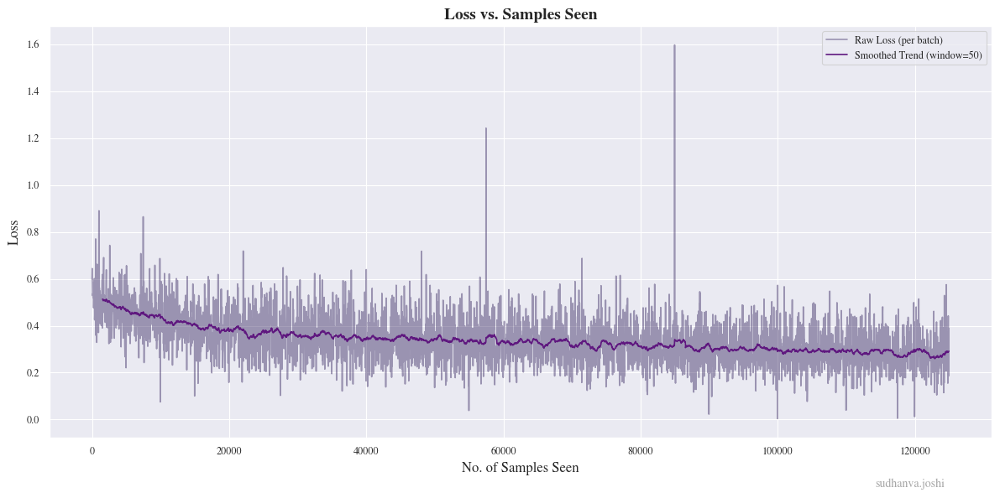

Saving final model.
Model saved to runs-q1/bgjeyb2m/final_model.npz
Model has 17025 trainable parameters.
Final accuracy: 87.68%
Final Loss: 0.28246779893127916

Final Pixel Accuracy: 87.68%


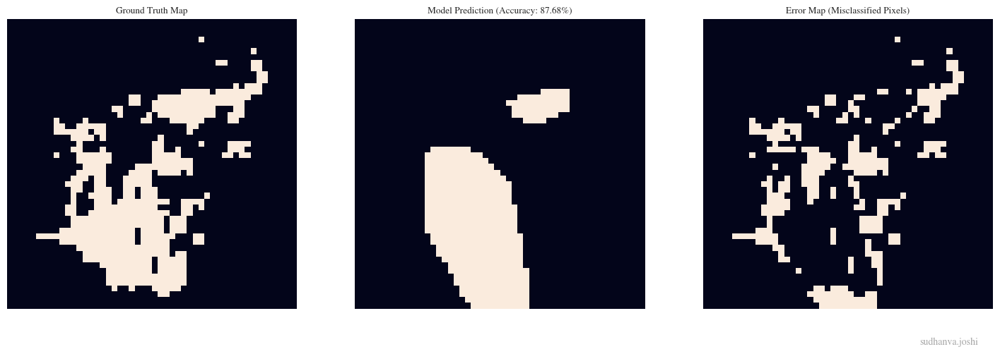

batch_size,32
final_accuracy,0.8768
final_loss,0.28247
grad_steps,2
learning_rate,0.00061
samples_to_converge,125000
time_to_converge,4.37758
total_parameters,17025


wandb: Agent Starting Run: iili904m with config:
wandb: 	batch_size: 32
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.000406020672770379
wandb: 	width: 32



Sweep Run
Config: Depth=5, Width=32, LR=0.0004, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 2.80s.


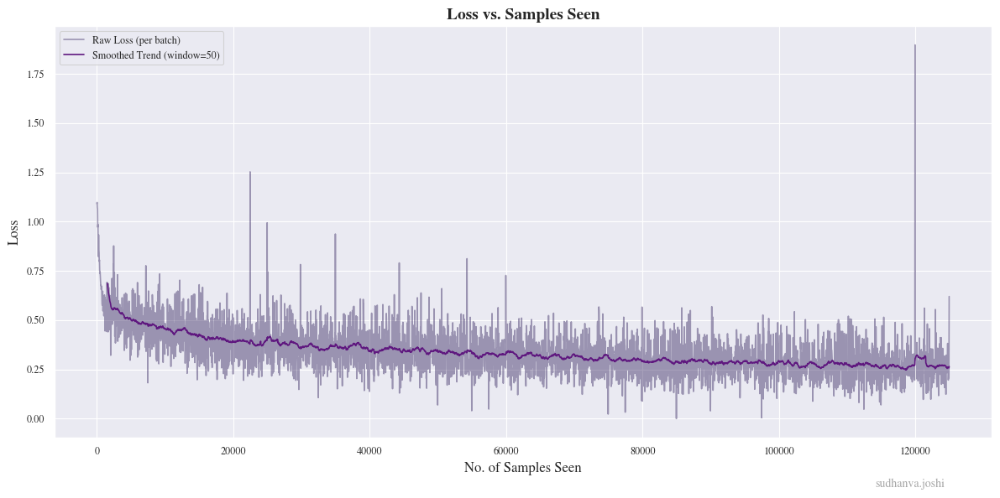

Saving final model.
Model saved to runs-q1/iili904m/final_model.npz
Model has 3297 trainable parameters.
Final accuracy: 88.40%
Final Loss: 0.2643334728433994

Final Pixel Accuracy: 88.40%


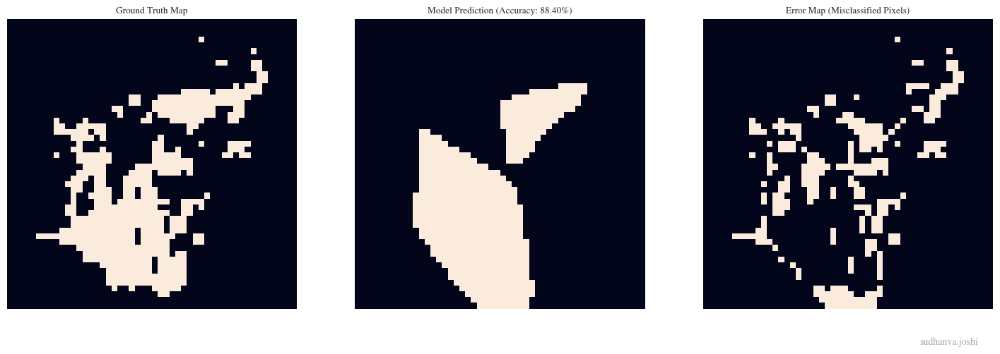

batch_size,32
final_accuracy,0.884
final_loss,0.26433
grad_steps,1
learning_rate,0.00041
samples_to_converge,125000
time_to_converge,2.80097
total_parameters,3297


wandb: Agent Starting Run: 7g95lni9 with config:
wandb: 	batch_size: 64
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00026968719716844944
wandb: 	width: 32



Sweep Run
Config: Depth=4, Width=32, LR=0.0003, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.27s.


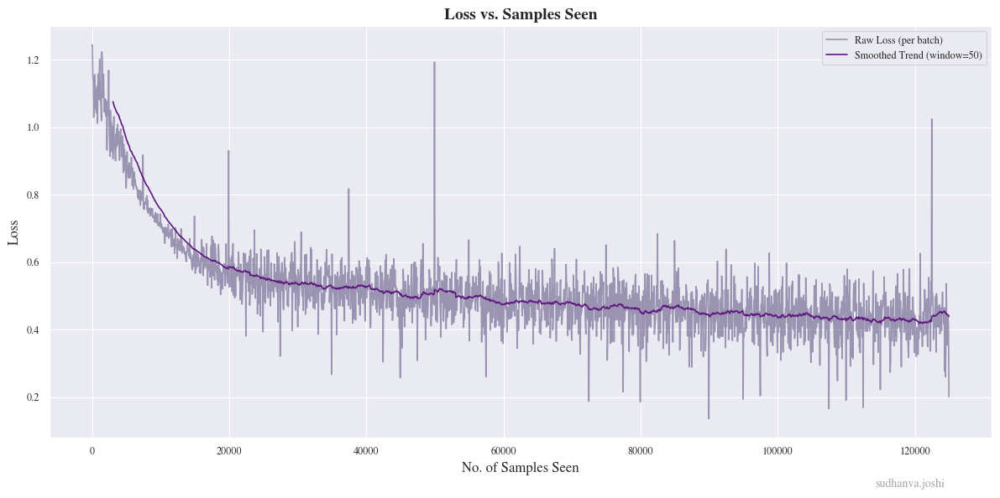

Saving final model.
Model saved to runs-q1/7g95lni9/final_model.npz
Model has 2241 trainable parameters.
Final accuracy: 80.92%
Final Loss: 0.42765049087842244

Final Pixel Accuracy: 80.92%


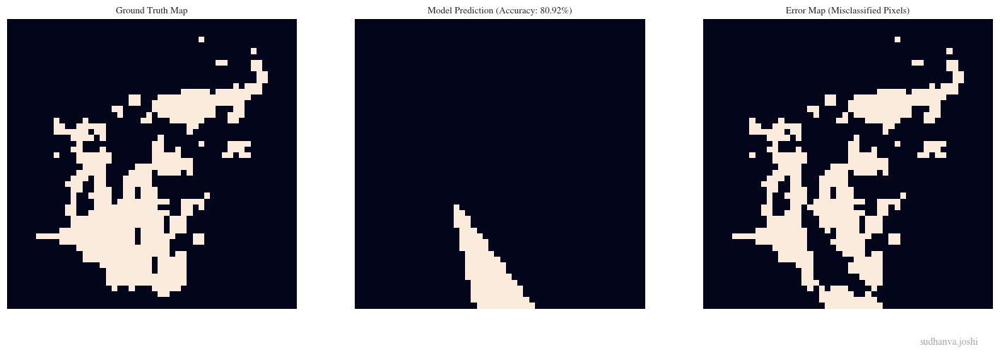

batch_size,64
final_accuracy,0.8092
final_loss,0.42765
grad_steps,4
learning_rate,0.00027
samples_to_converge,125000
time_to_converge,1.27456
total_parameters,2241


wandb: Agent Starting Run: 37xhxl6b with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0004559703402176626
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0005, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 2.25s.


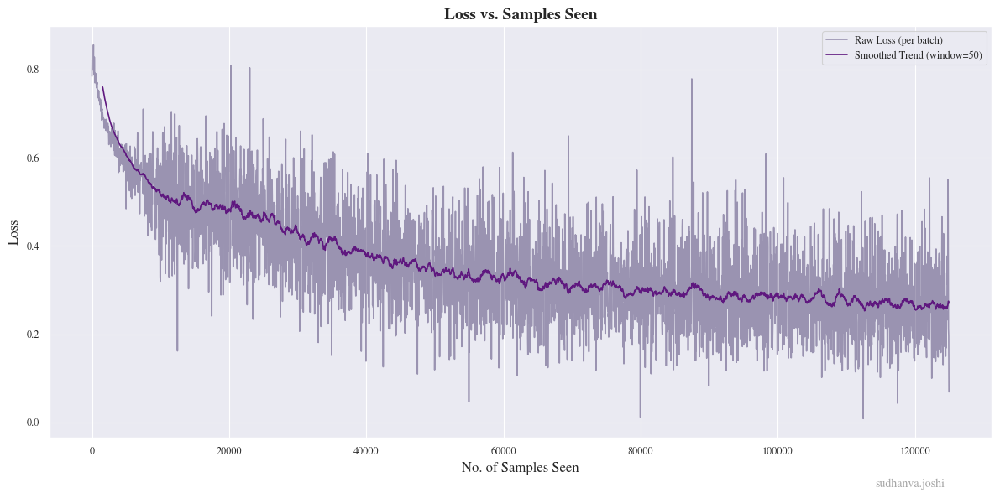

Saving final model.
Model saved to runs-q1/37xhxl6b/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 88.72%
Final Loss: 0.2665815898347325

Final Pixel Accuracy: 88.72%


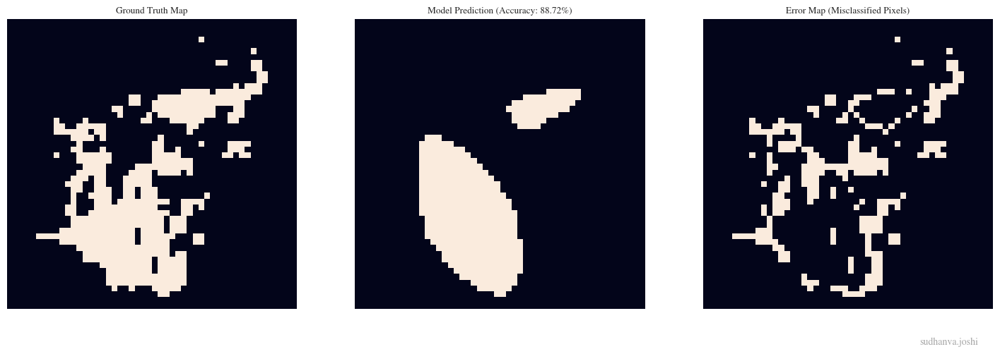

batch_size,32
final_accuracy,0.8872
final_loss,0.26658
grad_steps,4
learning_rate,0.00046
samples_to_converge,125000
time_to_converge,2.24542
total_parameters,4353


wandb: Agent Starting Run: 0hfzhubf with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0009175296209715926
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0009, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 1.43s.


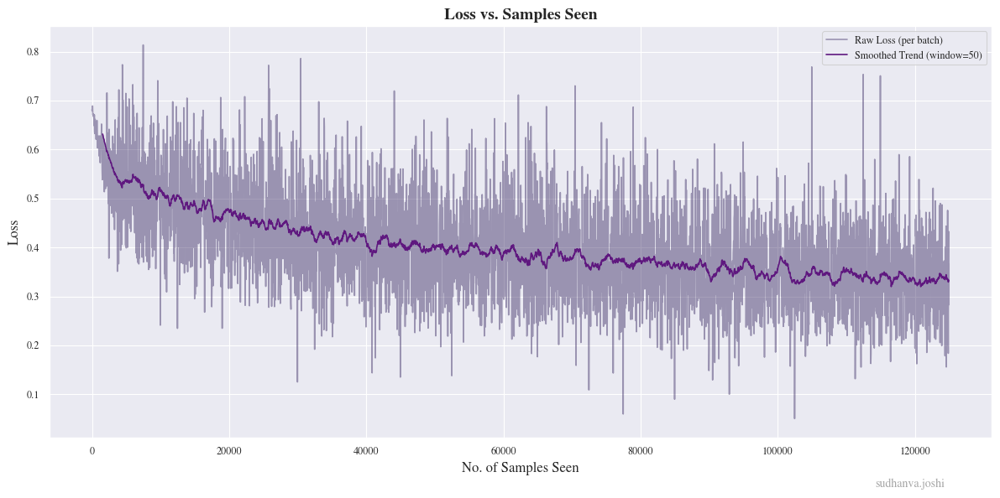

Saving final model.
Model saved to runs-q1/0hfzhubf/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 84.24%
Final Loss: 0.3294213035044377

Final Pixel Accuracy: 84.24%


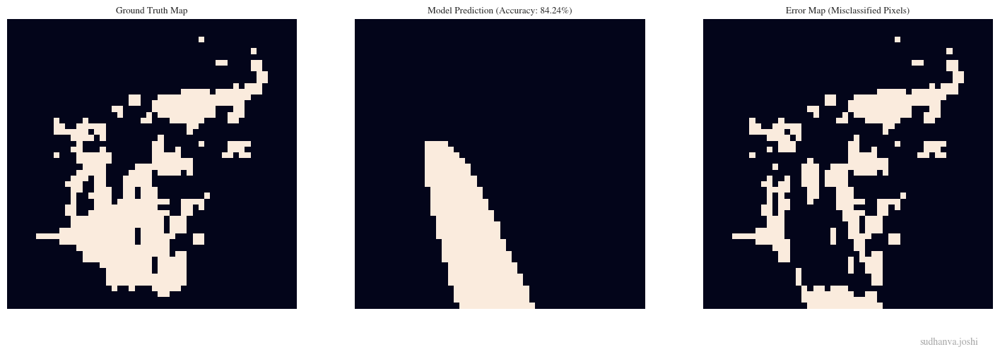

batch_size,32
final_accuracy,0.8424
final_loss,0.32942
grad_steps,4
learning_rate,0.00092
samples_to_converge,125000
time_to_converge,1.42623
total_parameters,1185


wandb: Agent Starting Run: o80qg4ip with config:
wandb: 	batch_size: 128
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.00014313613176270907
wandb: 	width: 128



Sweep Run
Config: Depth=5, Width=128, LR=0.0001, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 21.60s.


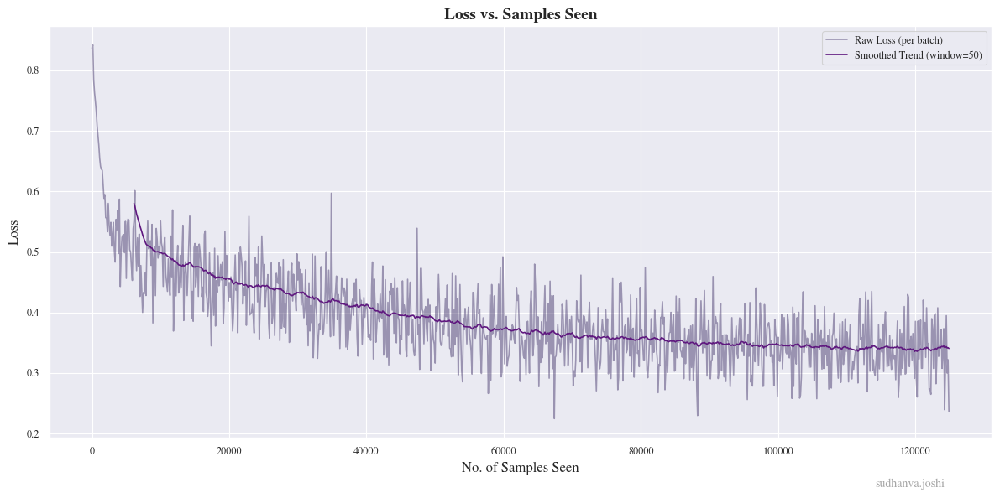

Saving final model.
Model saved to runs-q1/o80qg4ip/final_model.npz
Model has 50049 trainable parameters.
Final accuracy: 84.20%
Final Loss: 0.3371789990443976

Final Pixel Accuracy: 84.20%


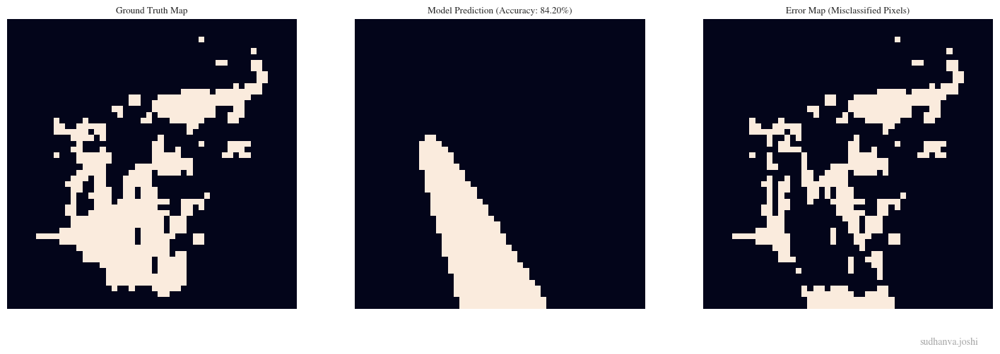

batch_size,128
final_accuracy,0.842
final_loss,0.33718
grad_steps,1
learning_rate,0.00014
samples_to_converge,125000
time_to_converge,21.59879
total_parameters,50049


wandb: Agent Starting Run: 4uznbta8 with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0005380535709418349
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0005, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 3.12s.


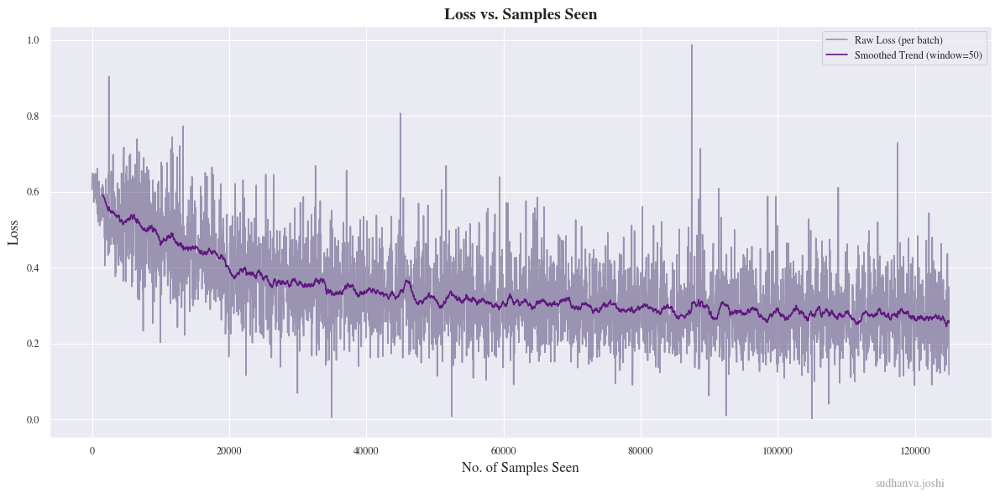

Saving final model.
Model saved to runs-q1/4uznbta8/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 88.96%
Final Loss: 0.2650573772915931

Final Pixel Accuracy: 88.96%


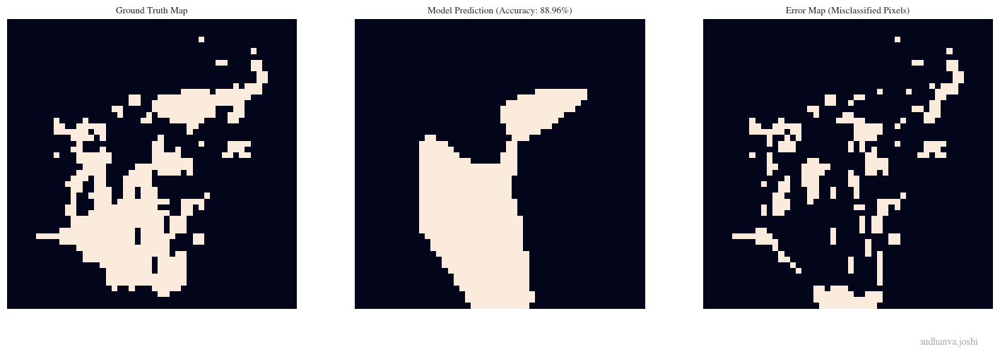

batch_size,32
final_accuracy,0.8896
final_loss,0.26506
grad_steps,4
learning_rate,0.00054
samples_to_converge,125000
time_to_converge,3.11985
total_parameters,4353


wandb: Agent Starting Run: wvpn8624 with config:
wandb: 	batch_size: 128
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00026159199028131353
wandb: 	width: 256



Sweep Run
Config: Depth=3, Width=256, LR=0.0003, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 12.18s.


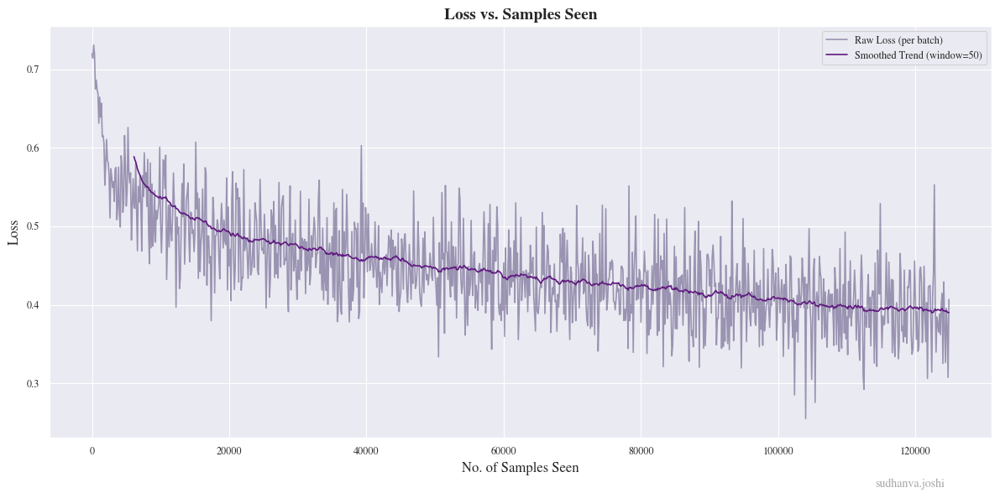

Saving final model.
Model saved to runs-q1/wvpn8624/final_model.npz
Model has 66817 trainable parameters.
Final accuracy: 83.72%
Final Loss: 0.3882963321603658

Final Pixel Accuracy: 83.72%


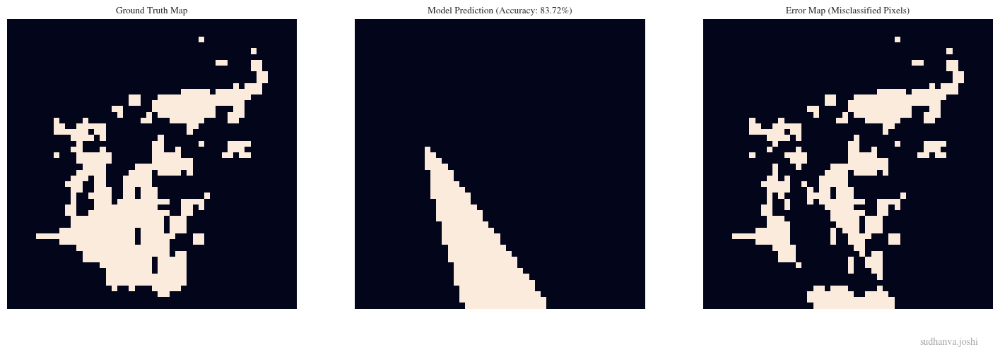

batch_size,128
final_accuracy,0.8372
final_loss,0.3883
grad_steps,4
learning_rate,0.00026
samples_to_converge,125000
time_to_converge,12.17877
total_parameters,66817


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: 2msoo9xy with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0001106769434930362
wandb: 	width: 128



Sweep Run
Config: Depth=6, Width=128, LR=0.0001, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 29.52s.


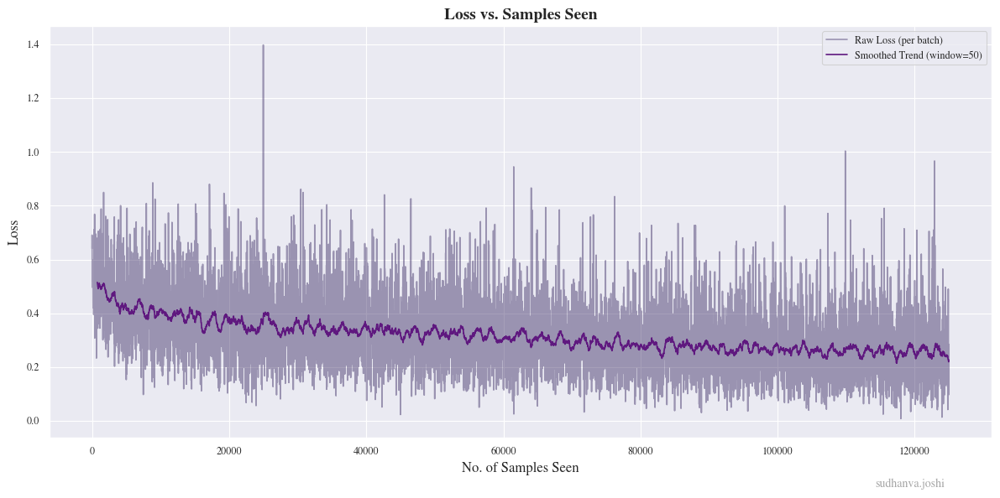

Saving final model.
Model saved to runs-q1/2msoo9xy/final_model.npz
Model has 66561 trainable parameters.
Final accuracy: 89.44%
Final Loss: 0.25348377834963265

Final Pixel Accuracy: 89.44%


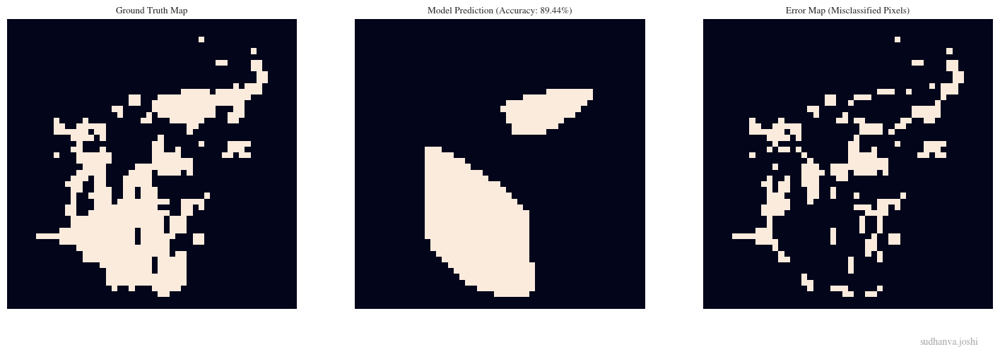

batch_size,16
final_accuracy,0.8944
final_loss,0.25348
grad_steps,1
learning_rate,0.00011
samples_to_converge,125000
time_to_converge,29.52091
total_parameters,66561


wandb: Agent Starting Run: ucttuoy1 with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007041127793734457
wandb: 	width: 128



Sweep Run
Config: Depth=6, Width=128, LR=0.0007, Batch=16



Early stopping triggered at epoch 49.
Epoch 49 complete. Total samples seen: 122500. Time: 17.39s.


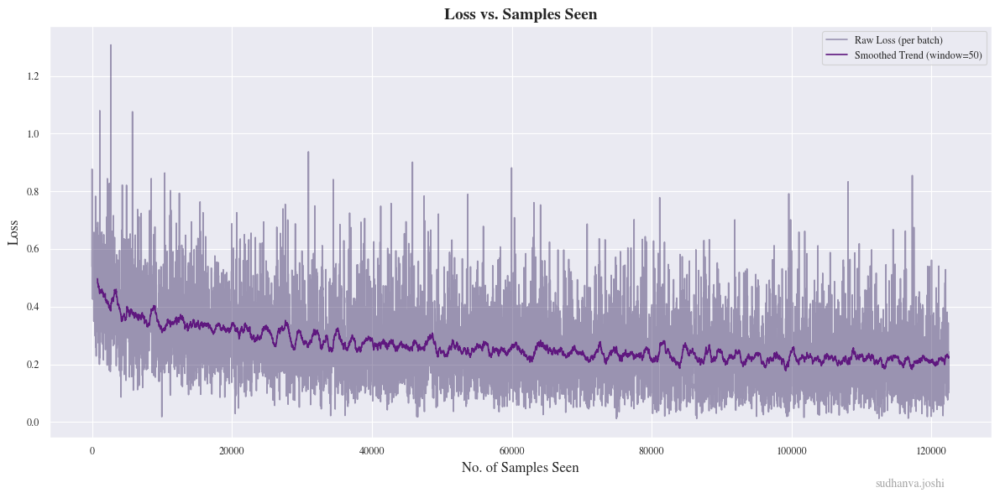

Saving final model.
Model saved to runs-q1/ucttuoy1/final_model.npz
Model has 66561 trainable parameters.
Final accuracy: 91.72%
Final Loss: 0.21586221133435396

Final Pixel Accuracy: 91.72%


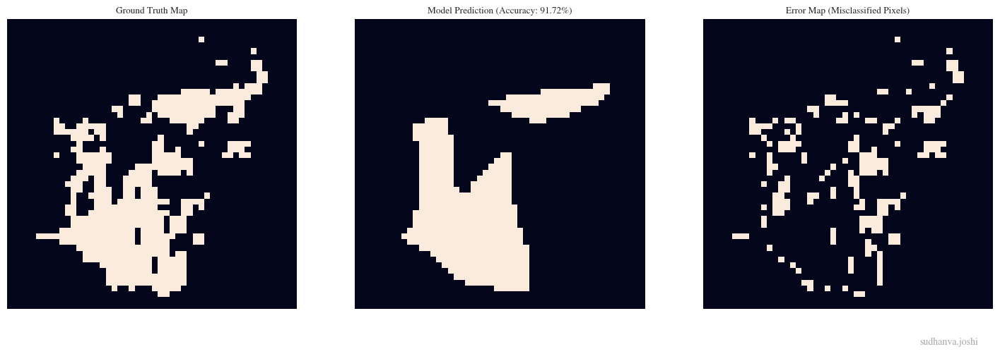

batch_size,16
final_accuracy,0.9172
final_loss,0.21586
grad_steps,1
learning_rate,0.0007
samples_to_converge,122500
time_to_converge,17.39276
total_parameters,66561


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: 5v7vhagj with config:
wandb: 	batch_size: 128
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0006936359308478549
wandb: 	width: 128



Sweep Run
Config: Depth=3, Width=128, LR=0.0007, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 7.45s.


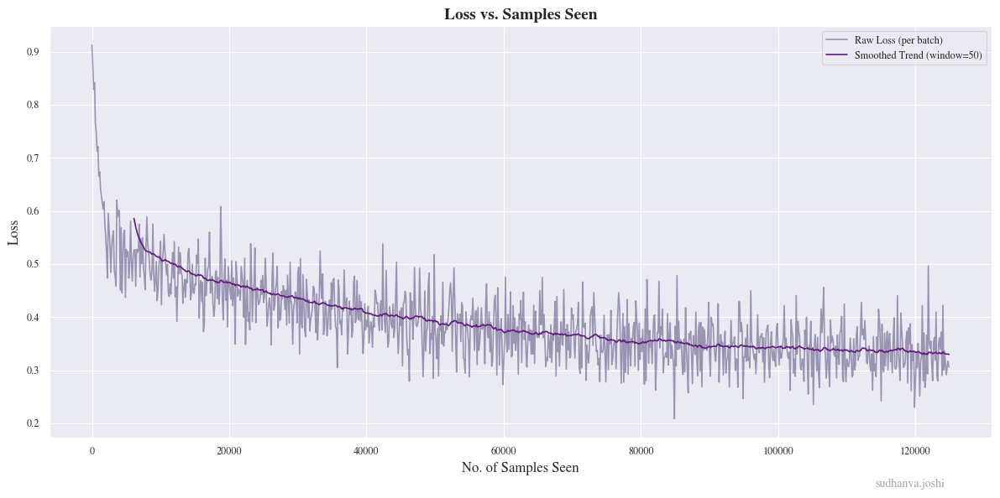

Saving final model.
Model saved to runs-q1/5v7vhagj/final_model.npz
Model has 17025 trainable parameters.
Final accuracy: 84.24%
Final Loss: 0.3302390619589167

Final Pixel Accuracy: 84.24%


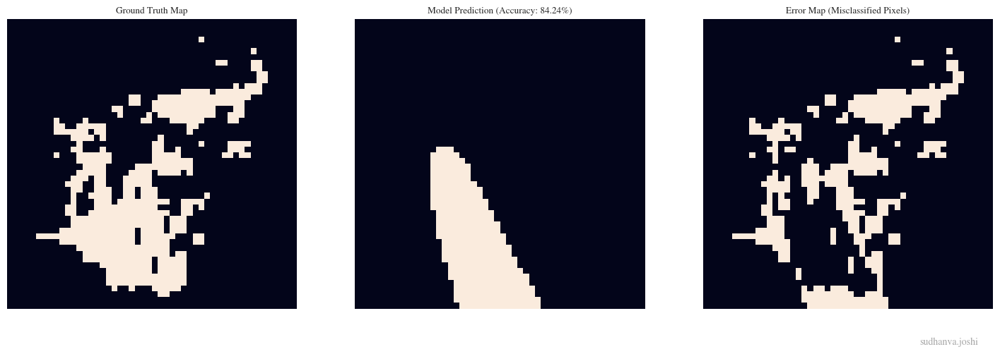

batch_size,128
final_accuracy,0.8424
final_loss,0.33024
grad_steps,2
learning_rate,0.00069
samples_to_converge,125000
time_to_converge,7.44649
total_parameters,17025


wandb: Agent Starting Run: 0ac22weo with config:
wandb: 	batch_size: 64
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0004348627702561766
wandb: 	width: 64



Sweep Run
Config: Depth=6, Width=64, LR=0.0004, Batch=64



Early stopping triggered at epoch 29.
Epoch 29 complete. Total samples seen: 72500. Time: 1.48s.


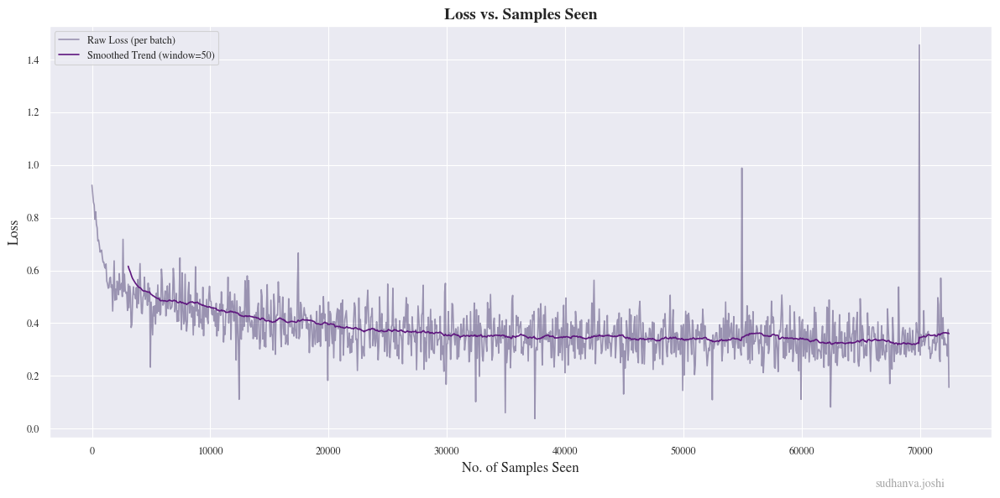

Saving final model.
Model saved to runs-q1/0ac22weo/final_model.npz
Model has 16897 trainable parameters.
Final accuracy: 84.84%
Final Loss: 0.3428310850163418

Final Pixel Accuracy: 84.84%


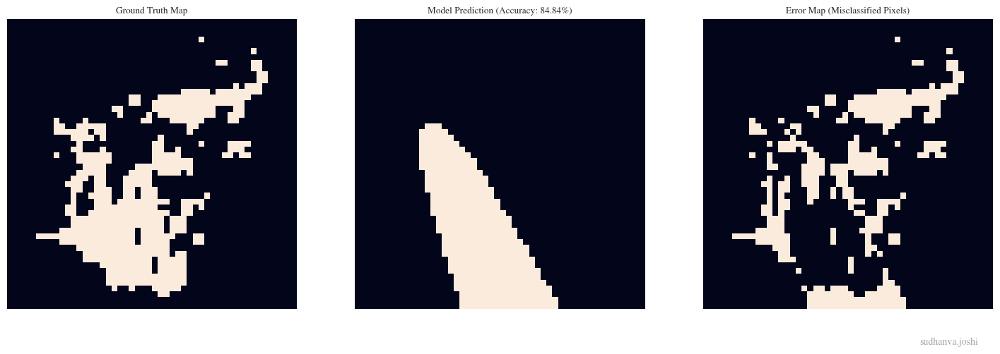

batch_size,64
final_accuracy,0.8484
final_loss,0.34283
grad_steps,2
learning_rate,0.00043
samples_to_converge,72500
time_to_converge,1.48419
total_parameters,16897


wandb: Agent Starting Run: jbav0p53 with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0007657701804300421
wandb: 	width: 64



Sweep Run
Config: Depth=3, Width=64, LR=0.0008, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 2.11s.


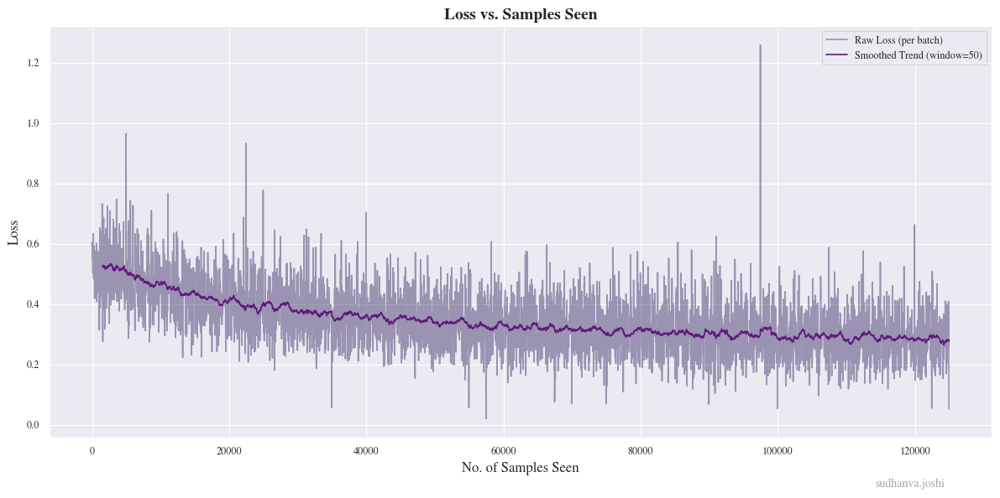

Saving final model.
Model saved to runs-q1/jbav0p53/final_model.npz
Model has 4417 trainable parameters.
Final accuracy: 87.36%
Final Loss: 0.28225265117008896

Final Pixel Accuracy: 87.36%


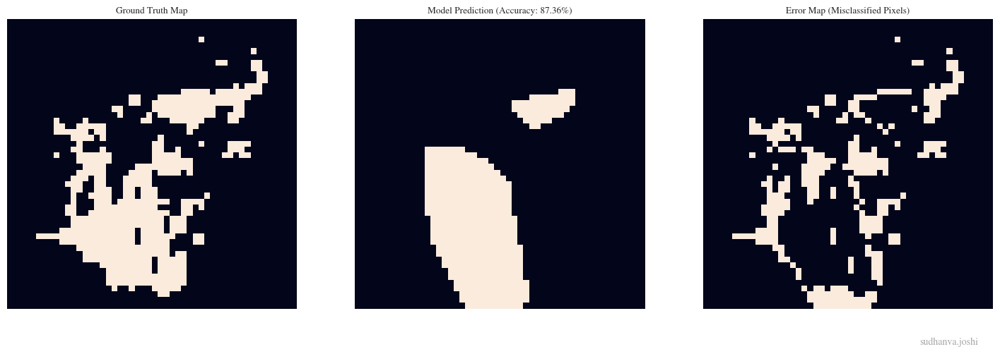

batch_size,32
final_accuracy,0.8736
final_loss,0.28225
grad_steps,2
learning_rate,0.00077
samples_to_converge,125000
time_to_converge,2.11035
total_parameters,4417


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: kchsj9r3 with config:
wandb: 	batch_size: 64
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0003936773522983001
wandb: 	width: 256



Sweep Run
Config: Depth=5, Width=256, LR=0.0004, Batch=64



Early stopping triggered at epoch 36.
Epoch 36 complete. Total samples seen: 90000. Time: 41.44s.


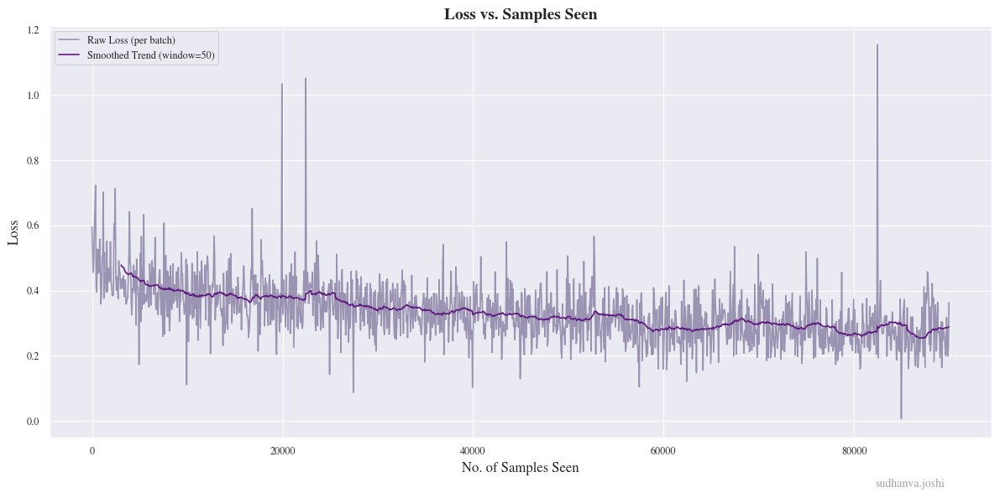

Saving final model.
Model saved to runs-q1/kchsj9r3/final_model.npz
Model has 198401 trainable parameters.
Final accuracy: 87.28%
Final Loss: 0.29290512848137423

Final Pixel Accuracy: 87.28%


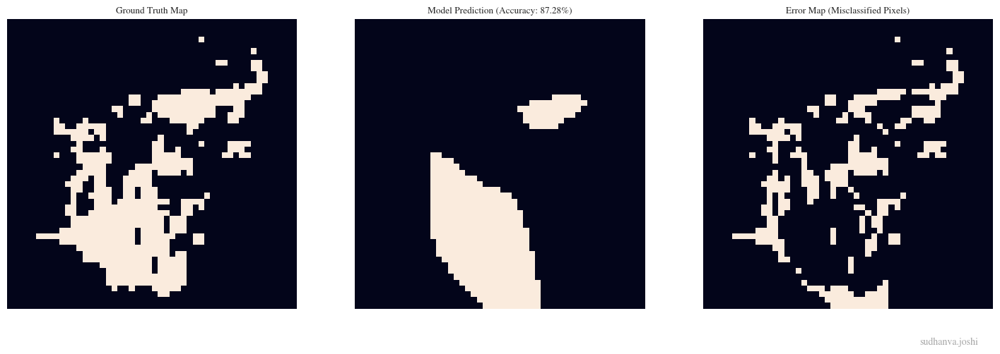

batch_size,64
final_accuracy,0.8728
final_loss,0.29291
grad_steps,1
learning_rate,0.00039
samples_to_converge,90000
time_to_converge,41.44208
total_parameters,198401


wandb: Agent Starting Run: v2zrq1y1 with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0008924381169581006
wandb: 	width: 256



Sweep Run
Config: Depth=3, Width=256, LR=0.0009, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 22.89s.


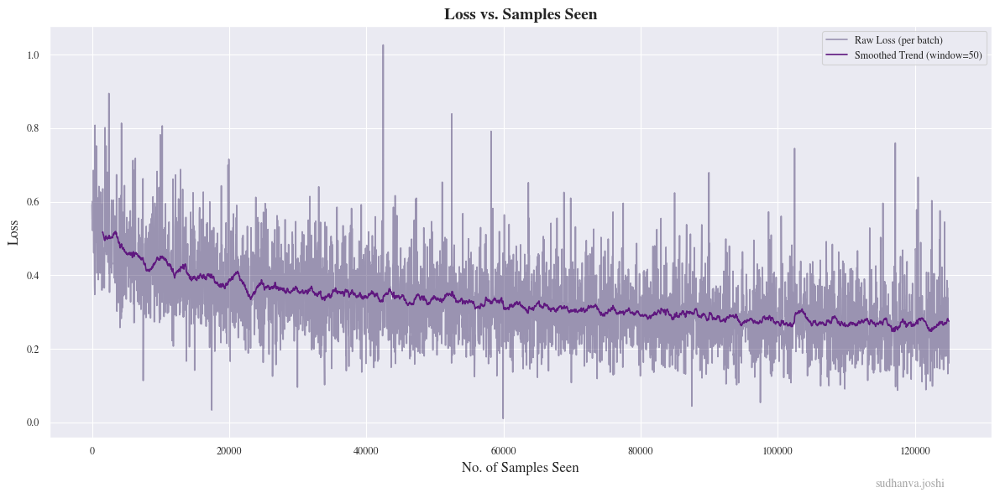

Saving final model.
Model saved to runs-q1/v2zrq1y1/final_model.npz
Model has 66817 trainable parameters.
Final accuracy: 88.24%
Final Loss: 0.2682934044492998

Final Pixel Accuracy: 88.24%


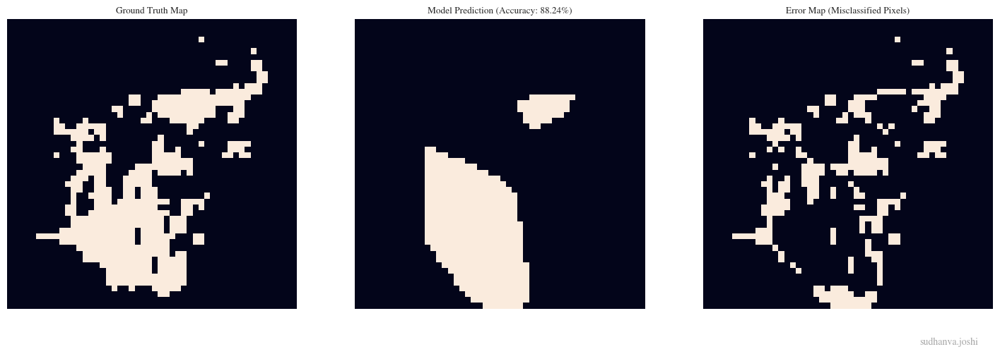

batch_size,32
final_accuracy,0.8824
final_loss,0.26829
grad_steps,4
learning_rate,0.00089
samples_to_converge,125000
time_to_converge,22.88667
total_parameters,66817


wandb: Agent Starting Run: pb1eo6wm with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0009360833168332496
wandb: 	width: 64



Sweep Run
Config: Depth=6, Width=64, LR=0.0009, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 3.44s.


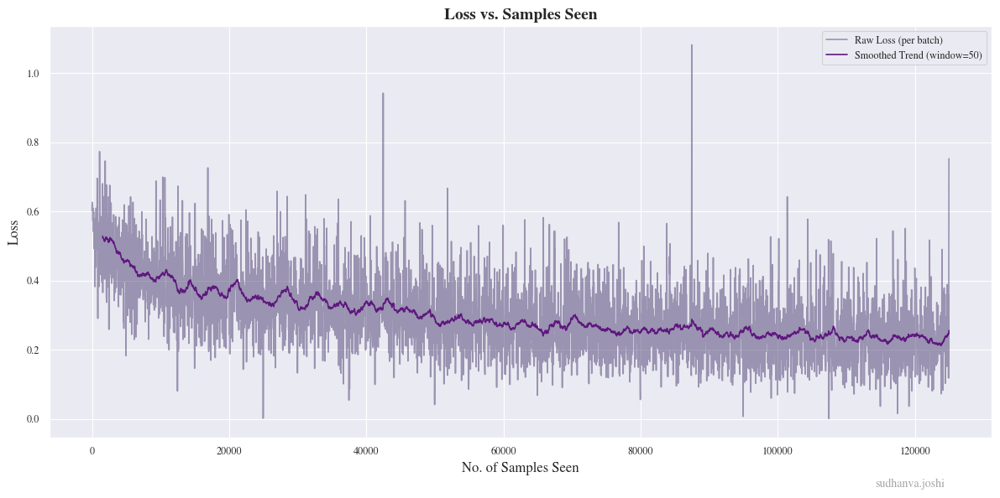

Saving final model.
Model saved to runs-q1/pb1eo6wm/final_model.npz
Model has 16897 trainable parameters.
Final accuracy: 89.72%
Final Loss: 0.229501234201728

Final Pixel Accuracy: 89.72%


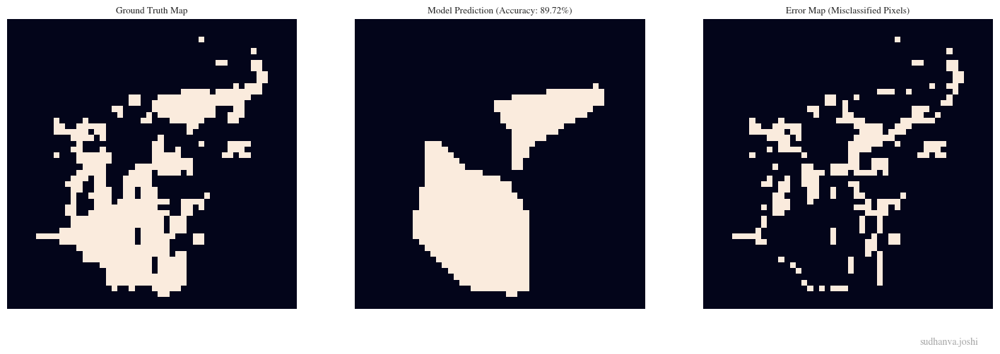

batch_size,32
final_accuracy,0.8972
final_loss,0.2295
grad_steps,4
learning_rate,0.00094
samples_to_converge,125000
time_to_converge,3.4368
total_parameters,16897


wandb: Agent Starting Run: sb1zi7ki with config:
wandb: 	batch_size: 32
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0001998035737608641
wandb: 	width: 64



Sweep Run
Config: Depth=5, Width=64, LR=0.0002, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 4.09s.


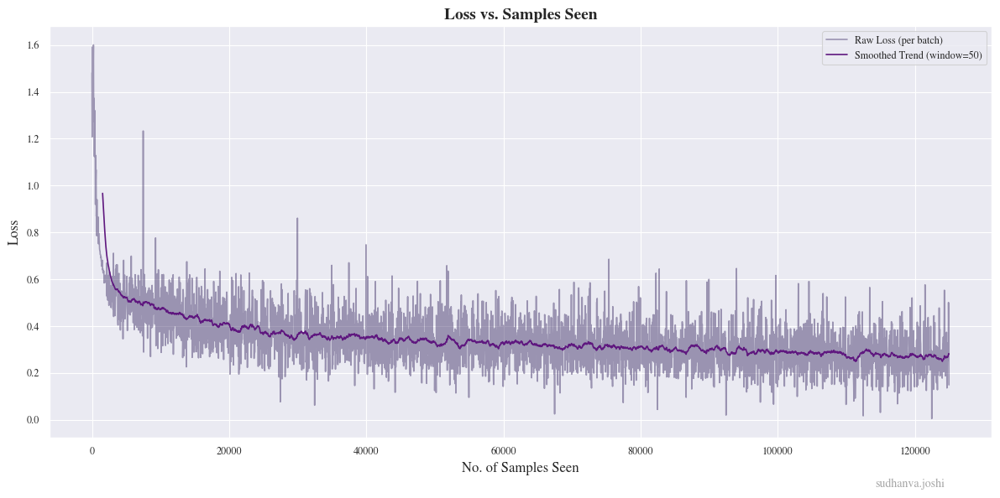

Saving final model.
Model saved to runs-q1/sb1zi7ki/final_model.npz
Model has 12737 trainable parameters.
Final accuracy: 88.44%
Final Loss: 0.2721708820429432

Final Pixel Accuracy: 88.44%


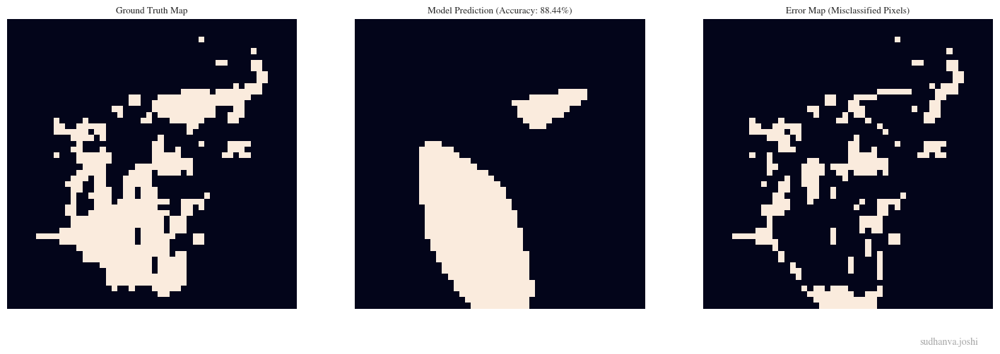

batch_size,32
final_accuracy,0.8844
final_loss,0.27217
grad_steps,1
learning_rate,0.0002
samples_to_converge,125000
time_to_converge,4.09037
total_parameters,12737


wandb: Agent Starting Run: fk6iv9tm with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0005174417064049473
wandb: 	width: 256



Sweep Run
Config: Depth=3, Width=256, LR=0.0005, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 21.59s.


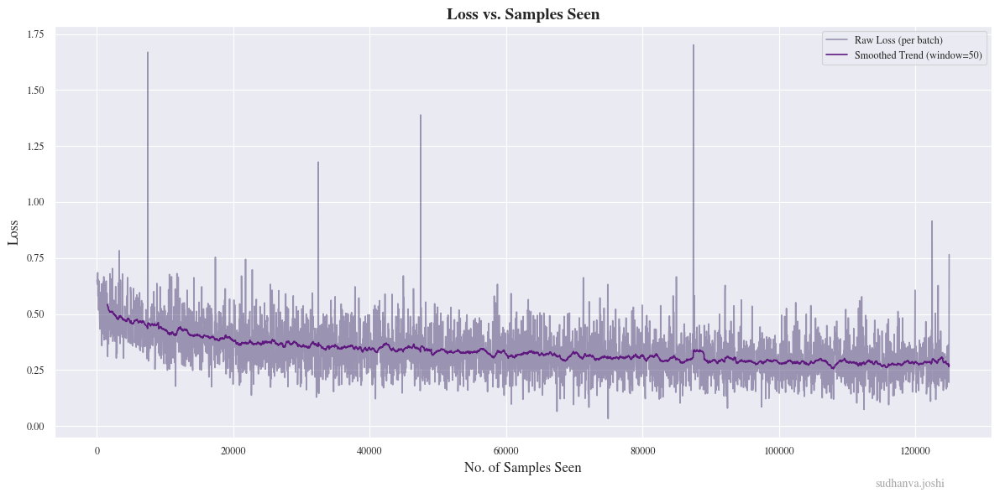

Saving final model.
Model saved to runs-q1/fk6iv9tm/final_model.npz
Model has 66817 trainable parameters.
Final accuracy: 88.04%
Final Loss: 0.2771054352067857

Final Pixel Accuracy: 88.04%


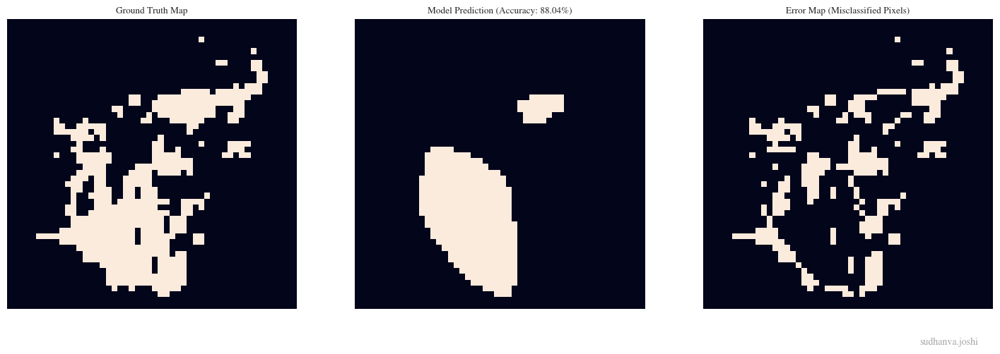

batch_size,32
final_accuracy,0.8804
final_loss,0.27711
grad_steps,2
learning_rate,0.00052
samples_to_converge,125000
time_to_converge,21.58796
total_parameters,66817


wandb: Agent Starting Run: x6ulem0c with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.00016609723952815028
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0002, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 3.65s.


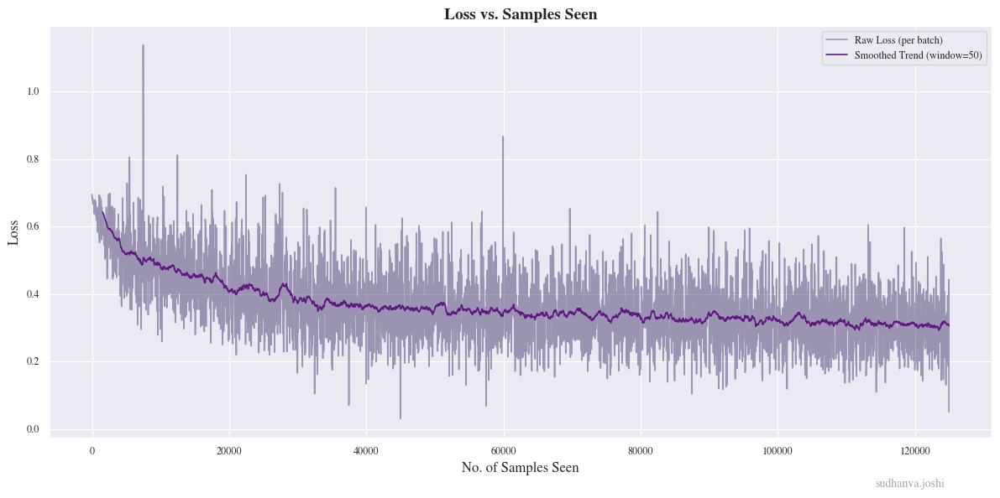

Saving final model.
Model saved to runs-q1/x6ulem0c/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 85.20%
Final Loss: 0.305886877268337

Final Pixel Accuracy: 85.20%


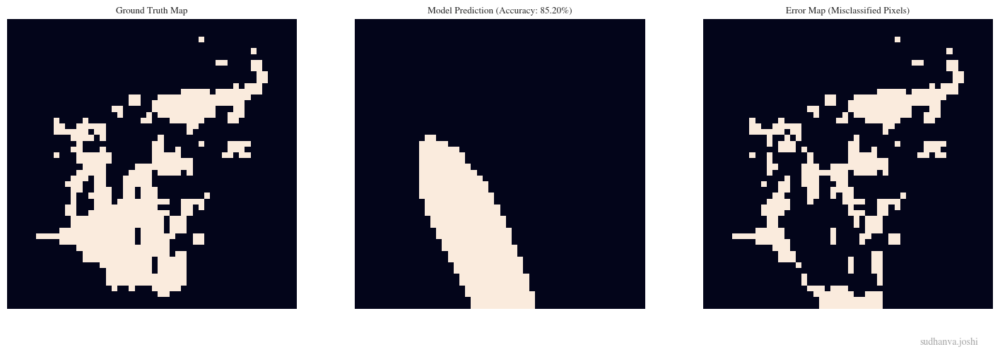

batch_size,32
final_accuracy,0.852
final_loss,0.30589
grad_steps,1
learning_rate,0.00017
samples_to_converge,125000
time_to_converge,3.65451
total_parameters,4353


wandb: Agent Starting Run: xypx52bx with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007772385702282722
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0008, Batch=32



Early stopping triggered at epoch 35.
Epoch 35 complete. Total samples seen: 87500. Time: 2.74s.


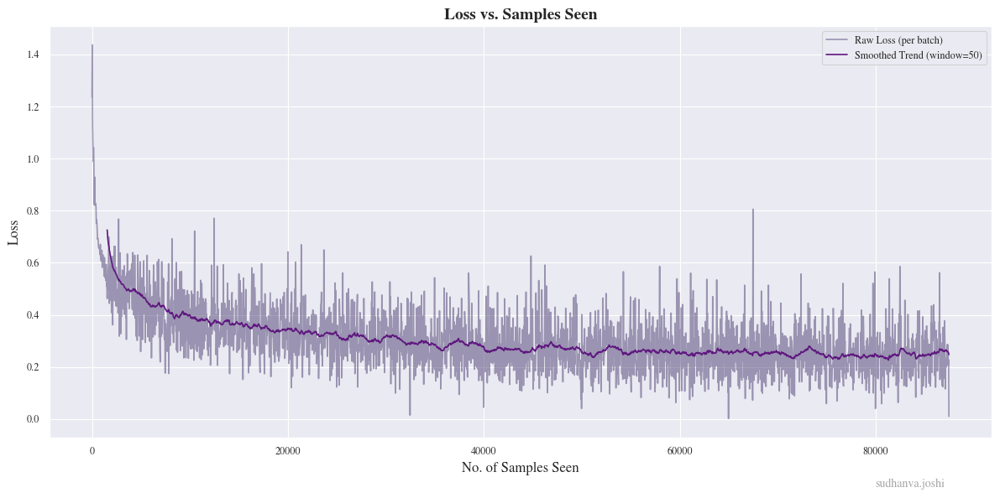

Saving final model.
Model saved to runs-q1/xypx52bx/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 88.48%
Final Loss: 0.2550642687474909

Final Pixel Accuracy: 88.48%


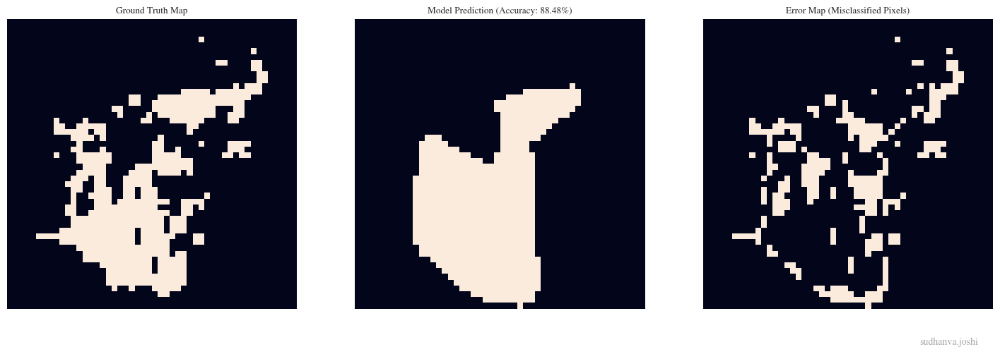

batch_size,32
final_accuracy,0.8848
final_loss,0.25506
grad_steps,1
learning_rate,0.00078
samples_to_converge,87500
time_to_converge,2.7376
total_parameters,4353


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: pnfimcy6 with config:
wandb: 	batch_size: 64
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0009222704626350598
wandb: 	width: 128



Sweep Run
Config: Depth=5, Width=128, LR=0.0009, Batch=64



Early stopping triggered at epoch 45.
Epoch 45 complete. Total samples seen: 112500. Time: 3.74s.


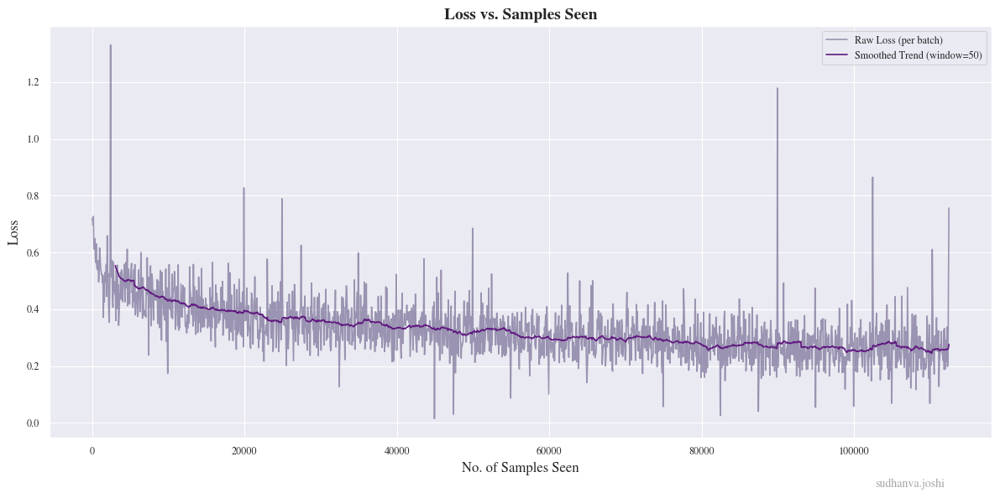

Saving final model.
Model saved to runs-q1/pnfimcy6/final_model.npz
Model has 50049 trainable parameters.
Final accuracy: 88.20%
Final Loss: 0.2748340565254374

Final Pixel Accuracy: 88.20%


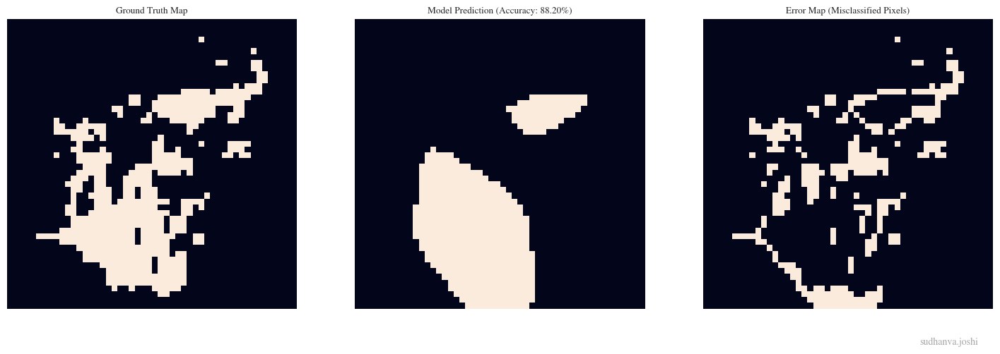

batch_size,64
final_accuracy,0.882
final_loss,0.27483
grad_steps,4
learning_rate,0.00092
samples_to_converge,112500
time_to_converge,3.74411
total_parameters,50049


wandb: Agent Starting Run: a0b25ux3 with config:
wandb: 	batch_size: 16
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0008520786451149166
wandb: 	width: 64



Sweep Run
Config: Depth=5, Width=64, LR=0.0009, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 6.26s.


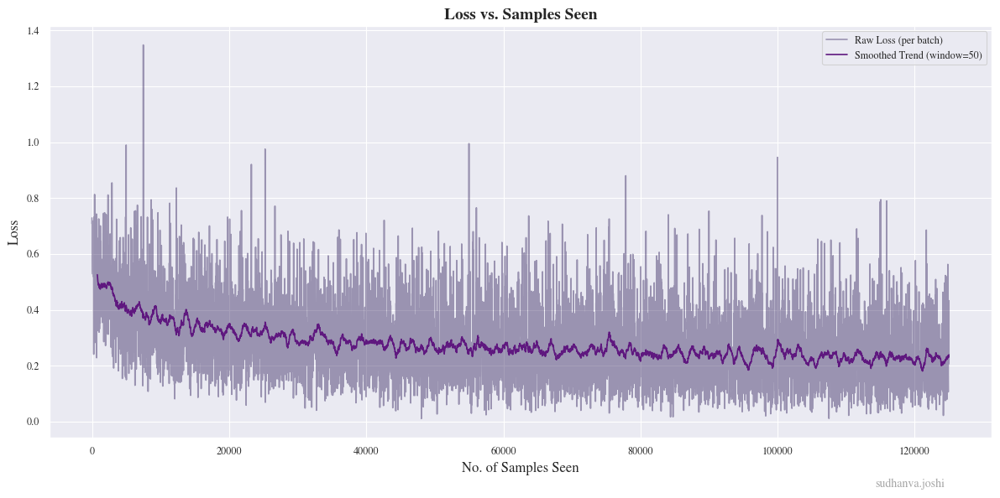

Saving final model.
Model saved to runs-q1/a0b25ux3/final_model.npz
Model has 12737 trainable parameters.
Final accuracy: 88.36%
Final Loss: 0.227357518672286

Final Pixel Accuracy: 88.36%


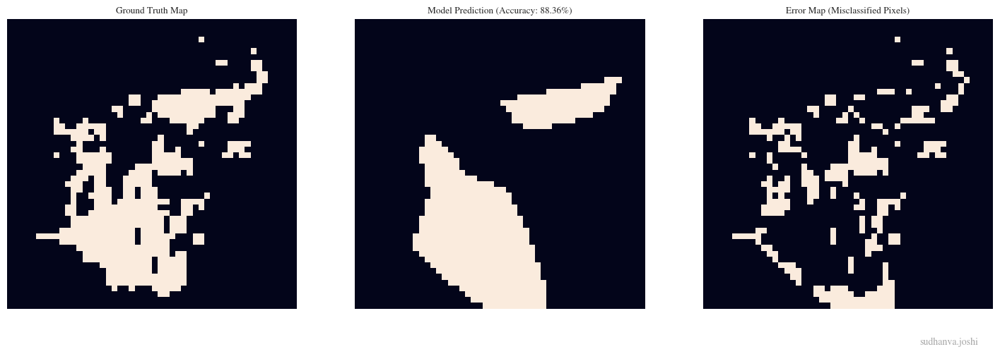

batch_size,16
final_accuracy,0.8836
final_loss,0.22736
grad_steps,2
learning_rate,0.00085
samples_to_converge,125000
time_to_converge,6.26106
total_parameters,12737


wandb: Agent Starting Run: onx7ptoo with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0009037801218961336
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0009, Batch=16



Early stopping triggered at epoch 32.
Epoch 32 complete. Total samples seen: 80000. Time: 2.80s.


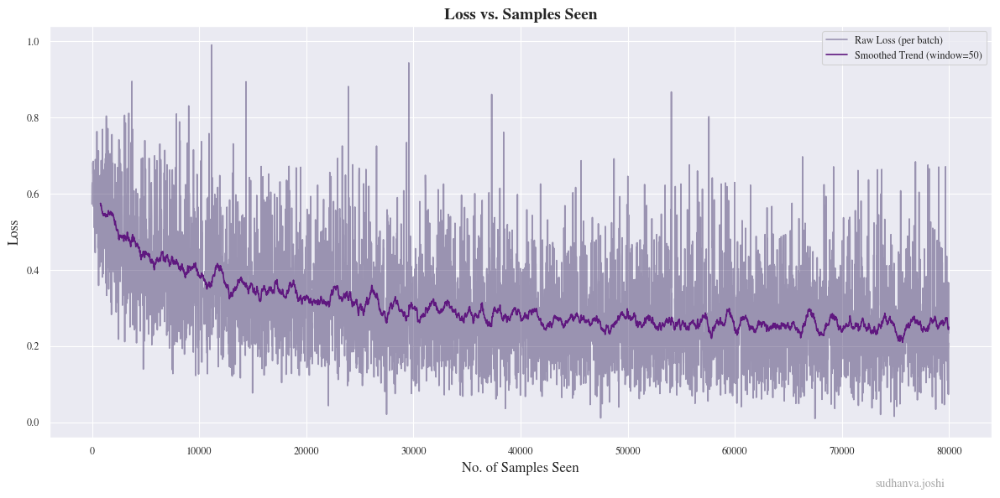

Saving final model.
Model saved to runs-q1/onx7ptoo/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 89.60%
Final Loss: 0.25866401321157645

Final Pixel Accuracy: 89.60%


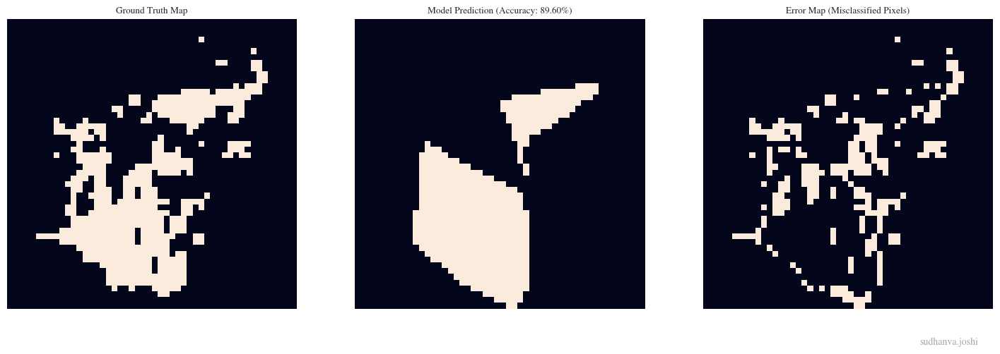

batch_size,16
final_accuracy,0.896
final_loss,0.25866
grad_steps,4
learning_rate,0.0009
samples_to_converge,80000
time_to_converge,2.79789
total_parameters,4353


wandb: Agent Starting Run: ewkxk5jl with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0006019018568105036
wandb: 	width: 32



Sweep Run
Config: Depth=4, Width=32, LR=0.0006, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 4.13s.


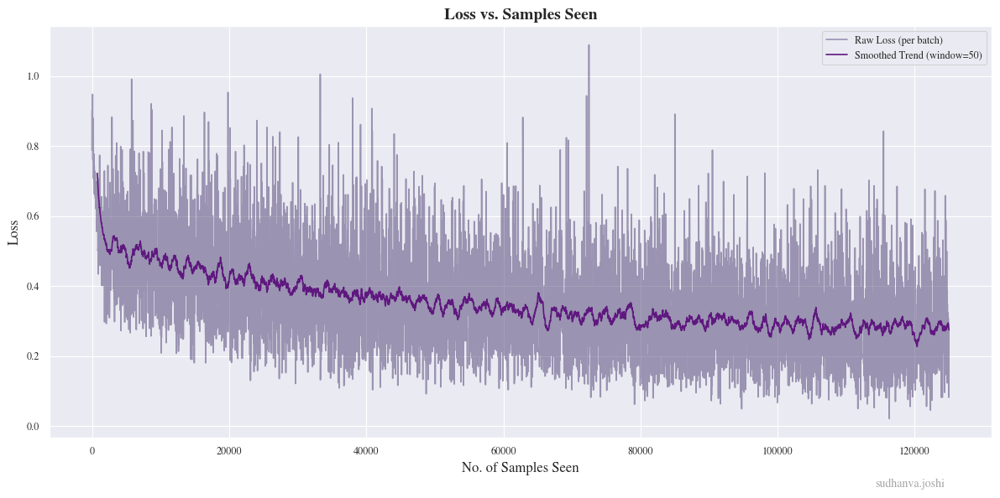

Saving final model.
Model saved to runs-q1/ewkxk5jl/final_model.npz
Model has 2241 trainable parameters.
Final accuracy: 87.20%
Final Loss: 0.28048870792736585

Final Pixel Accuracy: 87.20%


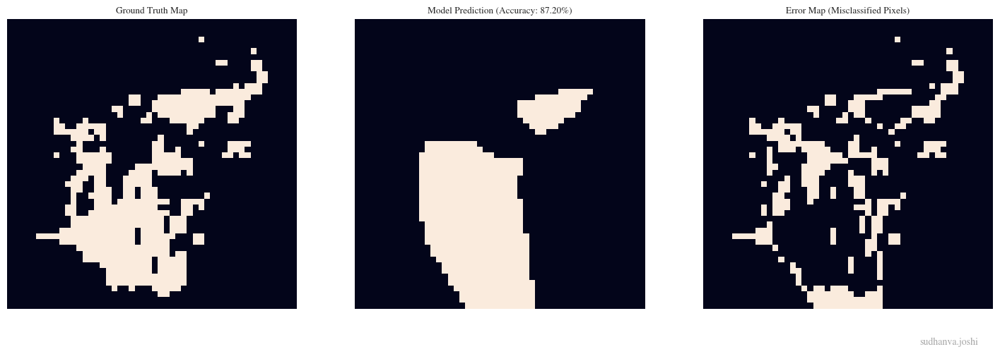

batch_size,16
final_accuracy,0.872
final_loss,0.28049
grad_steps,2
learning_rate,0.0006
samples_to_converge,125000
time_to_converge,4.1312
total_parameters,2241


wandb: Agent Starting Run: x24648kl with config:
wandb: 	batch_size: 16
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.000883885648342739
wandb: 	width: 32



Sweep Run
Config: Depth=5, Width=32, LR=0.0009, Batch=16



Early stopping triggered at epoch 39.
Epoch 39 complete. Total samples seen: 97500. Time: 3.58s.


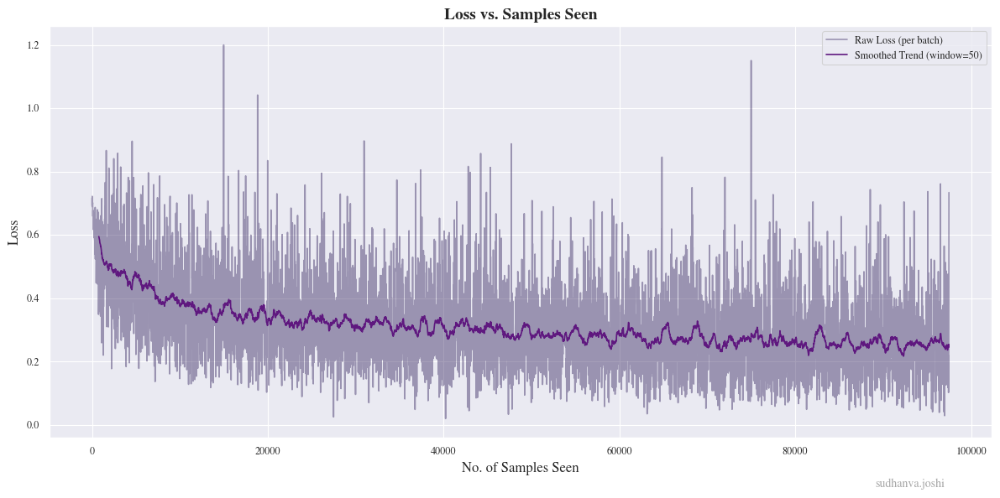

Saving final model.
Model saved to runs-q1/x24648kl/final_model.npz
Model has 3297 trainable parameters.
Final accuracy: 89.00%
Final Loss: 0.2617841379142939

Final Pixel Accuracy: 89.00%


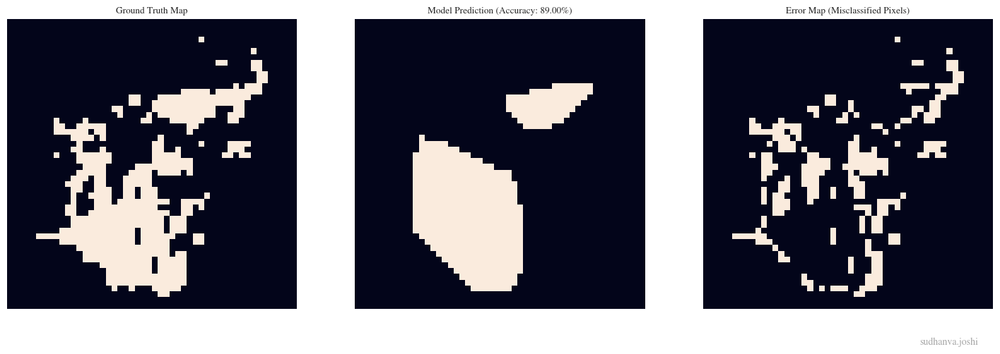

batch_size,16
final_accuracy,0.89
final_loss,0.26178
grad_steps,2
learning_rate,0.00088
samples_to_converge,97500
time_to_converge,3.57673
total_parameters,3297


wandb: Agent Starting Run: g842bcnn with config:
wandb: 	batch_size: 64
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0006315857580801608
wandb: 	width: 64



Sweep Run
Config: Depth=3, Width=64, LR=0.0006, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.47s.


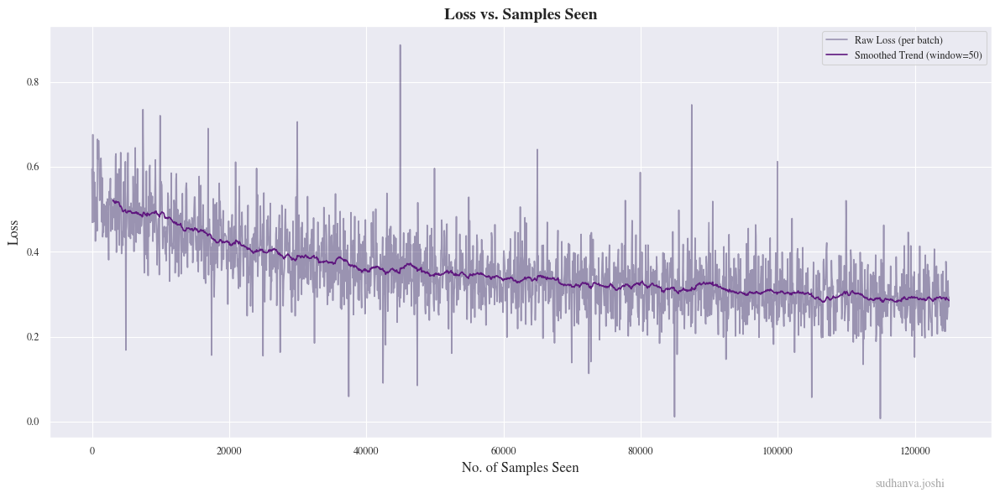

Saving final model.
Model saved to runs-q1/g842bcnn/final_model.npz
Model has 4417 trainable parameters.
Final accuracy: 86.68%
Final Loss: 0.2882641290718124

Final Pixel Accuracy: 86.68%


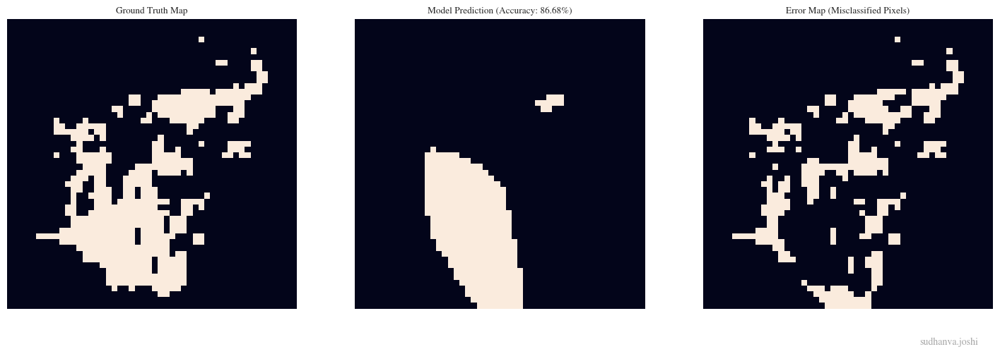

batch_size,64
final_accuracy,0.8668
final_loss,0.28826
grad_steps,1
learning_rate,0.00063
samples_to_converge,125000
time_to_converge,1.47052
total_parameters,4417


wandb: Agent Starting Run: kwxeo3an with config:
wandb: 	batch_size: 128
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00021762600425742393
wandb: 	width: 64



Sweep Run
Config: Depth=5, Width=64, LR=0.0002, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 1.46s.


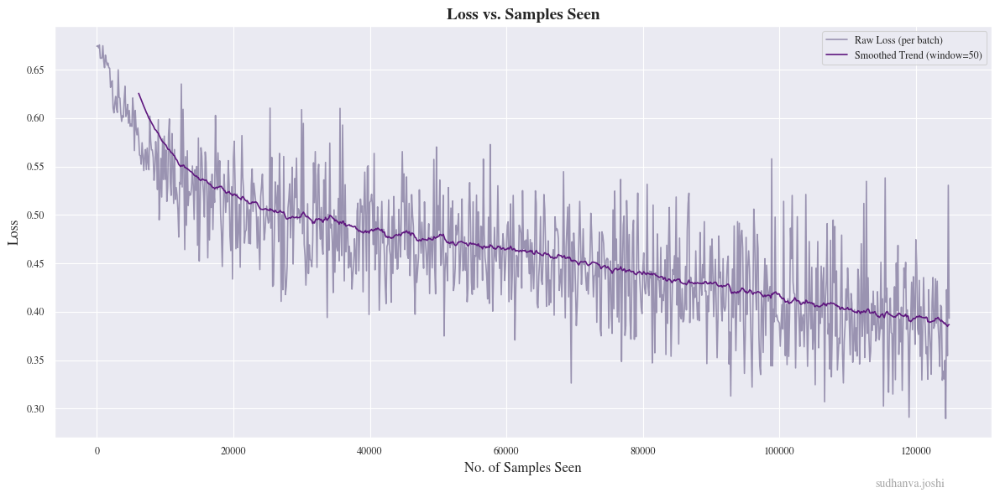

Saving final model.
Model saved to runs-q1/kwxeo3an/final_model.npz
Model has 12737 trainable parameters.
Final accuracy: 83.12%
Final Loss: 0.3853929677477402

Final Pixel Accuracy: 83.12%


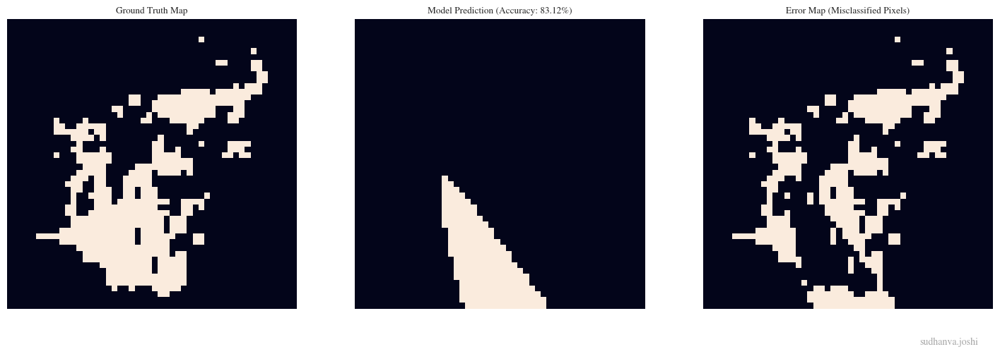

batch_size,128
final_accuracy,0.8312
final_loss,0.38539
grad_steps,4
learning_rate,0.00022
samples_to_converge,125000
time_to_converge,1.45607
total_parameters,12737


wandb: Agent Starting Run: 33qe3rq6 with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0008080973296534623
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0008, Batch=16



Early stopping triggered at epoch 44.
Epoch 44 complete. Total samples seen: 110000. Time: 39.98s.


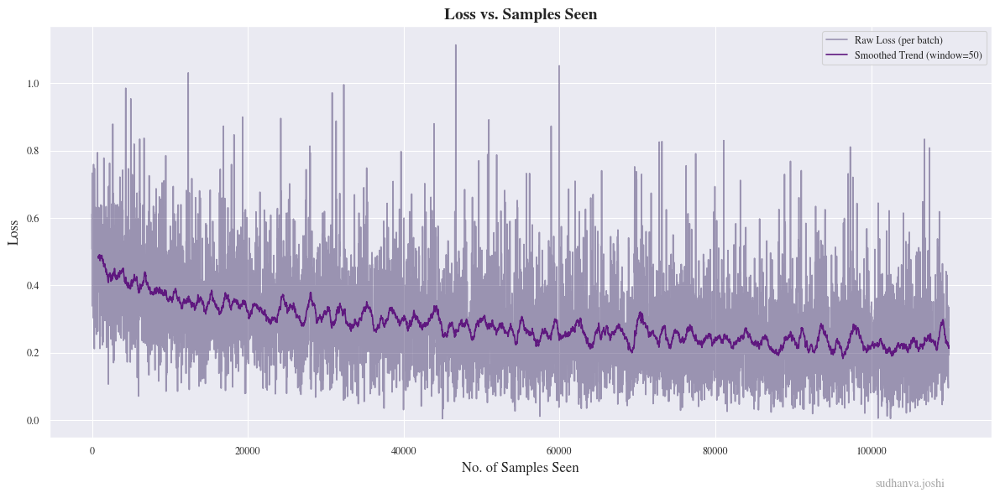

Saving final model.
Model saved to runs-q1/33qe3rq6/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 90.52%
Final Loss: 0.24229494875042515

Final Pixel Accuracy: 90.52%


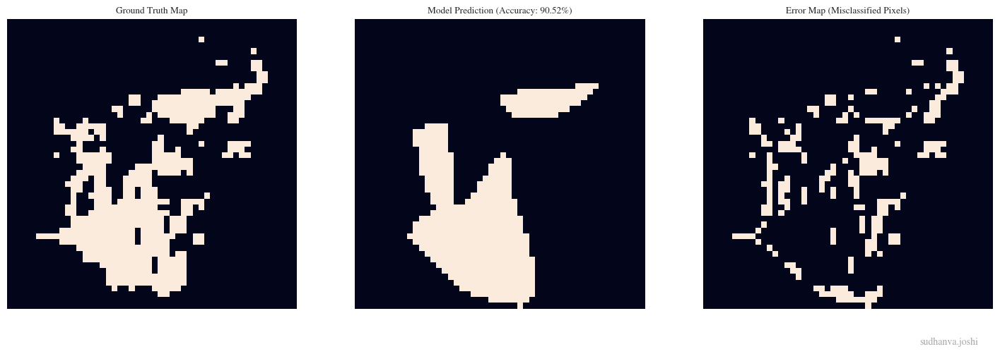

batch_size,16
final_accuracy,0.9052
final_loss,0.24229
grad_steps,2
learning_rate,0.00081
samples_to_converge,110000
time_to_converge,39.9785
total_parameters,264193


wandb: Agent Starting Run: hfsc5pj5 with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.00042158830403360214
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0004, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 4.93s.


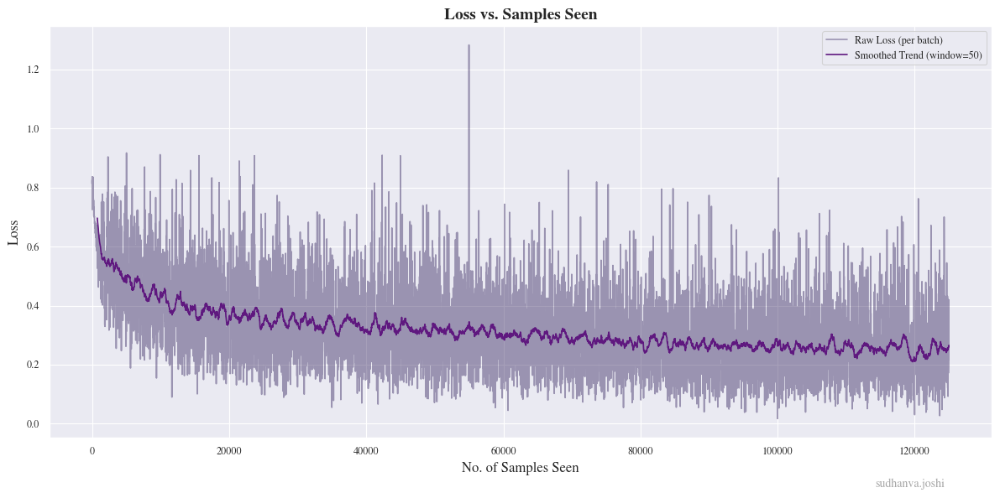

Saving final model.
Model saved to runs-q1/hfsc5pj5/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 89.56%
Final Loss: 0.2530596827513791

Final Pixel Accuracy: 89.56%


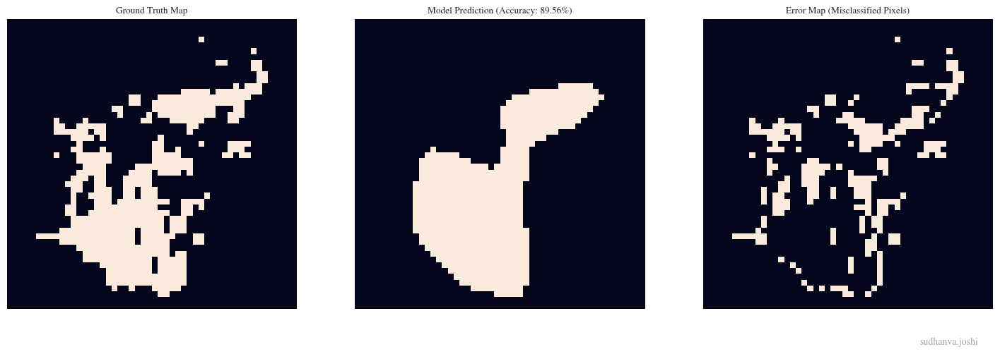

batch_size,16
final_accuracy,0.8956
final_loss,0.25306
grad_steps,2
learning_rate,0.00042
samples_to_converge,125000
time_to_converge,4.92731
total_parameters,4353


wandb: Agent Starting Run: h2182bq7 with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0009571033213582748
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0010, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 23.76s.


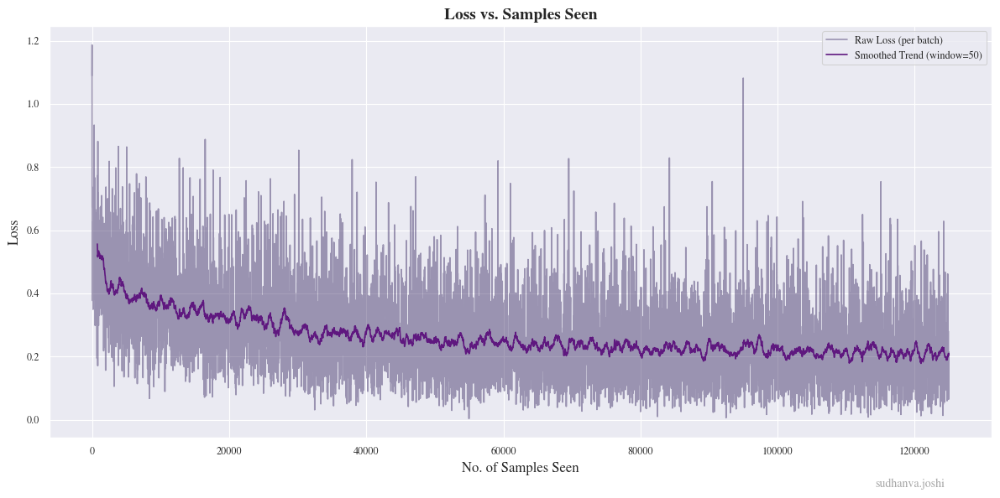

Saving final model.
Model saved to runs-q1/h2182bq7/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 91.40%
Final Loss: 0.2078783457126617

Final Pixel Accuracy: 91.40%


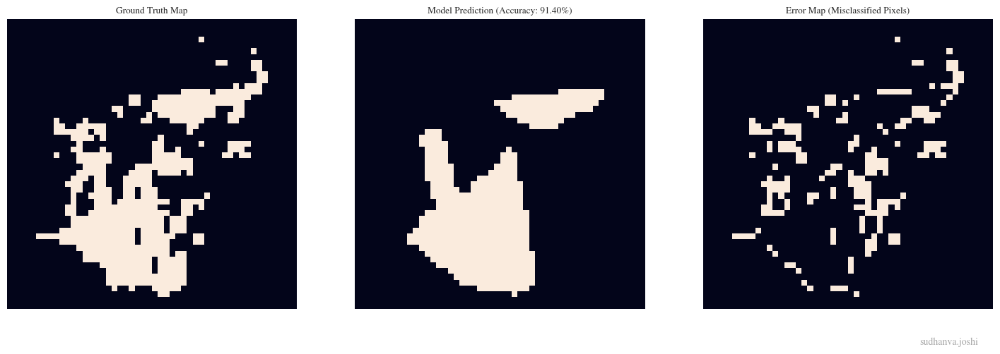

batch_size,16
final_accuracy,0.914
final_loss,0.20788
grad_steps,2
learning_rate,0.00096
samples_to_converge,125000
time_to_converge,23.76492
total_parameters,132609


wandb: Agent Starting Run: ttdq5fue with config:
wandb: 	batch_size: 64
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0004535402229330224
wandb: 	width: 64



Sweep Run
Config: Depth=4, Width=64, LR=0.0005, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.87s.


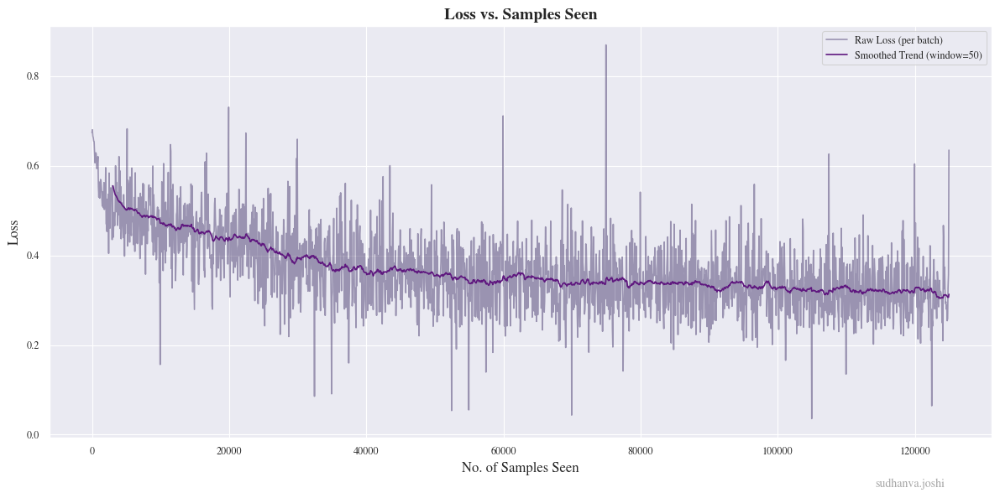

Saving final model.
Model saved to runs-q1/ttdq5fue/final_model.npz
Model has 8577 trainable parameters.
Final accuracy: 84.84%
Final Loss: 0.31312713225606936

Final Pixel Accuracy: 84.84%


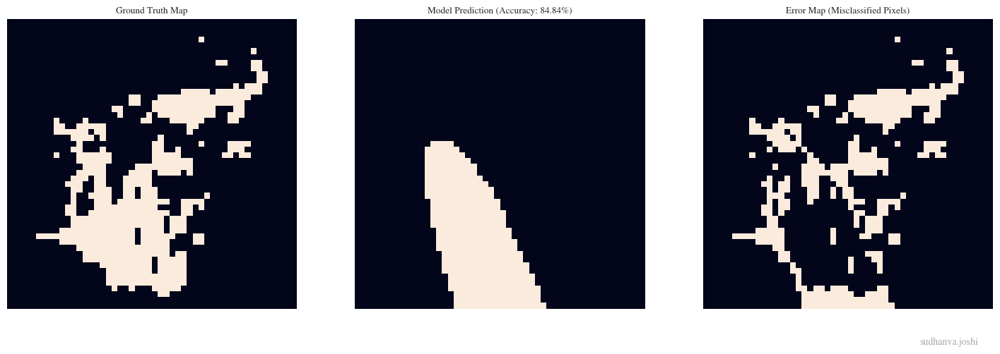

batch_size,64
final_accuracy,0.8484
final_loss,0.31313
grad_steps,2
learning_rate,0.00045
samples_to_converge,125000
time_to_converge,1.87433
total_parameters,8577


wandb: Agent Starting Run: ekfqt00d with config:
wandb: 	batch_size: 128
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0005962071310336389
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0006, Batch=128



Early stopping triggered at epoch 43.
Epoch 43 complete. Total samples seen: 107500. Time: 22.42s.


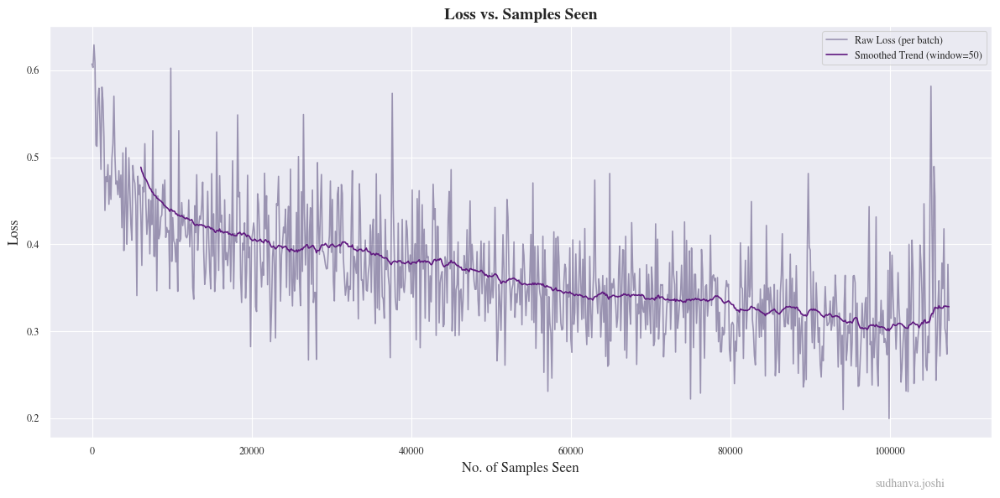

Saving final model.
Model saved to runs-q1/ekfqt00d/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 84.60%
Final Loss: 0.36173339004984073

Final Pixel Accuracy: 84.60%


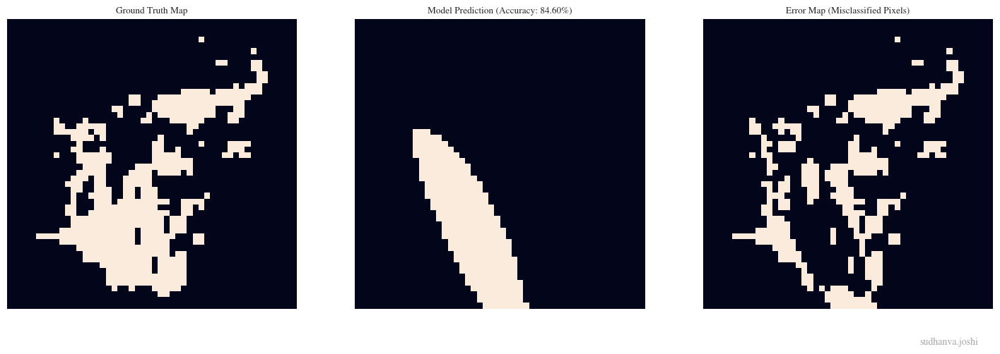

batch_size,128
final_accuracy,0.846
final_loss,0.36173
grad_steps,4
learning_rate,0.0006
samples_to_converge,107500
time_to_converge,22.42064
total_parameters,264193


wandb: Agent Starting Run: v70w3lab with config:
wandb: 	batch_size: 16
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0008563795944010226
wandb: 	width: 128



Sweep Run
Config: Depth=5, Width=128, LR=0.0009, Batch=16



Early stopping triggered at epoch 27.
Epoch 27 complete. Total samples seen: 67500. Time: 8.15s.


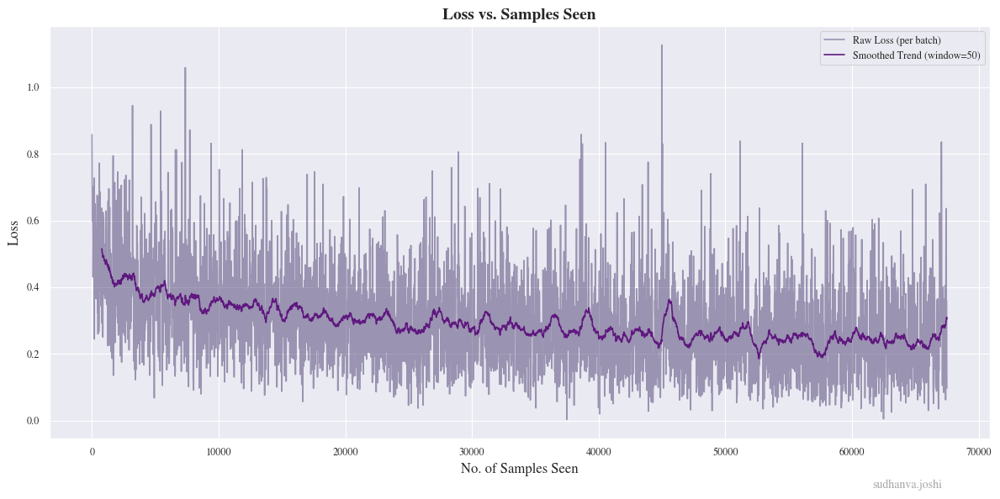

Saving final model.
Model saved to runs-q1/v70w3lab/final_model.npz
Model has 50049 trainable parameters.
Final accuracy: 88.80%
Final Loss: 0.2567791056581177

Final Pixel Accuracy: 88.80%


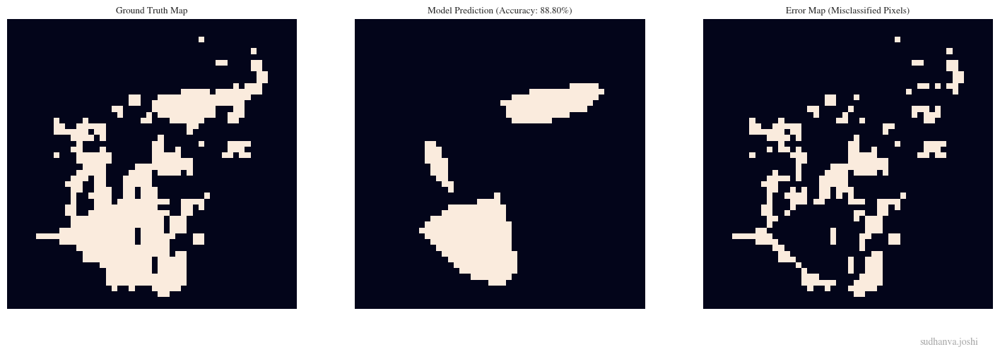

batch_size,16
final_accuracy,0.888
final_loss,0.25678
grad_steps,1
learning_rate,0.00086
samples_to_converge,67500
time_to_converge,8.15493
total_parameters,50049


wandb: Agent Starting Run: k2e00ege with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00035542636505644893
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0004, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 1.53s.


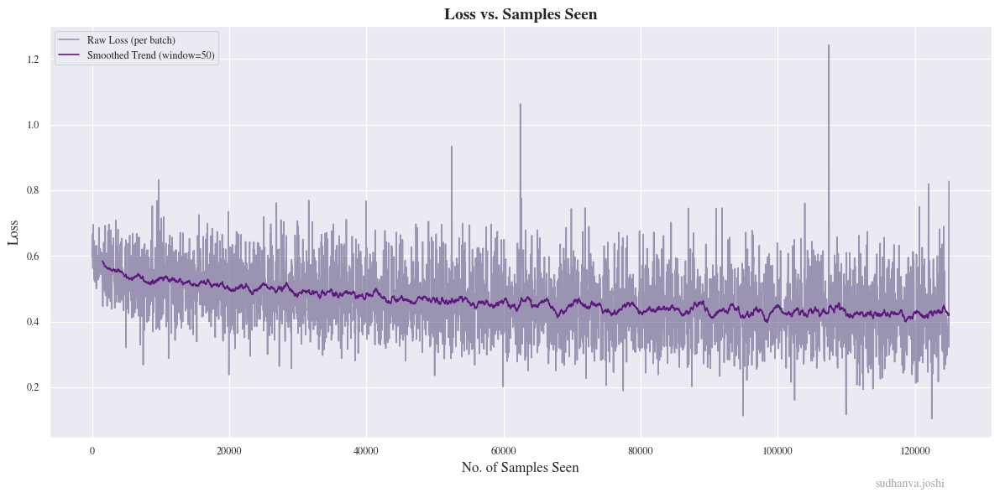

Saving final model.
Model saved to runs-q1/k2e00ege/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 81.04%
Final Loss: 0.42202971525835165

Final Pixel Accuracy: 81.04%


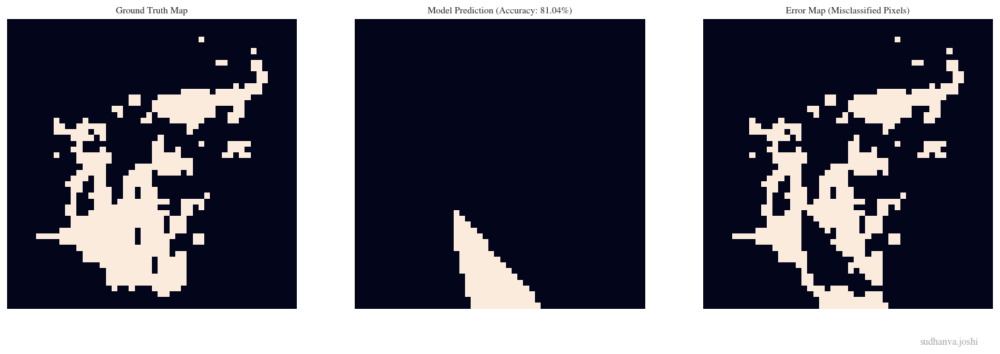

batch_size,32
final_accuracy,0.8104
final_loss,0.42203
grad_steps,4
learning_rate,0.00036
samples_to_converge,125000
time_to_converge,1.53177
total_parameters,1185


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: 7l5l77uc with config:
wandb: 	batch_size: 64
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0002130354830350263
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0002, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.32s.


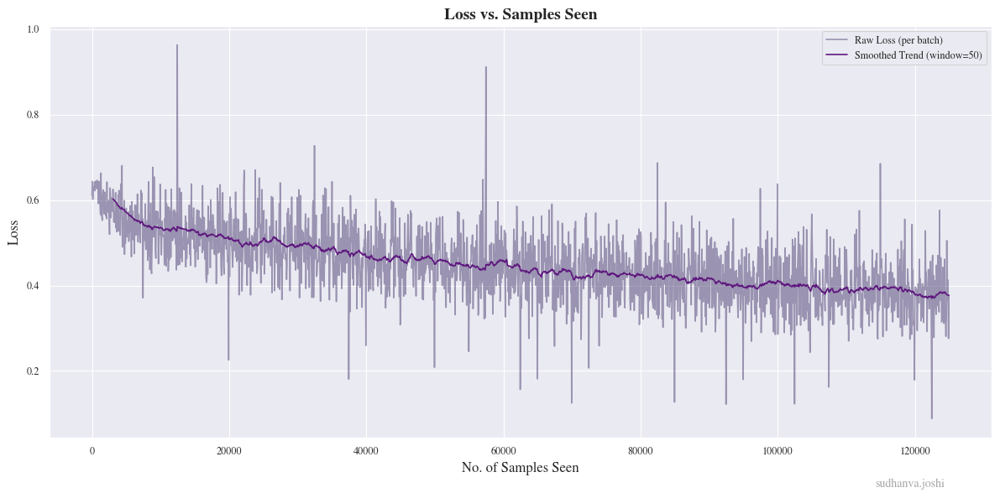

Saving final model.
Model saved to runs-q1/7l5l77uc/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 82.84%
Final Loss: 0.38215211262290943

Final Pixel Accuracy: 82.84%


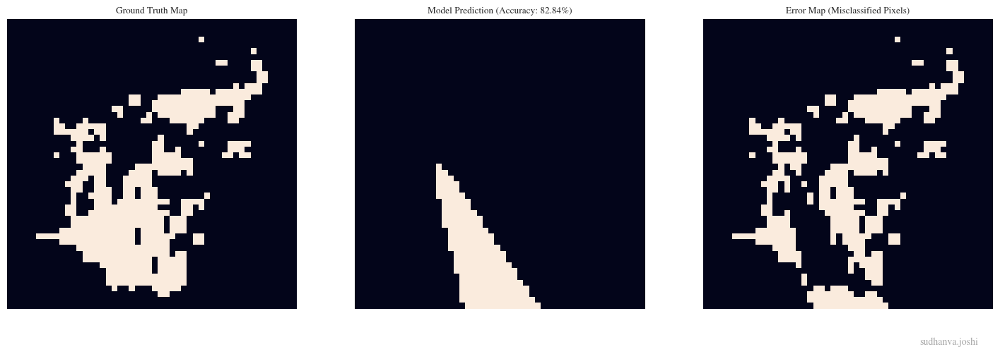

batch_size,64
final_accuracy,0.8284
final_loss,0.38215
grad_steps,1
learning_rate,0.00021
samples_to_converge,125000
time_to_converge,1.32231
total_parameters,1185


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: r5tzqhl3 with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0001951935562645148
wandb: 	width: 64



Sweep Run
Config: Depth=6, Width=64, LR=0.0002, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 8.74s.


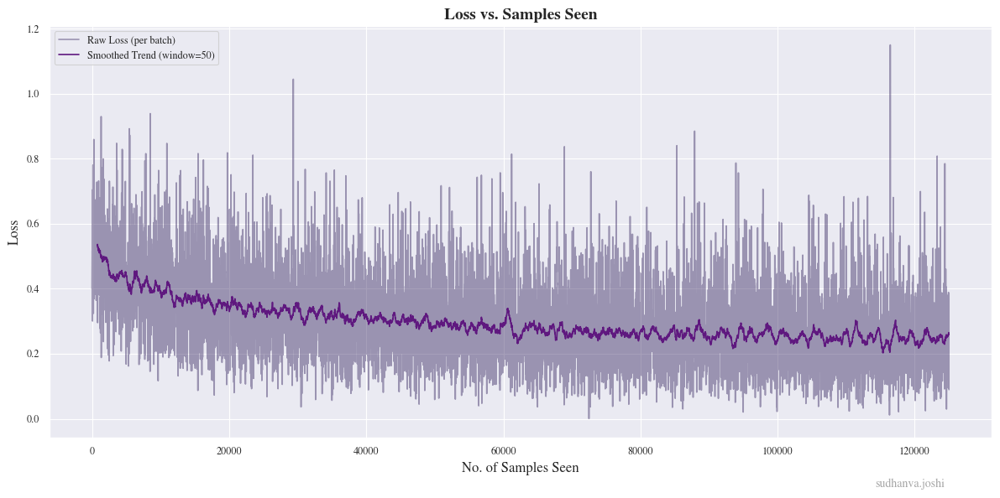

Saving final model.
Model saved to runs-q1/r5tzqhl3/final_model.npz
Model has 16897 trainable parameters.
Final accuracy: 89.40%
Final Loss: 0.24868846923465834

Final Pixel Accuracy: 89.40%


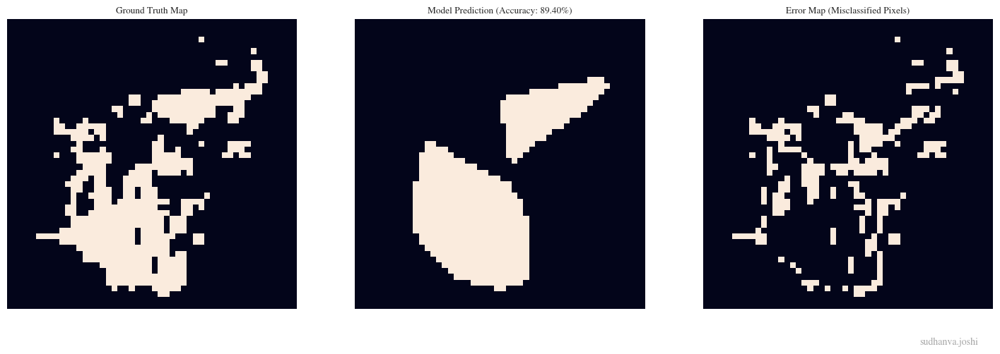

batch_size,16
final_accuracy,0.894
final_loss,0.24869
grad_steps,1
learning_rate,0.0002
samples_to_converge,125000
time_to_converge,8.74265
total_parameters,16897


wandb: Agent Starting Run: o6f4hmbn with config:
wandb: 	batch_size: 64
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00034445988303919675
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0003, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 23.20s.


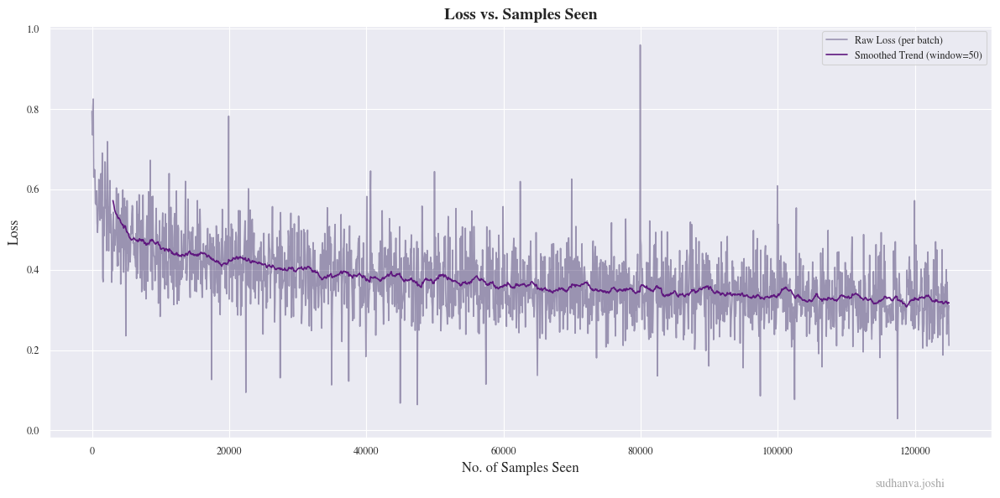

Saving final model.
Model saved to runs-q1/o6f4hmbn/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 84.88%
Final Loss: 0.31992331715518174

Final Pixel Accuracy: 84.88%


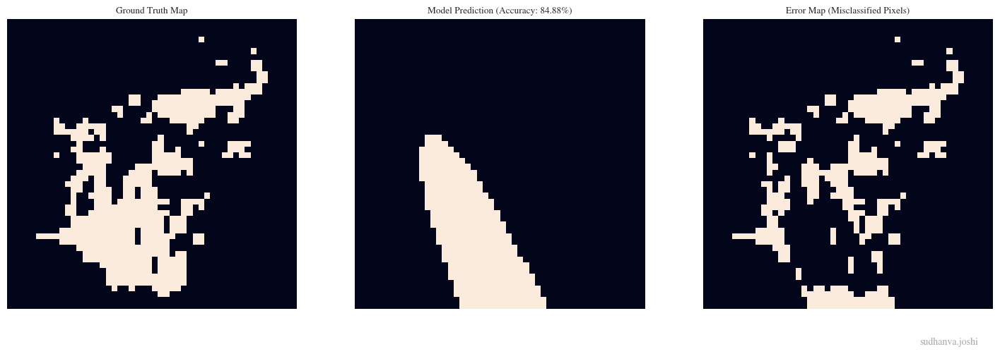

batch_size,64
final_accuracy,0.8488
final_loss,0.31992
grad_steps,4
learning_rate,0.00034
samples_to_converge,125000
time_to_converge,23.19963
total_parameters,132609


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: j3fg9k3g with config:
wandb: 	batch_size: 128
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.00015048289288826253
wandb: 	width: 64



Sweep Run
Config: Depth=5, Width=64, LR=0.0002, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 1.64s.


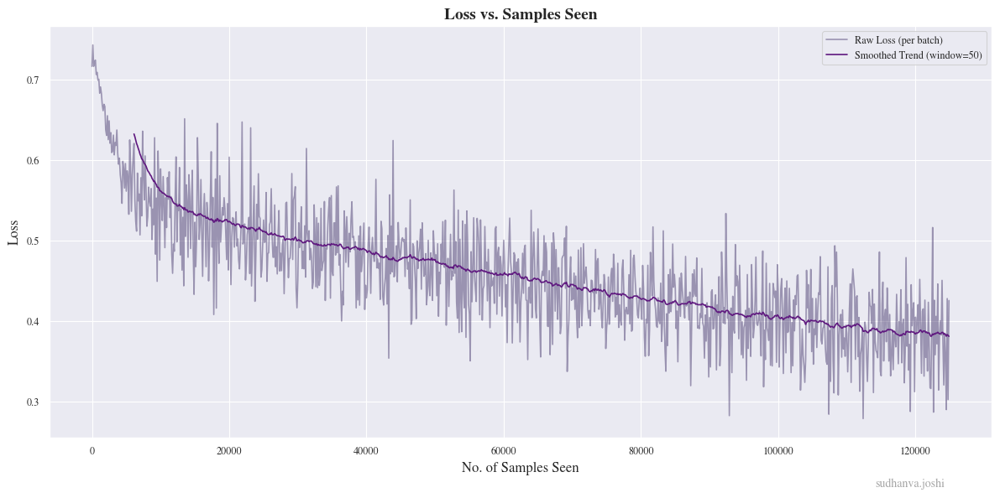

Saving final model.
Model saved to runs-q1/j3fg9k3g/final_model.npz
Model has 12737 trainable parameters.
Final accuracy: 83.40%
Final Loss: 0.38037981709836116

Final Pixel Accuracy: 83.40%


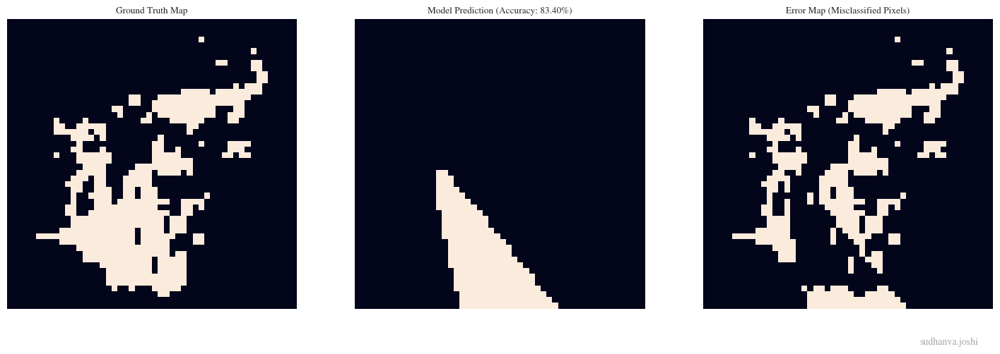

batch_size,128
final_accuracy,0.834
final_loss,0.38038
grad_steps,2
learning_rate,0.00015
samples_to_converge,125000
time_to_converge,1.64111
total_parameters,12737


wandb: Agent Starting Run: y0kywlro with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0007190678779838115
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0007, Batch=32



Early stopping triggered at epoch 33.
Epoch 33 complete. Total samples seen: 82500. Time: 52.08s.


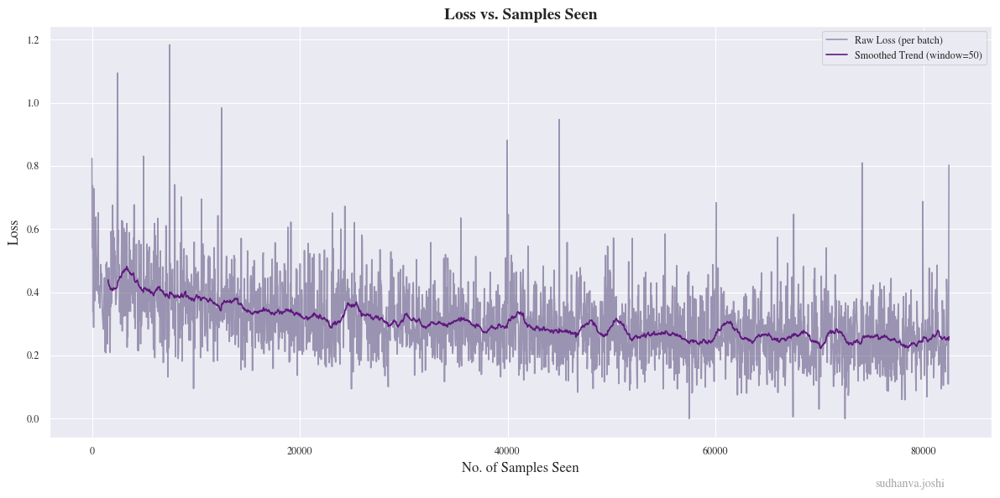

Saving final model.
Model saved to runs-q1/y0kywlro/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 86.64%
Final Loss: 0.2552699465281949

Final Pixel Accuracy: 86.64%


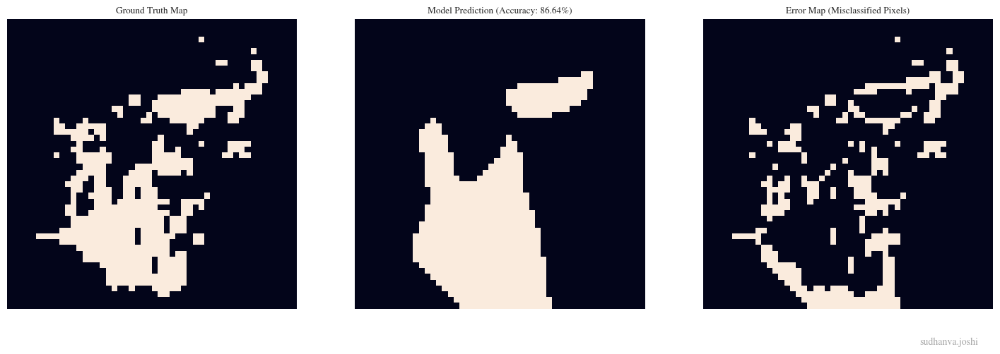

batch_size,32
final_accuracy,0.8664
final_loss,0.25527
grad_steps,1
learning_rate,0.00072
samples_to_converge,82500
time_to_converge,52.0765
total_parameters,264193


wandb: Agent Starting Run: hpcklkab with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.000731734661887056
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0007, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 1.98s.


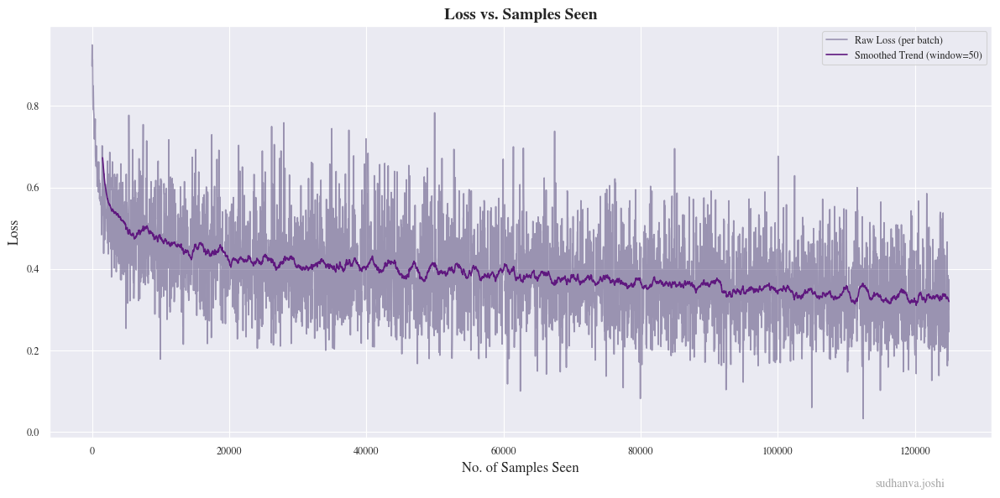

Saving final model.
Model saved to runs-q1/hpcklkab/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 84.96%
Final Loss: 0.32687170757777423

Final Pixel Accuracy: 84.96%


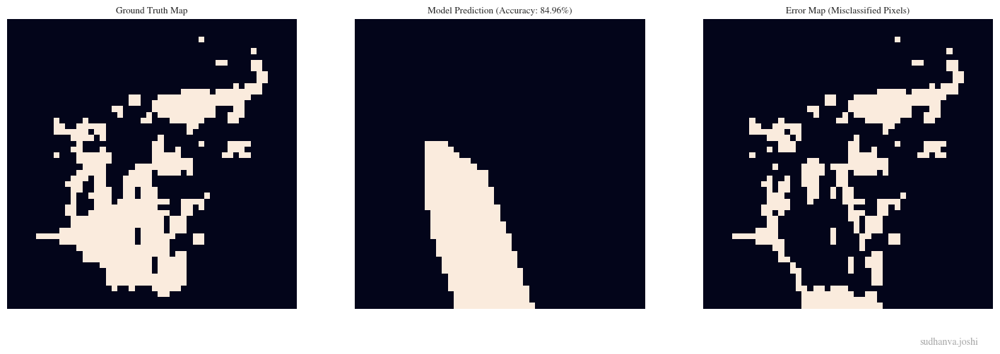

batch_size,32
final_accuracy,0.8496
final_loss,0.32687
grad_steps,1
learning_rate,0.00073
samples_to_converge,125000
time_to_converge,1.97925
total_parameters,1185


wandb: Agent Starting Run: auyvzwhf with config:
wandb: 	batch_size: 128
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00036089325981431545
wandb: 	width: 128



Sweep Run
Config: Depth=4, Width=128, LR=0.0004, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 8.22s.


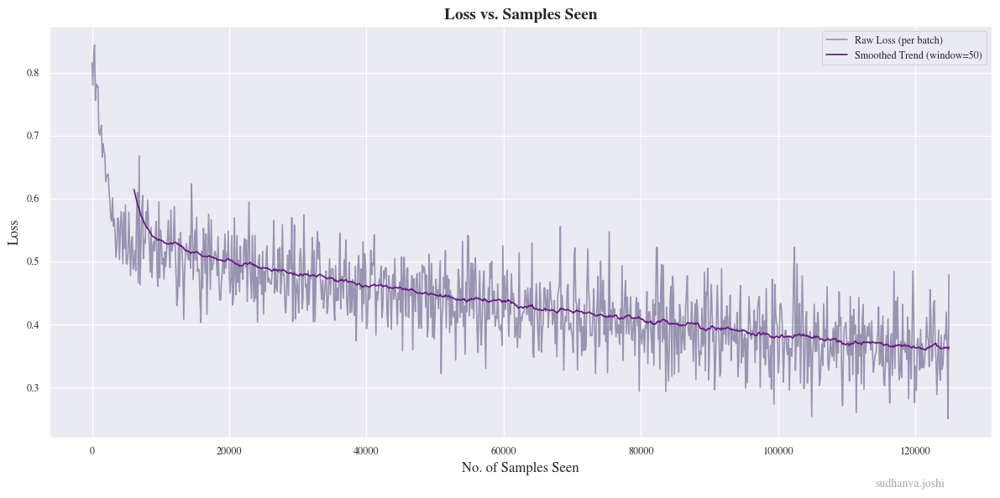

Saving final model.
Model saved to runs-q1/auyvzwhf/final_model.npz
Model has 33537 trainable parameters.
Final accuracy: 83.96%
Final Loss: 0.36203491268059357

Final Pixel Accuracy: 83.96%


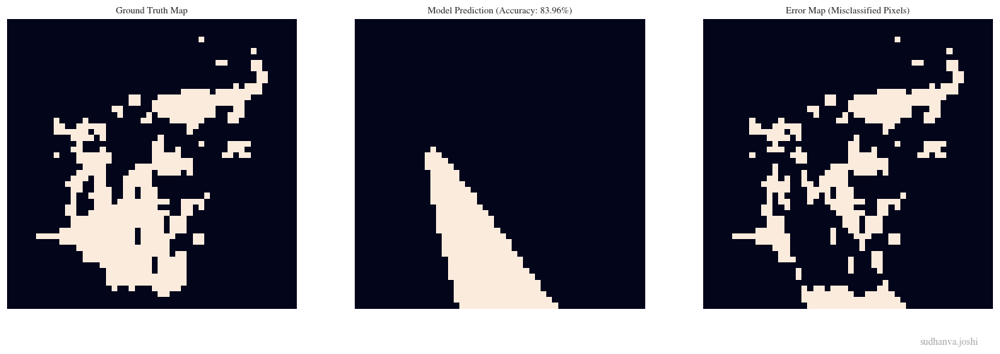

batch_size,128
final_accuracy,0.8396
final_loss,0.36203
grad_steps,4
learning_rate,0.00036
samples_to_converge,125000
time_to_converge,8.21606
total_parameters,33537


wandb: Agent Starting Run: vbq5fxuy with config:
wandb: 	batch_size: 64
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.000563760761530244
wandb: 	width: 64



Sweep Run
Config: Depth=6, Width=64, LR=0.0006, Batch=64



Early stopping triggered at epoch 50.
Epoch 50 complete. Total samples seen: 125000. Time: 2.50s.


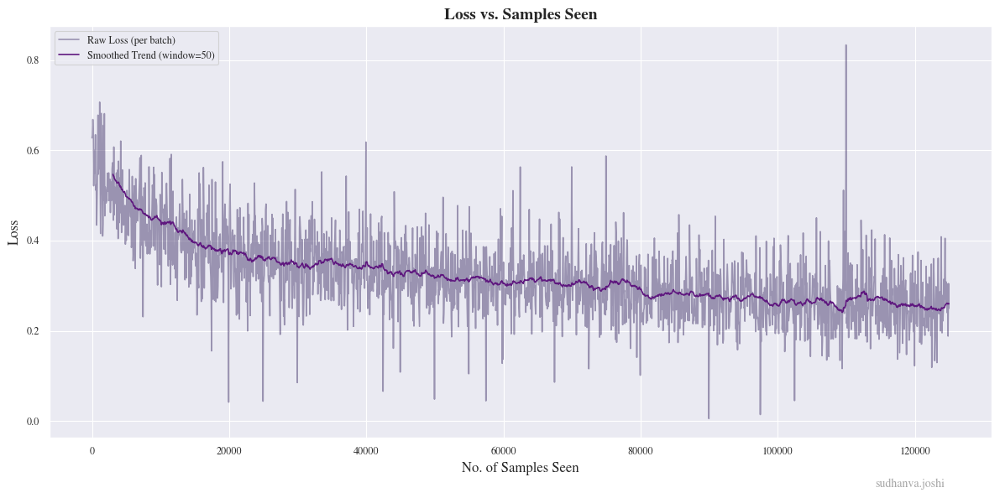

Saving final model.
Model saved to runs-q1/vbq5fxuy/final_model.npz
Model has 16897 trainable parameters.
Final accuracy: 87.60%
Final Loss: 0.26470233847198804

Final Pixel Accuracy: 87.60%


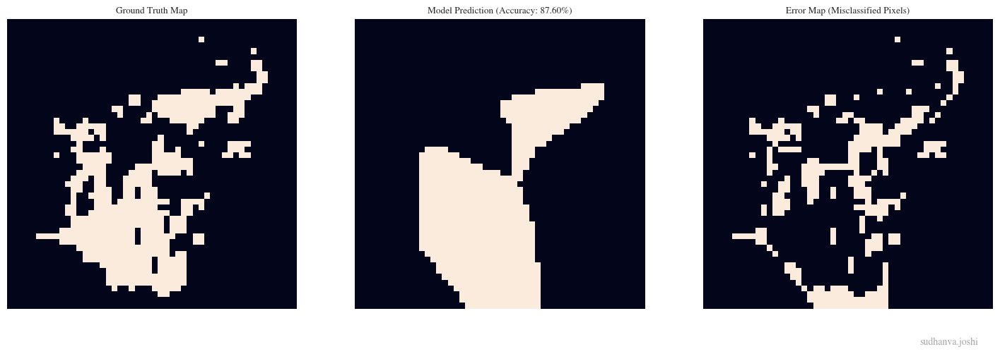

batch_size,64
final_accuracy,0.876
final_loss,0.2647
grad_steps,2
learning_rate,0.00056
samples_to_converge,125000
time_to_converge,2.50081
total_parameters,16897


wandb: Agent Starting Run: n7xv3we5 with config:
wandb: 	batch_size: 32
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.000451758429550667
wandb: 	width: 64



Sweep Run
Config: Depth=5, Width=64, LR=0.0005, Batch=32



Early stopping triggered at epoch 40.
Epoch 40 complete. Total samples seen: 100000. Time: 3.05s.


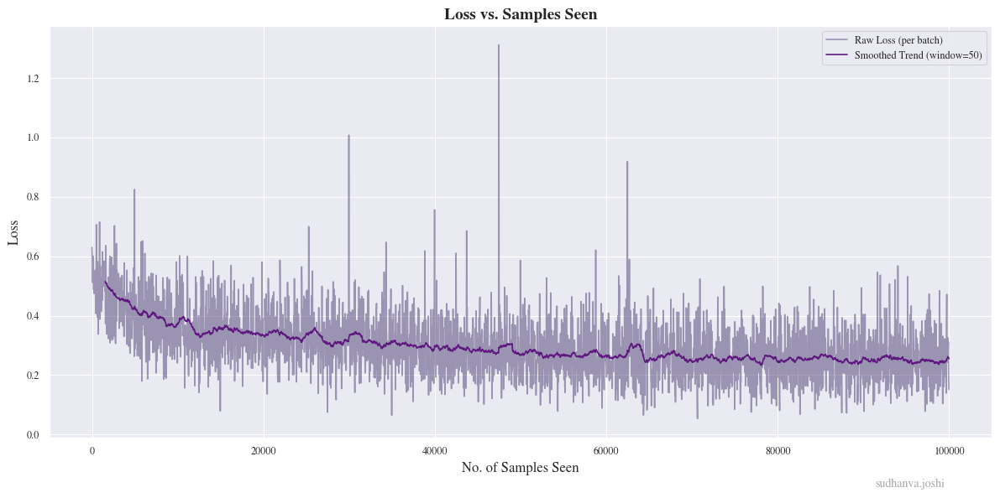

Saving final model.
Model saved to runs-q1/n7xv3we5/final_model.npz
Model has 12737 trainable parameters.
Final accuracy: 90.12%
Final Loss: 0.2505737255520979

Final Pixel Accuracy: 90.12%


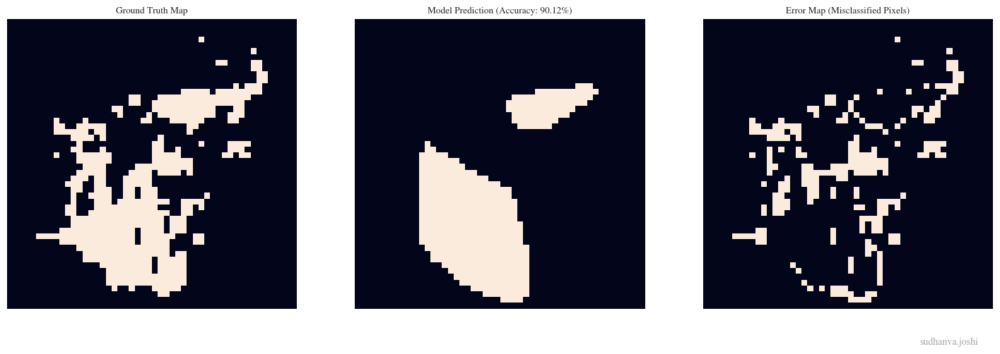

batch_size,32
final_accuracy,0.9012
final_loss,0.25057
grad_steps,1
learning_rate,0.00045
samples_to_converge,100000
time_to_converge,3.05166
total_parameters,12737


wandb: Agent Starting Run: j1qp2yg7 with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0008746478382291779
wandb: 	width: 64



Sweep Run
Config: Depth=4, Width=64, LR=0.0009, Batch=16



Early stopping triggered at epoch 47.
Epoch 47 complete. Total samples seen: 117500. Time: 4.06s.


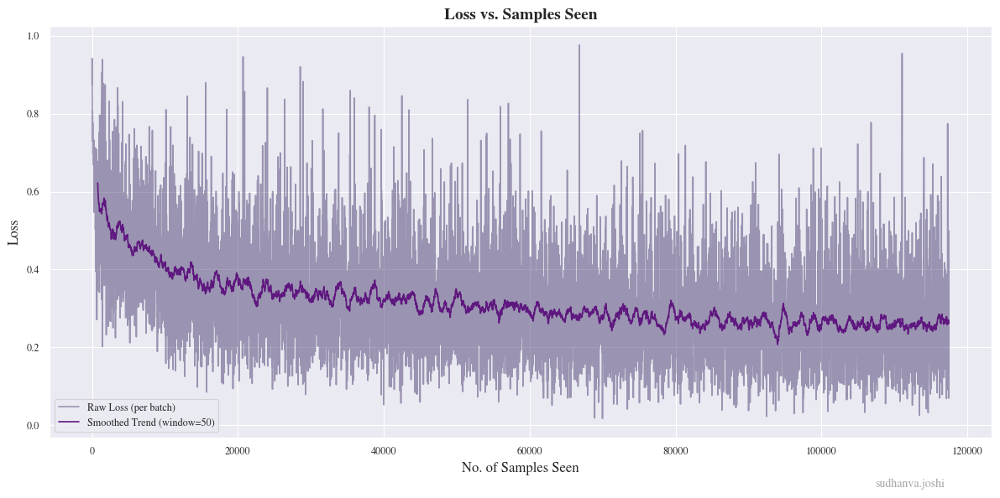

Saving final model.
Model saved to runs-q1/j1qp2yg7/final_model.npz
Model has 8577 trainable parameters.
Final accuracy: 89.56%
Final Loss: 0.2672263206525052

Final Pixel Accuracy: 89.56%


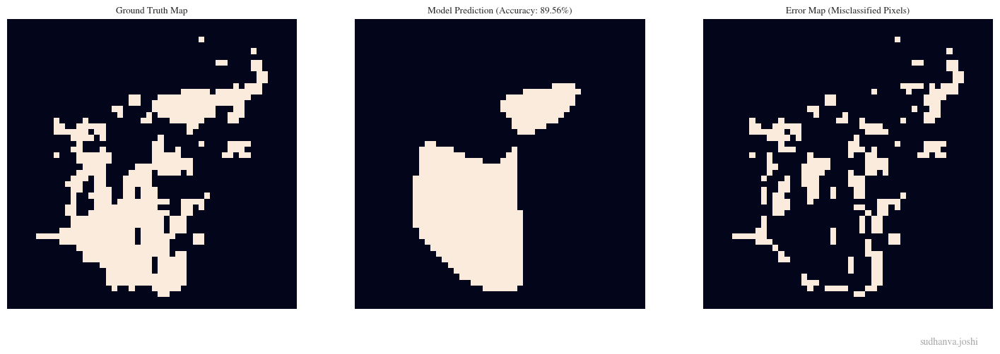

batch_size,16
final_accuracy,0.8956
final_loss,0.26723
grad_steps,4
learning_rate,0.00087
samples_to_converge,117500
time_to_converge,4.05871
total_parameters,8577


wandb: Agent Starting Run: rmhd7ik1 with config:
wandb: 	batch_size: 16
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.00011260440525256716
wandb: 	width: 256



Sweep Run
Config: Depth=5, Width=256, LR=0.0001, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 64.36s.


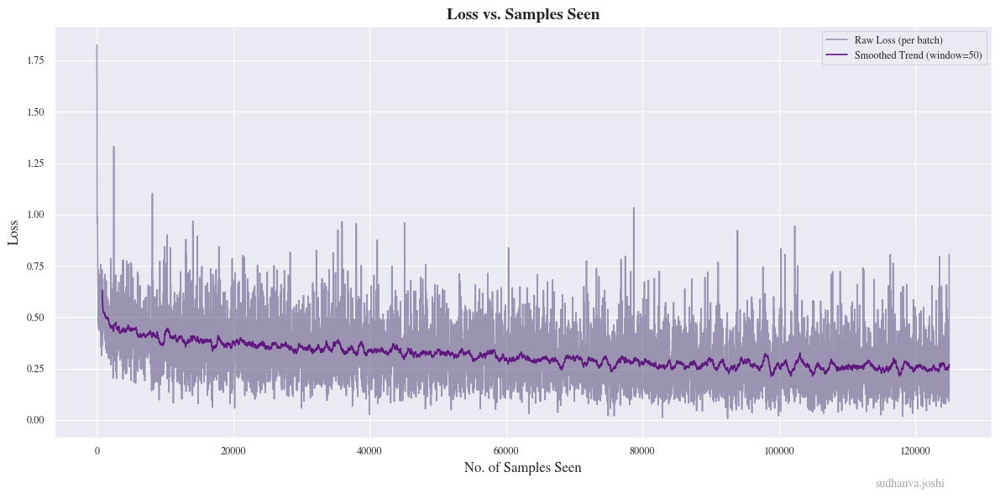

Saving final model.
Model saved to runs-q1/rmhd7ik1/final_model.npz
Model has 198401 trainable parameters.
Final accuracy: 84.92%
Final Loss: 0.25762834499298426

Final Pixel Accuracy: 84.92%


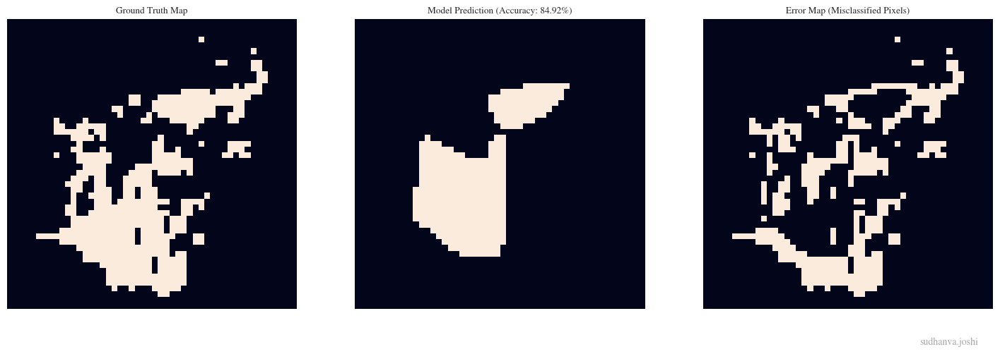

batch_size,16
final_accuracy,0.8492
final_loss,0.25763
grad_steps,1
learning_rate,0.00011
samples_to_converge,125000
time_to_converge,64.35676
total_parameters,198401


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: j4qxj3xn with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0004171596901707559
wandb: 	width: 64



Sweep Run
Config: Depth=3, Width=64, LR=0.0004, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 2.12s.


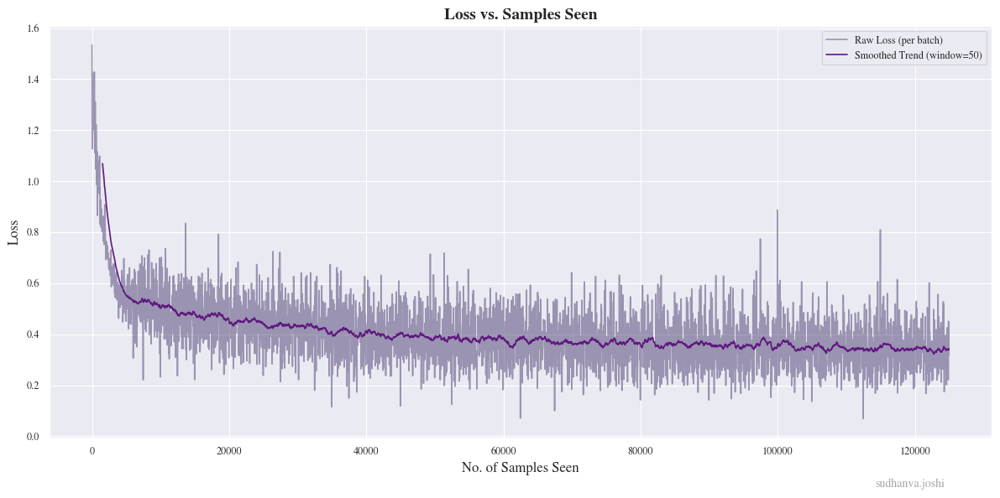

Saving final model.
Model saved to runs-q1/j4qxj3xn/final_model.npz
Model has 4417 trainable parameters.
Final accuracy: 84.12%
Final Loss: 0.34082659879319827

Final Pixel Accuracy: 84.12%


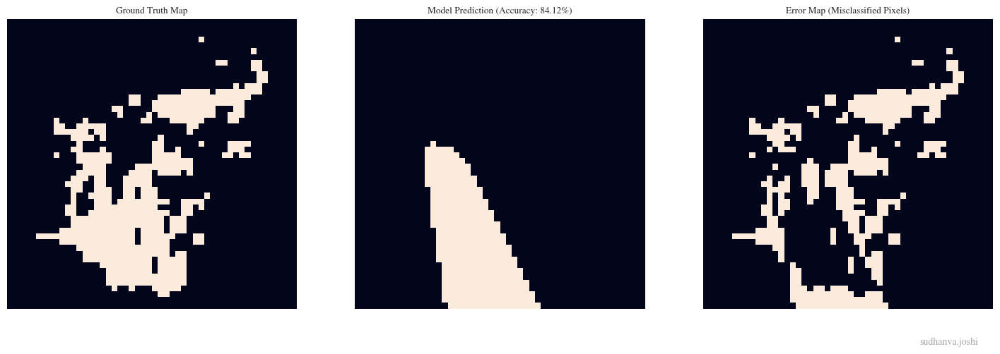

batch_size,32
final_accuracy,0.8412
final_loss,0.34083
grad_steps,2
learning_rate,0.00042
samples_to_converge,125000
time_to_converge,2.12425
total_parameters,4417


wandb: Agent Starting Run: adsseita with config:
wandb: 	batch_size: 64
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00013429330597067925
wandb: 	width: 128



Sweep Run
Config: Depth=5, Width=128, LR=0.0001, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 4.13s.


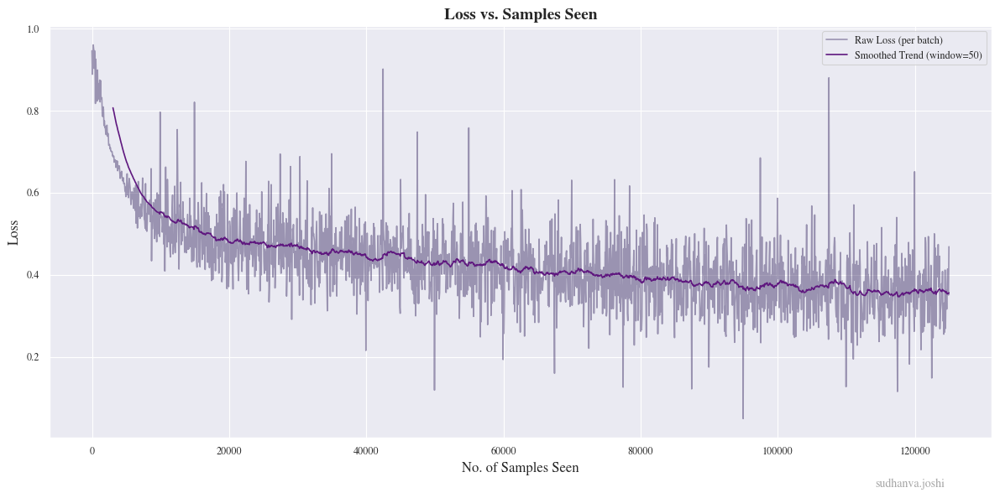

Saving final model.
Model saved to runs-q1/adsseita/final_model.npz
Model has 50049 trainable parameters.
Final accuracy: 84.08%
Final Loss: 0.35674095562902314

Final Pixel Accuracy: 84.08%


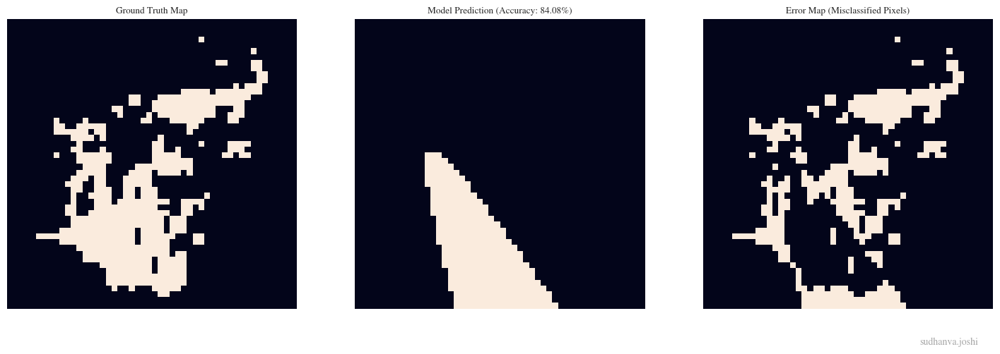

batch_size,64
final_accuracy,0.8408
final_loss,0.35674
grad_steps,4
learning_rate,0.00013
samples_to_converge,125000
time_to_converge,4.13373
total_parameters,50049


wandb: Agent Starting Run: 8giq1l7a with config:
wandb: 	batch_size: 128
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0006461583255786215
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0006, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 1.39s.


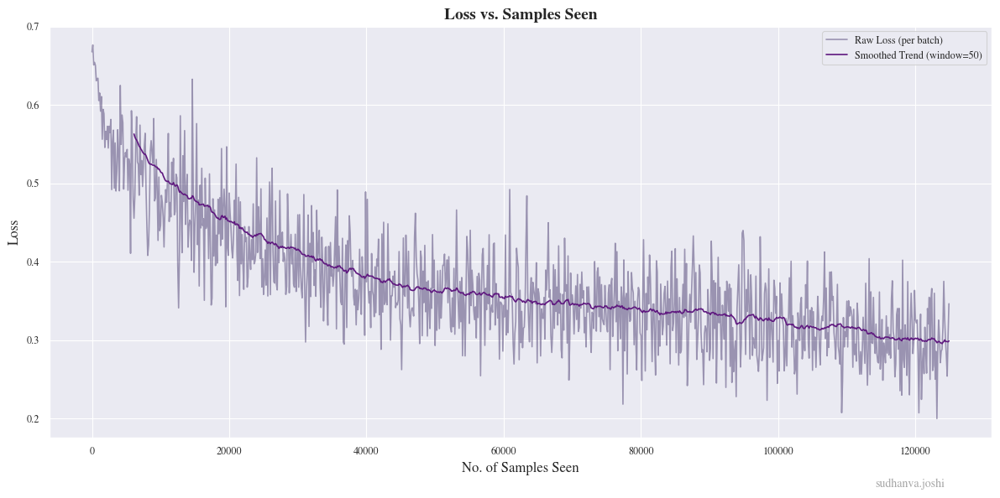

Saving final model.
Model saved to runs-q1/8giq1l7a/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 86.08%
Final Loss: 0.2934347661000362

Final Pixel Accuracy: 86.08%


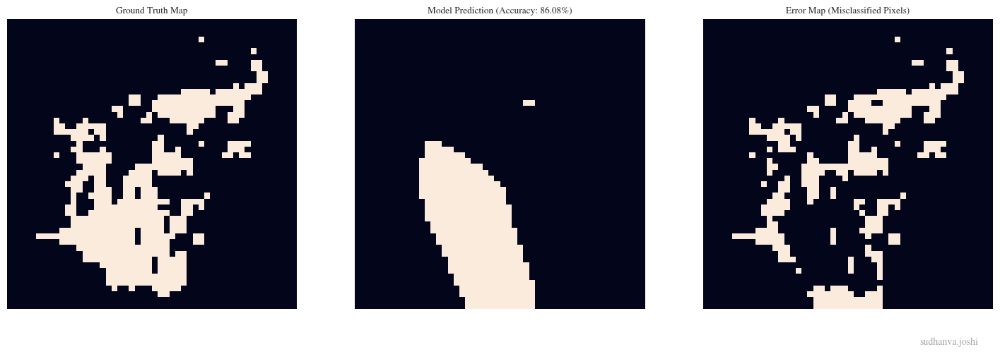

batch_size,128
final_accuracy,0.8608
final_loss,0.29343
grad_steps,2
learning_rate,0.00065
samples_to_converge,125000
time_to_converge,1.39264
total_parameters,4353


wandb: Agent Starting Run: lhtbyuex with config:
wandb: 	batch_size: 64
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.00025817830916140835
wandb: 	width: 128



Sweep Run
Config: Depth=5, Width=128, LR=0.0003, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 4.46s.


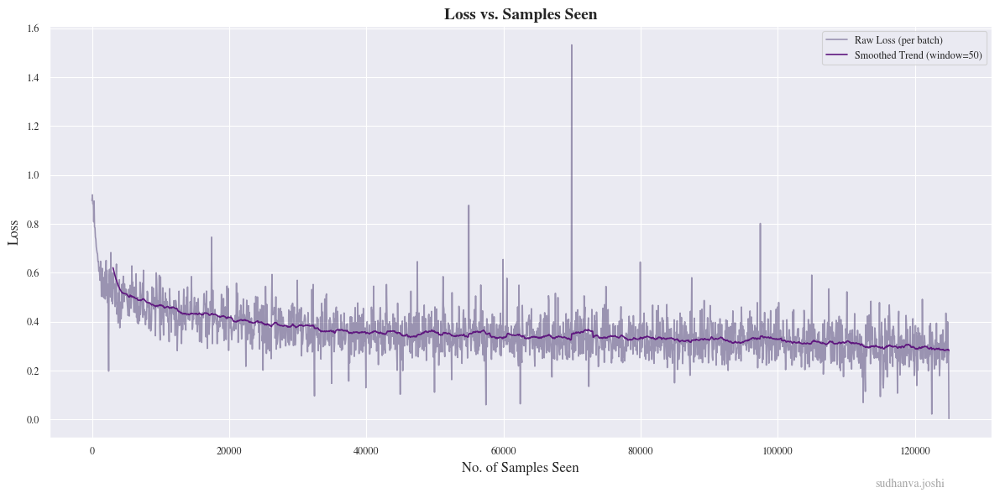

Saving final model.
Model saved to runs-q1/lhtbyuex/final_model.npz
Model has 50049 trainable parameters.
Final accuracy: 87.00%
Final Loss: 0.2927552670780831

Final Pixel Accuracy: 87.00%


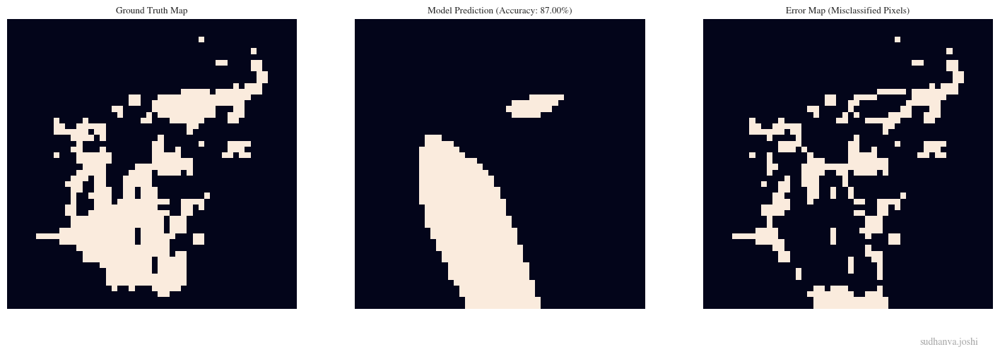

batch_size,64
final_accuracy,0.87
final_loss,0.29276
grad_steps,2
learning_rate,0.00026
samples_to_converge,125000
time_to_converge,4.46469
total_parameters,50049


wandb: Agent Starting Run: swqa0474 with config:
wandb: 	batch_size: 64
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0006911071541862107
wandb: 	width: 64



Sweep Run
Config: Depth=3, Width=64, LR=0.0007, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.71s.


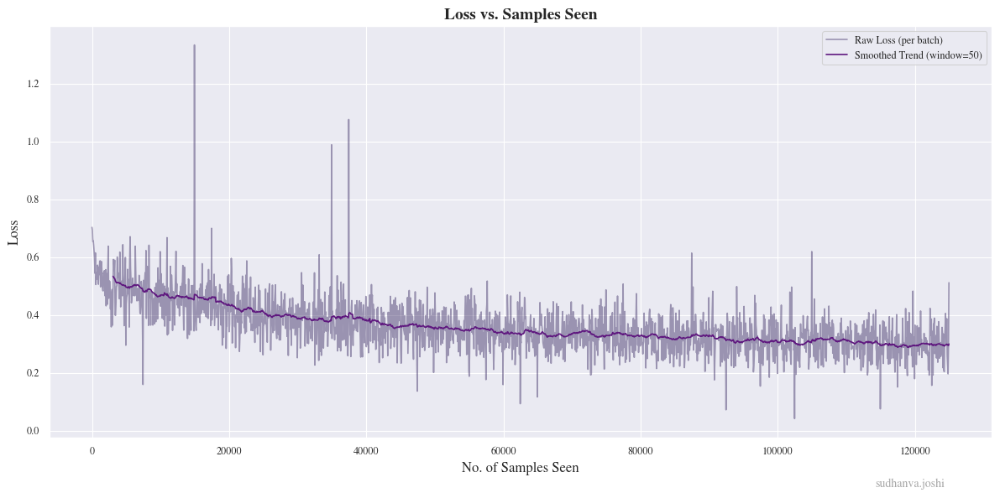

Saving final model.
Model saved to runs-q1/swqa0474/final_model.npz
Model has 4417 trainable parameters.
Final accuracy: 85.16%
Final Loss: 0.29794905371574854

Final Pixel Accuracy: 85.16%


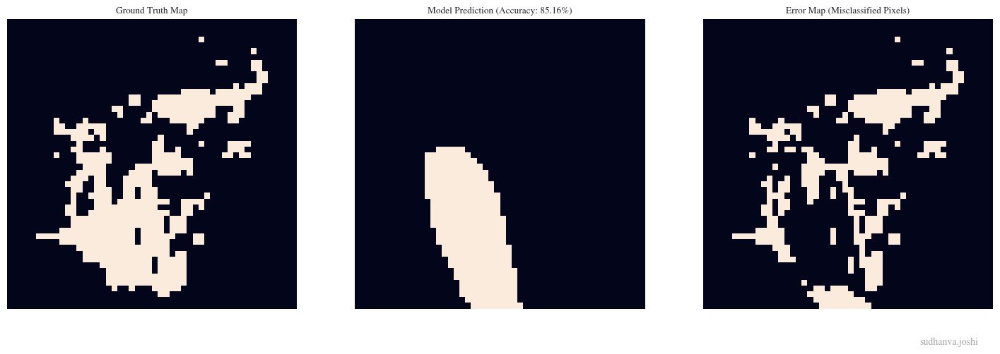

batch_size,64
final_accuracy,0.8516
final_loss,0.29795
grad_steps,1
learning_rate,0.00069
samples_to_converge,125000
time_to_converge,1.70603
total_parameters,4417


wandb: Agent Starting Run: n103zjsx with config:
wandb: 	batch_size: 64
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.000721592611318574
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0007, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 18.39s.


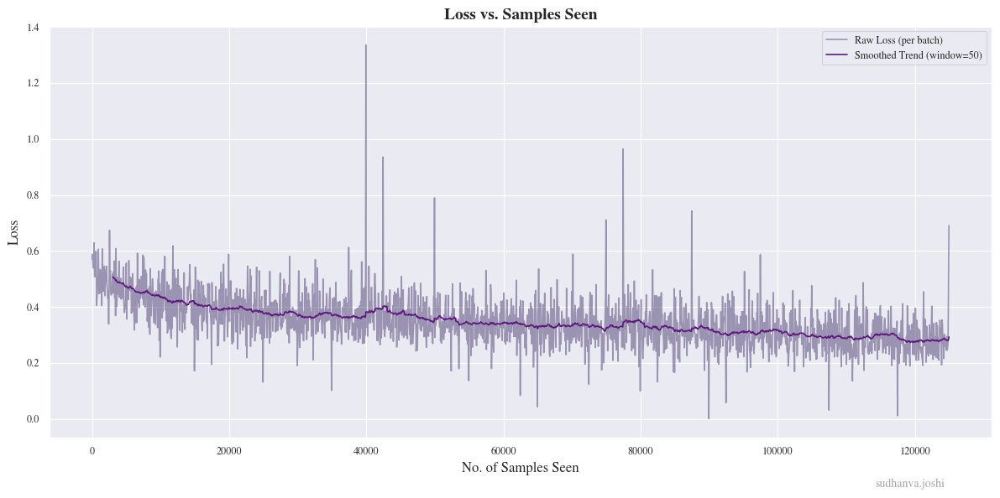

Saving final model.
Model saved to runs-q1/n103zjsx/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 87.16%
Final Loss: 0.2848509862021325

Final Pixel Accuracy: 87.16%


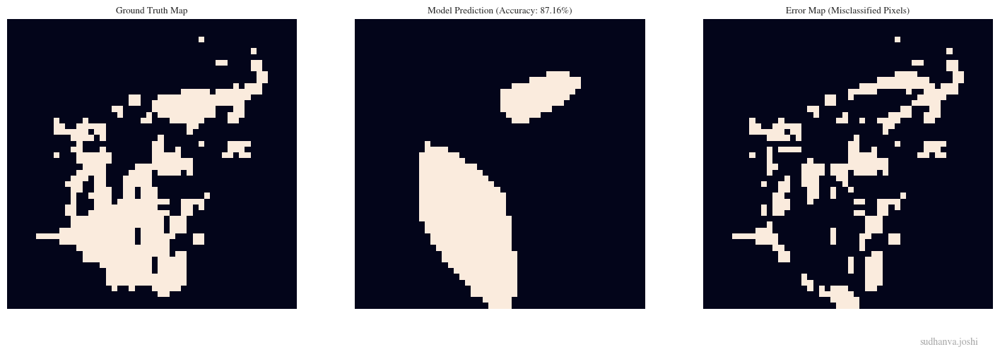

batch_size,64
final_accuracy,0.8716
final_loss,0.28485
grad_steps,4
learning_rate,0.00072
samples_to_converge,125000
time_to_converge,18.39421
total_parameters,132609


wandb: Agent Starting Run: 29z03t5i with config:
wandb: 	batch_size: 128
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0005492817401840702
wandb: 	width: 128



Sweep Run
Config: Depth=3, Width=128, LR=0.0005, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 5.52s.


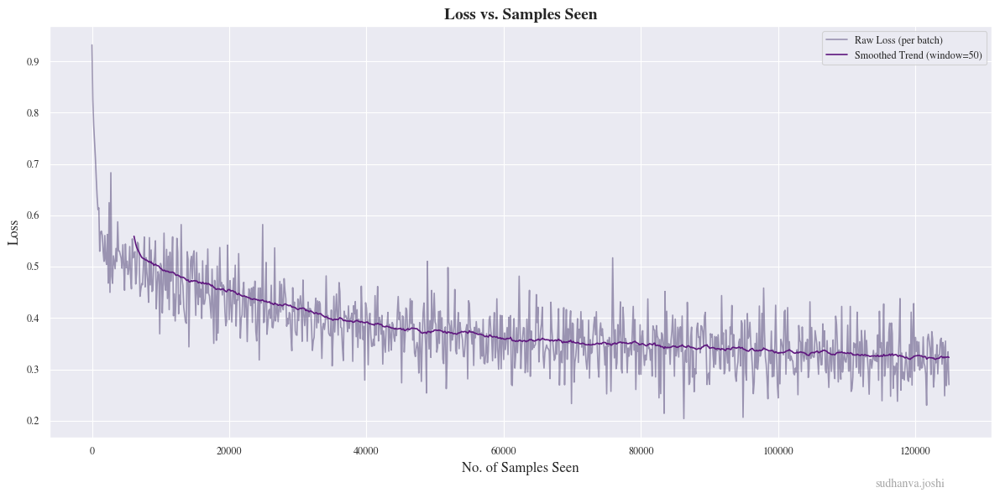

Saving final model.
Model saved to runs-q1/29z03t5i/final_model.npz
Model has 17025 trainable parameters.
Final accuracy: 84.76%
Final Loss: 0.3186517693098548

Final Pixel Accuracy: 84.76%


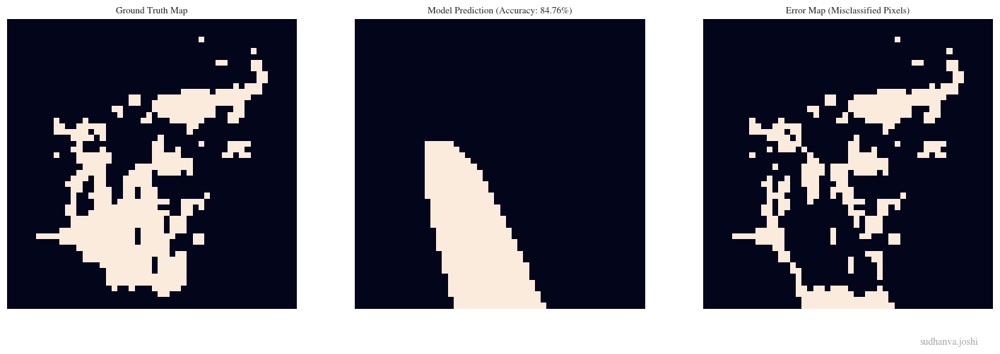

batch_size,128
final_accuracy,0.8476
final_loss,0.31865
grad_steps,1
learning_rate,0.00055
samples_to_converge,125000
time_to_converge,5.52305
total_parameters,17025


wandb: Agent Starting Run: xvyeyo9r with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0008383932087410474
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0008, Batch=32



Early stopping triggered at epoch 31.
Epoch 31 complete. Total samples seen: 77500. Time: 70.87s.


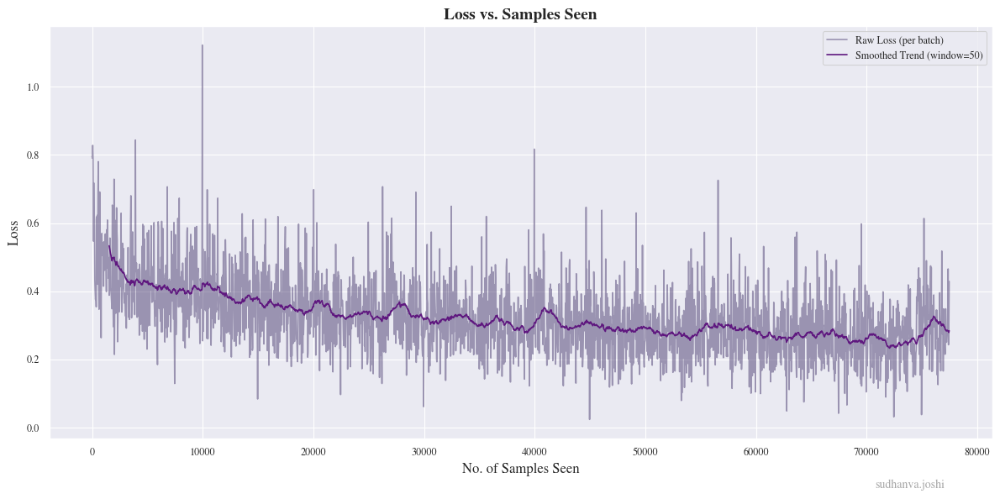

Saving final model.
Model saved to runs-q1/xvyeyo9r/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 87.08%
Final Loss: 0.30056281433300713

Final Pixel Accuracy: 87.08%


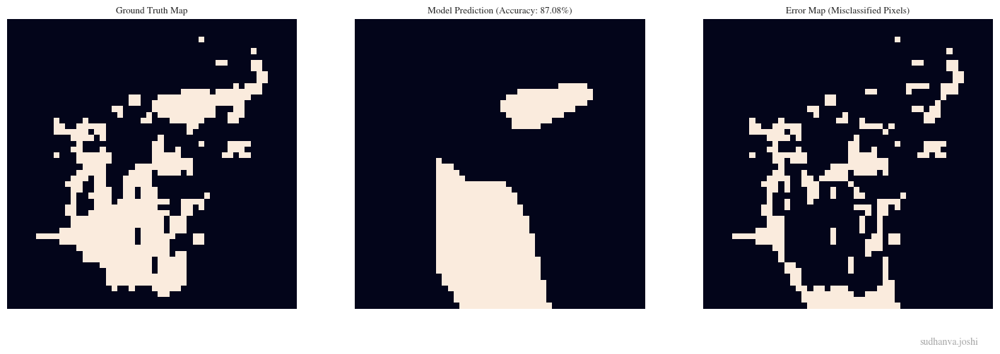

batch_size,32
final_accuracy,0.8708
final_loss,0.30056
grad_steps,4
learning_rate,0.00084
samples_to_converge,77500
time_to_converge,70.8688
total_parameters,264193


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: l4os9xvl with config:
wandb: 	batch_size: 16
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.000189629010025828
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0002, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 3.27s.


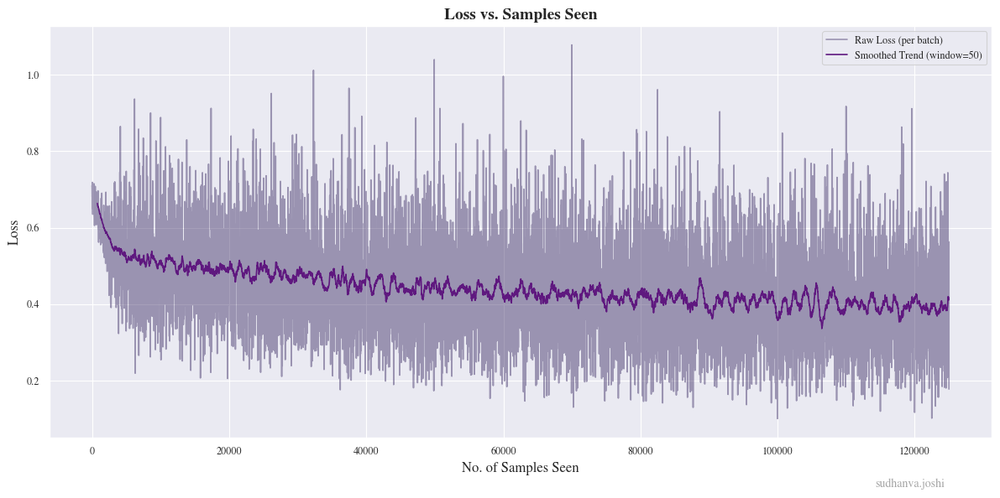

Saving final model.
Model saved to runs-q1/l4os9xvl/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 82.68%
Final Loss: 0.39379872554701884

Final Pixel Accuracy: 82.68%


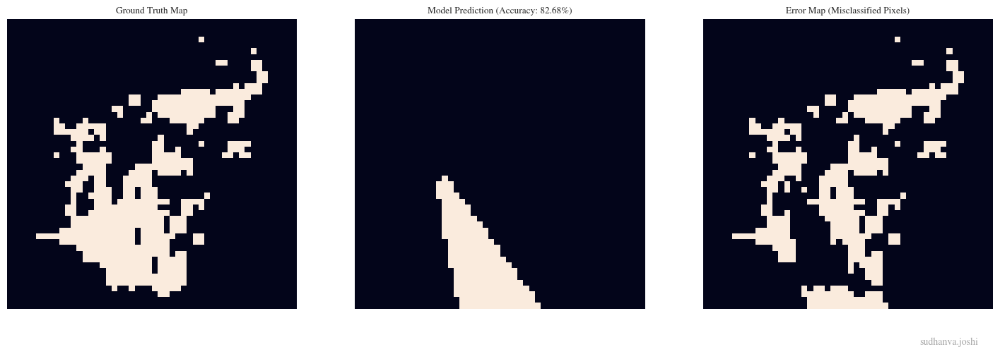

batch_size,16
final_accuracy,0.8268
final_loss,0.3938
grad_steps,2
learning_rate,0.00019
samples_to_converge,125000
time_to_converge,3.27466
total_parameters,1185


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: bbqg8w1b with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0003375339001195348
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0003, Batch=32



Early stopping triggered at epoch 35.
Epoch 35 complete. Total samples seen: 87500. Time: 45.21s.


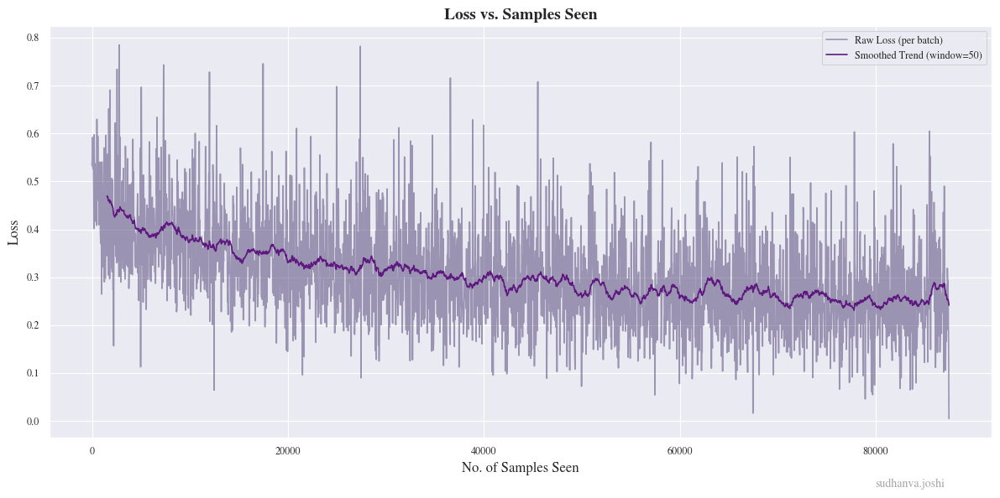

Saving final model.
Model saved to runs-q1/bbqg8w1b/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 89.96%
Final Loss: 0.26793837499980483

Final Pixel Accuracy: 89.96%


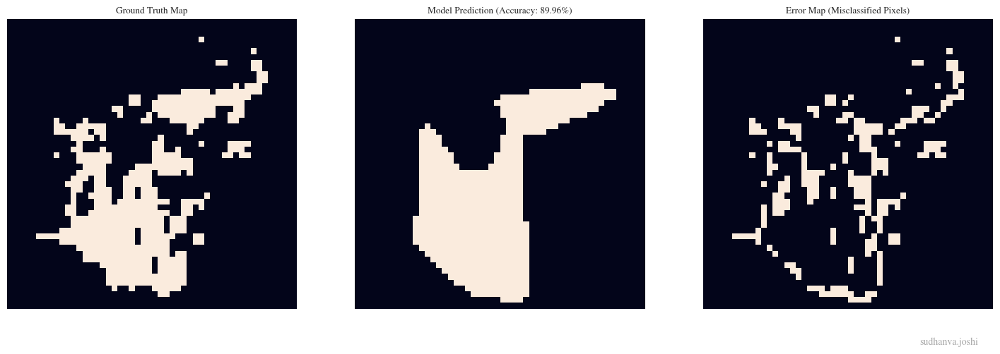

batch_size,32
final_accuracy,0.8996
final_loss,0.26794
grad_steps,1
learning_rate,0.00034
samples_to_converge,87500
time_to_converge,45.20693
total_parameters,264193


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: hgll9uzp with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.00033414780304618253
wandb: 	width: 256



Sweep Run
Config: Depth=4, Width=256, LR=0.0003, Batch=16



Early stopping triggered at epoch 42.
Epoch 42 complete. Total samples seen: 105000. Time: 18.38s.


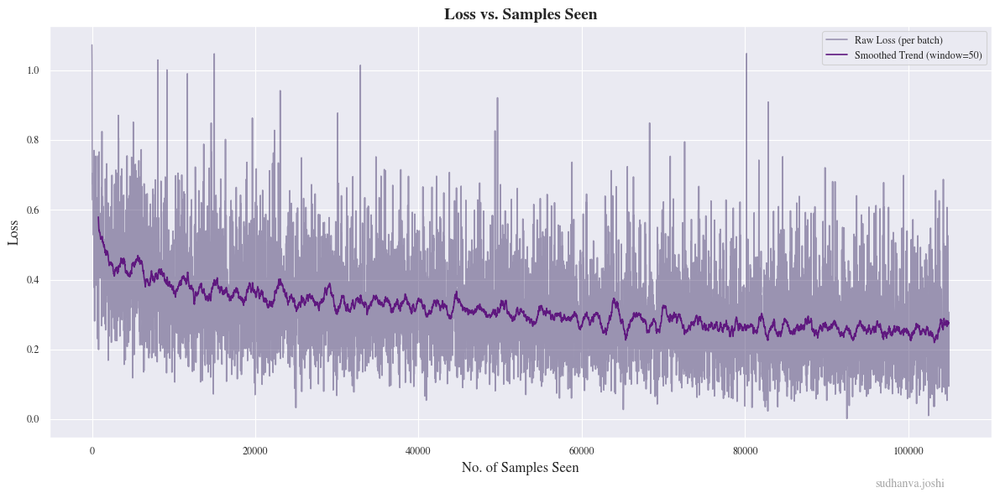

Saving final model.
Model saved to runs-q1/hgll9uzp/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 89.92%
Final Loss: 0.26052566432973084

Final Pixel Accuracy: 89.92%


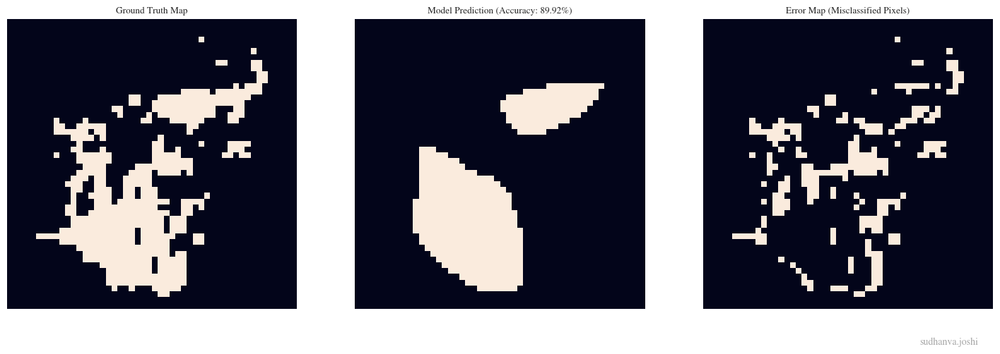

batch_size,16
final_accuracy,0.8992
final_loss,0.26053
grad_steps,2
learning_rate,0.00033
samples_to_converge,105000
time_to_converge,18.37851
total_parameters,132609


wandb: Agent Starting Run: m8ied4eb with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0005359581034047567
wandb: 	width: 64



Sweep Run
Config: Depth=6, Width=64, LR=0.0005, Batch=16



Early stopping triggered at epoch 45.
Epoch 45 complete. Total samples seen: 112500. Time: 7.12s.


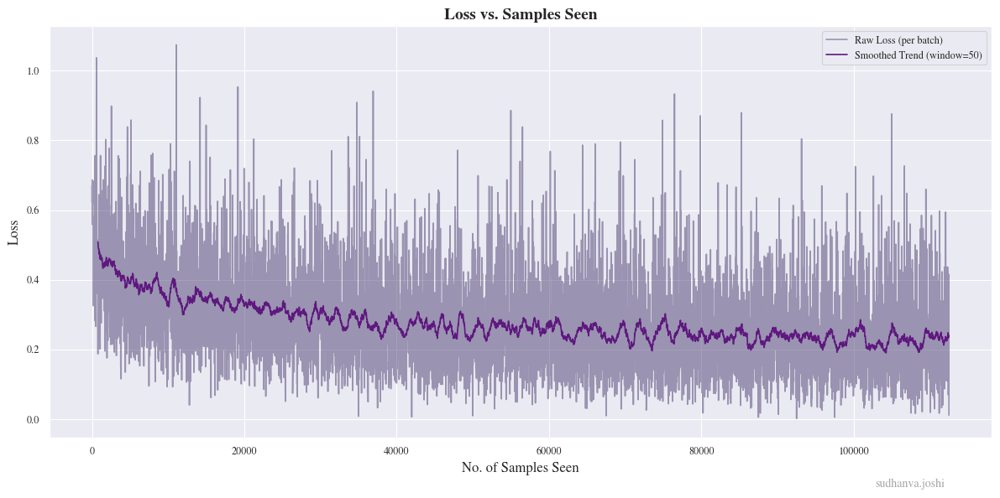

Saving final model.
Model saved to runs-q1/m8ied4eb/final_model.npz
Model has 16897 trainable parameters.
Final accuracy: 89.40%
Final Loss: 0.23752774237809482

Final Pixel Accuracy: 89.40%


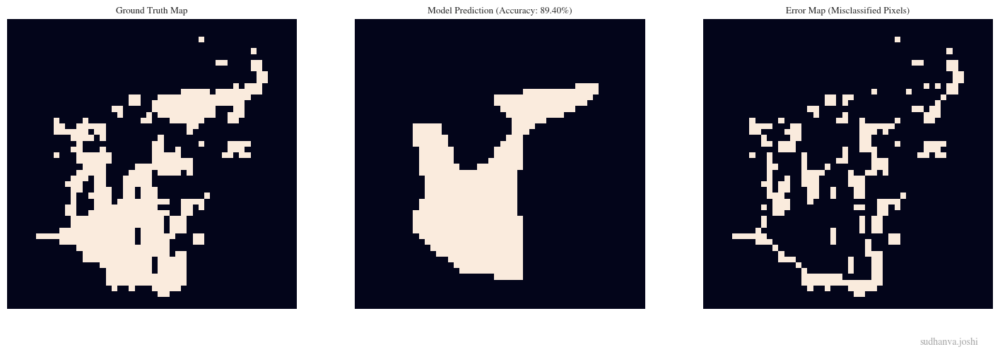

batch_size,16
final_accuracy,0.894
final_loss,0.23753
grad_steps,1
learning_rate,0.00054
samples_to_converge,112500
time_to_converge,7.11645
total_parameters,16897


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: to40sbtl with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.00031549029023677784
wandb: 	width: 32



Sweep Run
Config: Depth=6, Width=32, LR=0.0003, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 2.58s.


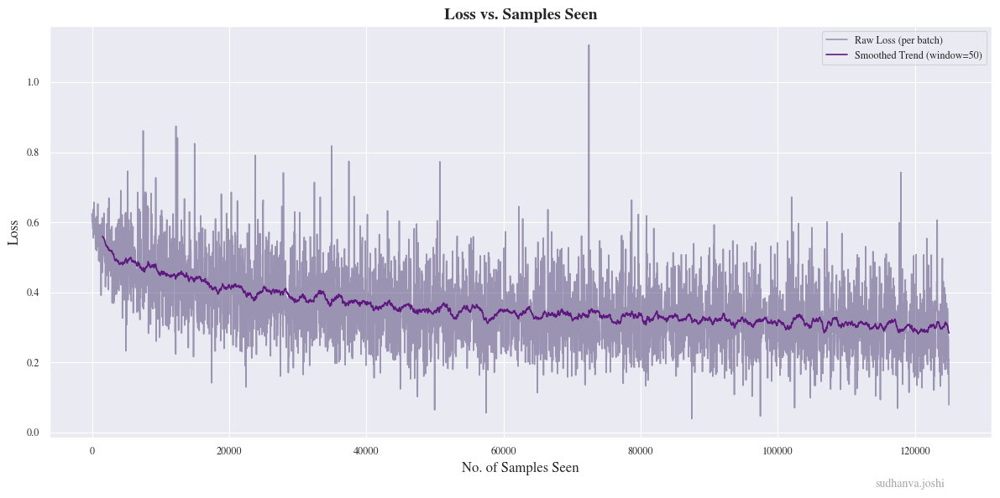

Saving final model.
Model saved to runs-q1/to40sbtl/final_model.npz
Model has 4353 trainable parameters.
Final accuracy: 85.36%
Final Loss: 0.2967165980780986

Final Pixel Accuracy: 85.36%


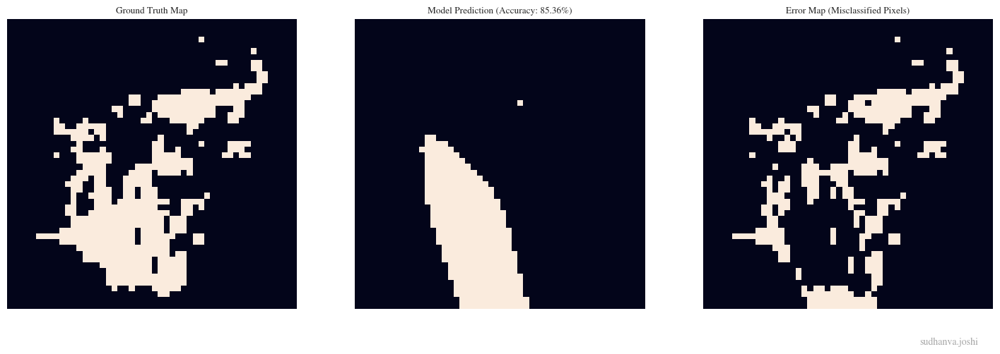

batch_size,32
final_accuracy,0.8536
final_loss,0.29672
grad_steps,2
learning_rate,0.00032
samples_to_converge,125000
time_to_converge,2.58265
total_parameters,4353


wandb: Agent Starting Run: p6x11oav with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0003783785501152703
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0004, Batch=32



Early stopping triggered at epoch 33.
Epoch 33 complete. Total samples seen: 82500. Time: 64.92s.


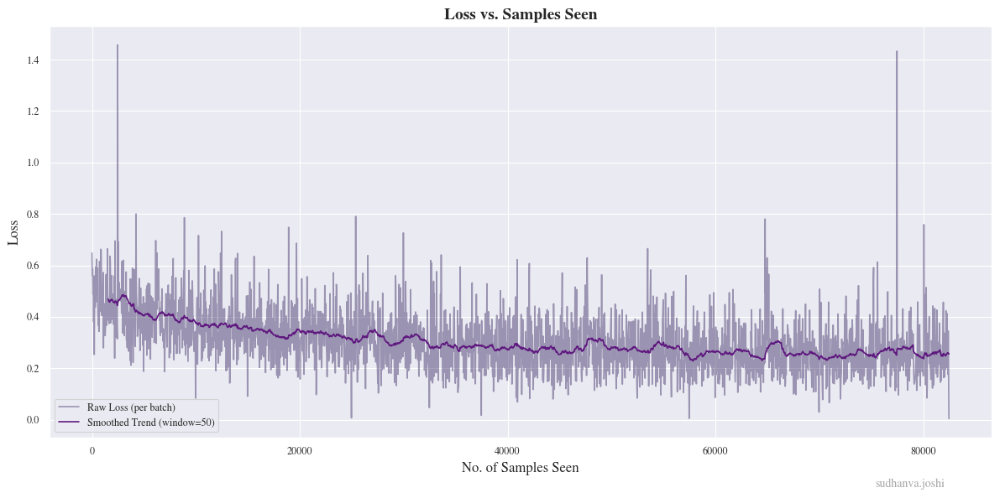

Saving final model.
Model saved to runs-q1/p6x11oav/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 88.96%
Final Loss: 0.26324585542258405

Final Pixel Accuracy: 88.96%


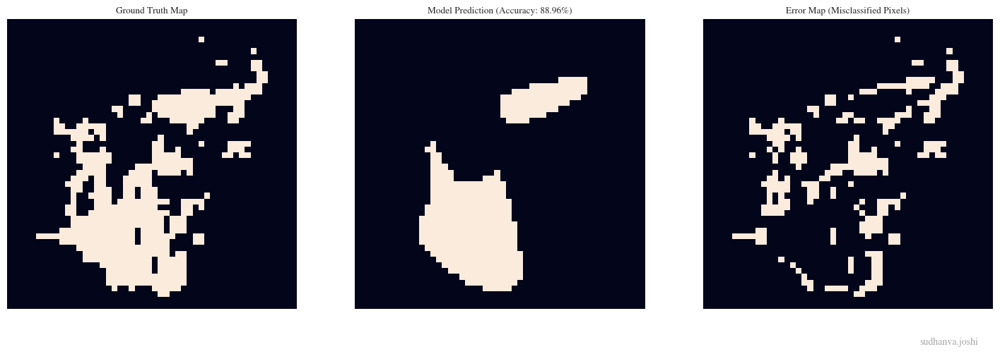

batch_size,32
final_accuracy,0.8896
final_loss,0.26325
grad_steps,1
learning_rate,0.00038
samples_to_converge,82500
time_to_converge,64.92347
total_parameters,264193


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: p5fmigj7 with config:
wandb: 	batch_size: 16
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0006389227173326126
wandb: 	width: 128



Sweep Run
Config: Depth=3, Width=128, LR=0.0006, Batch=16


Epoch 50 complete. Total samples seen: 125000. Time: 4.40s.


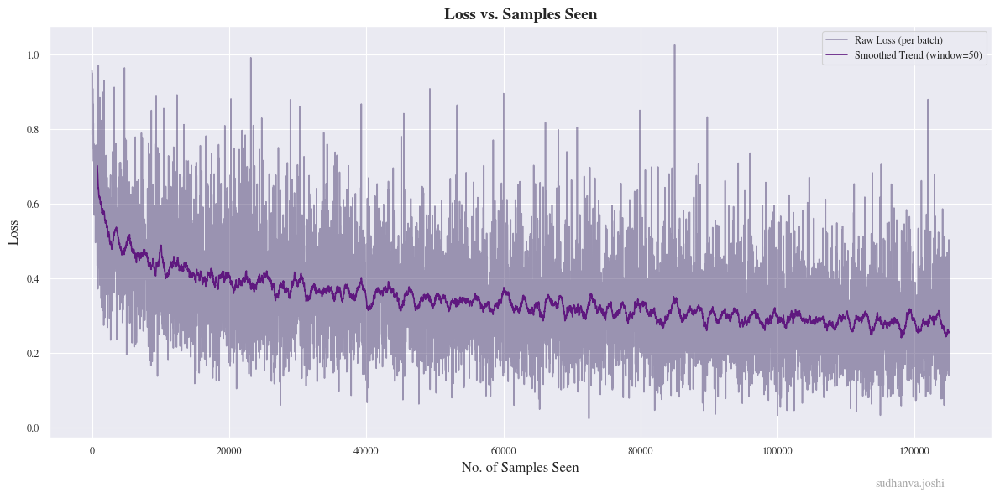

Saving final model.
Model saved to runs-q1/p5fmigj7/final_model.npz
Model has 17025 trainable parameters.
Final accuracy: 87.52%
Final Loss: 0.2777165740363291

Final Pixel Accuracy: 87.52%


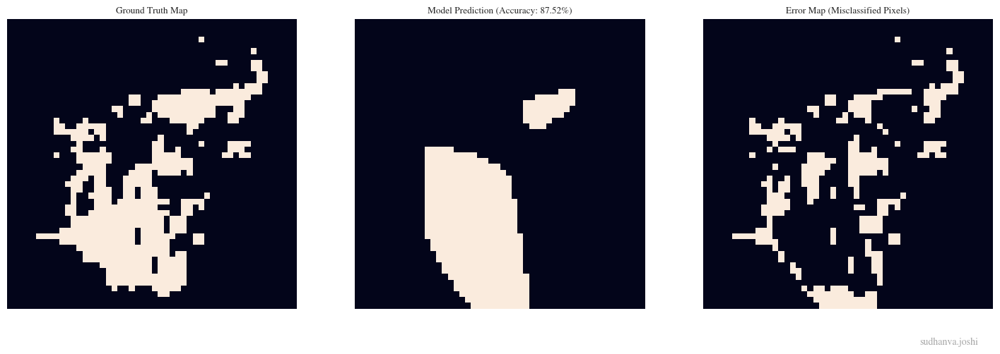

batch_size,16
final_accuracy,0.8752
final_loss,0.27772
grad_steps,4
learning_rate,0.00064
samples_to_converge,125000
time_to_converge,4.3969
total_parameters,17025


wandb: Agent Starting Run: s8v0ajbl with config:
wandb: 	batch_size: 32
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0007539488444180839
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0008, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 1.82s.


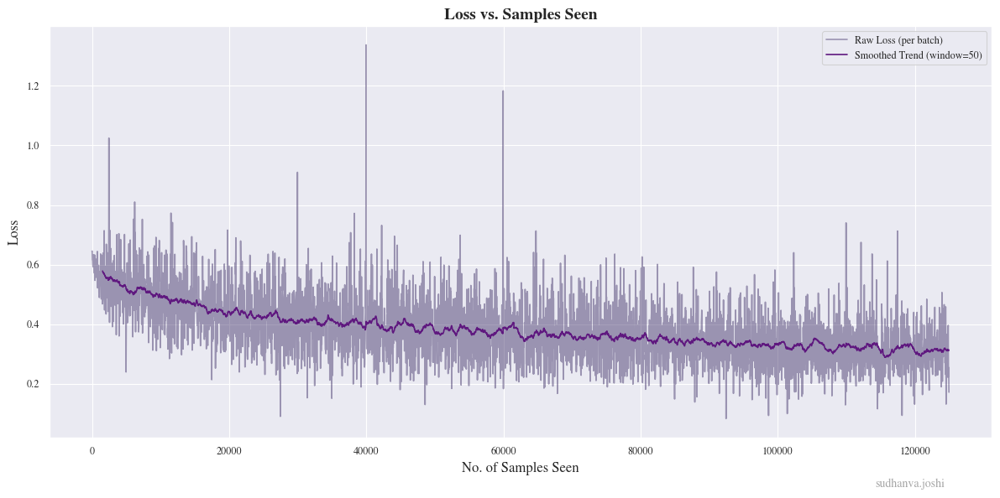

Saving final model.
Model saved to runs-q1/s8v0ajbl/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 85.04%
Final Loss: 0.31245528578560594

Final Pixel Accuracy: 85.04%


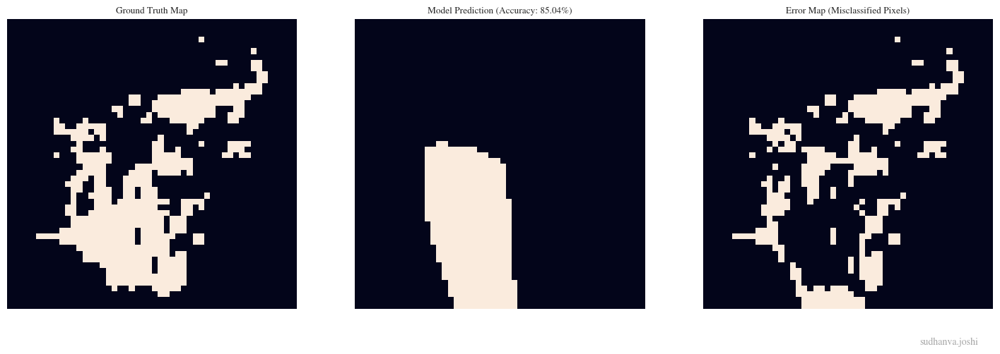

batch_size,32
final_accuracy,0.8504
final_loss,0.31246
grad_steps,2
learning_rate,0.00075
samples_to_converge,125000
time_to_converge,1.81633
total_parameters,1185


wandb: Agent Starting Run: u4g0nb6c with config:
wandb: 	batch_size: 16
wandb: 	depth: 4
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0008532612020618075
wandb: 	width: 128



Sweep Run
Config: Depth=4, Width=128, LR=0.0009, Batch=16



Early stopping triggered at epoch 46.
Epoch 46 complete. Total samples seen: 115000. Time: 6.15s.


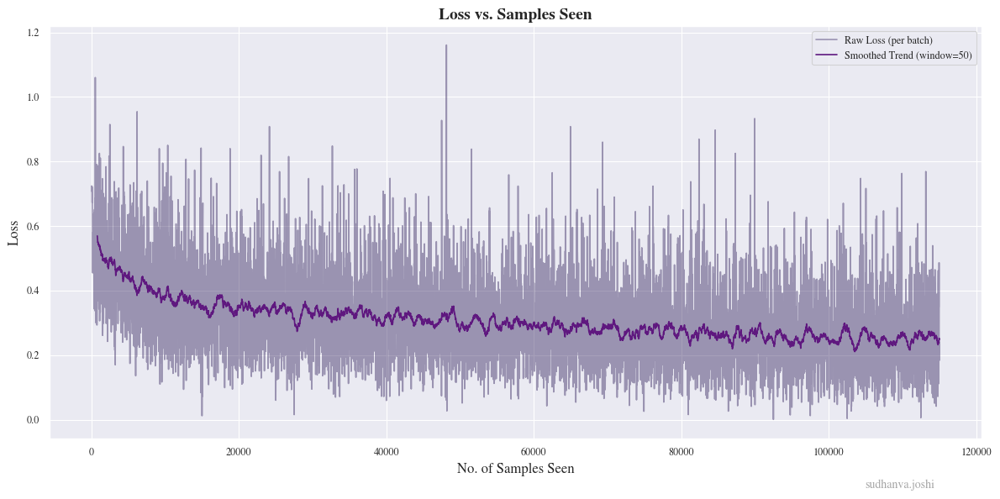

Saving final model.
Model saved to runs-q1/u4g0nb6c/final_model.npz
Model has 33537 trainable parameters.
Final accuracy: 89.12%
Final Loss: 0.25494680592170404

Final Pixel Accuracy: 89.12%


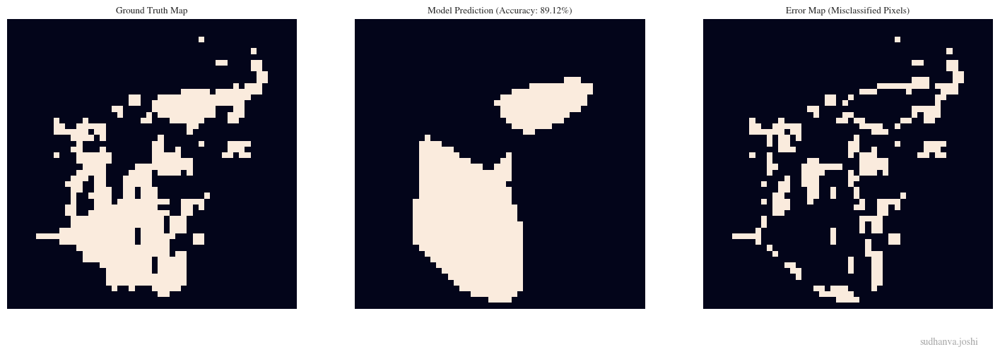

batch_size,16
final_accuracy,0.8912
final_loss,0.25495
grad_steps,4
learning_rate,0.00085
samples_to_converge,115000
time_to_converge,6.15008
total_parameters,33537


wandb: Agent Starting Run: nciasmj1 with config:
wandb: 	batch_size: 32
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.0005430913137354811
wandb: 	width: 32



Sweep Run
Config: Depth=5, Width=32, LR=0.0005, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 2.36s.


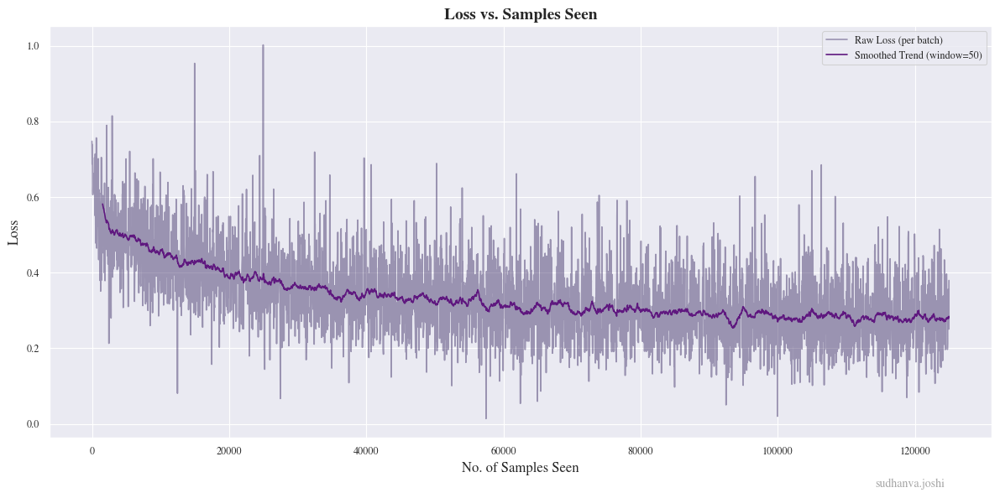

Saving final model.
Model saved to runs-q1/nciasmj1/final_model.npz
Model has 3297 trainable parameters.
Final accuracy: 86.96%
Final Loss: 0.27874909638292167

Final Pixel Accuracy: 86.96%


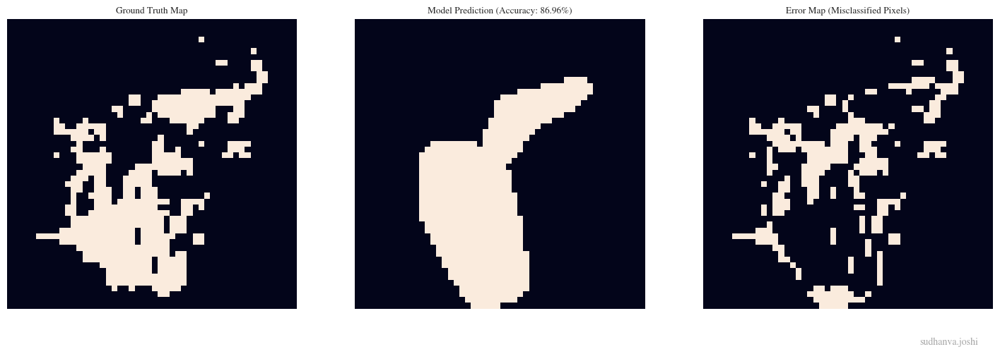

batch_size,32
final_accuracy,0.8696
final_loss,0.27875
grad_steps,2
learning_rate,0.00054
samples_to_converge,125000
time_to_converge,2.36476
total_parameters,3297


wandb: Agent Starting Run: nor9svz0 with config:
wandb: 	batch_size: 32
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.000702895940335402
wandb: 	width: 256



Sweep Run
Config: Depth=5, Width=256, LR=0.0007, Batch=32



Early stopping triggered at epoch 49.
Epoch 49 complete. Total samples seen: 122500. Time: 66.65s.


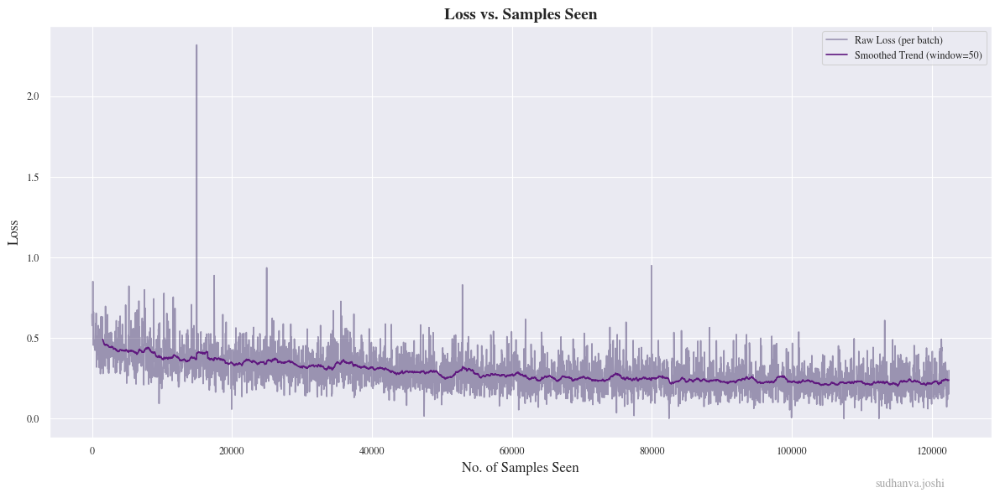

Saving final model.
Model saved to runs-q1/nor9svz0/final_model.npz
Model has 198401 trainable parameters.
Final accuracy: 90.40%
Final Loss: 0.23497952607435613

Final Pixel Accuracy: 90.40%


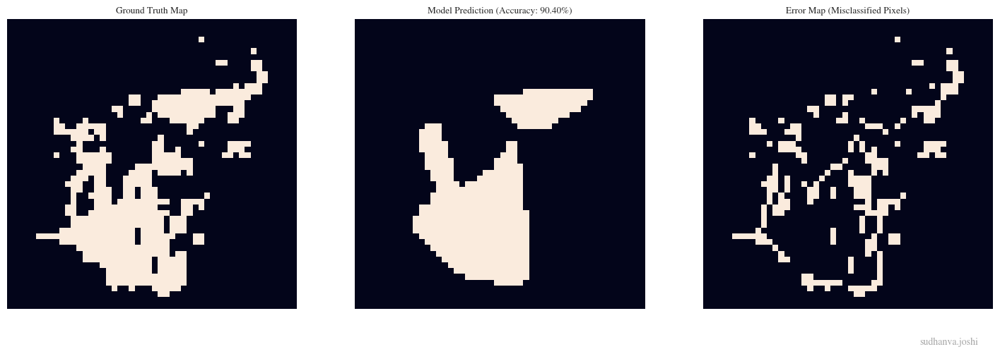

batch_size,32
final_accuracy,0.904
final_loss,0.23498
grad_steps,2
learning_rate,0.0007
samples_to_converge,122500
time_to_converge,66.65393
total_parameters,198401


wandb: Agent Starting Run: t8cvrk63 with config:
wandb: 	batch_size: 128
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 1
wandb: 	learning_rate: 0.0001227301907204006
wandb: 	width: 64



Sweep Run
Config: Depth=3, Width=64, LR=0.0001, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 1.46s.


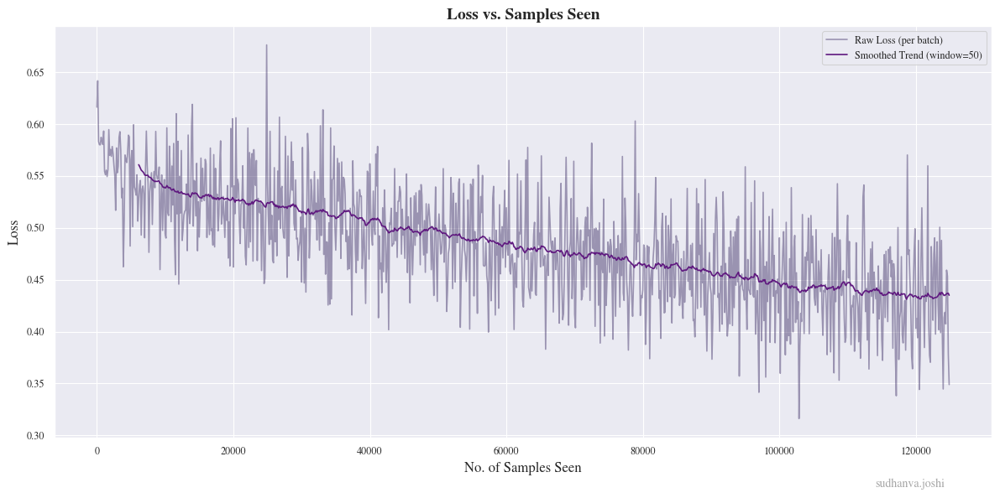

Saving final model.
Model saved to runs-q1/t8cvrk63/final_model.npz
Model has 4417 trainable parameters.
Final accuracy: 79.44%
Final Loss: 0.42990054892763147

Final Pixel Accuracy: 79.44%


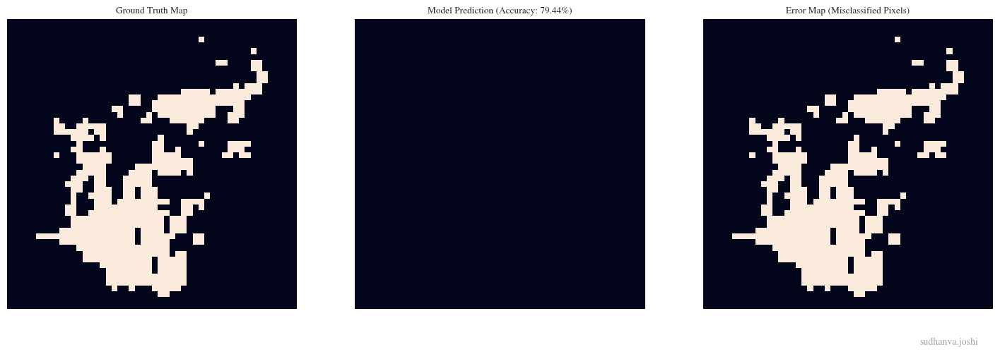

batch_size,128
final_accuracy,0.7944
final_loss,0.4299
grad_steps,1
learning_rate,0.00012
samples_to_converge,125000
time_to_converge,1.45919
total_parameters,4417


wandb: Agent Starting Run: 6nnjzsgn with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.00047584804889663784
wandb: 	width: 128



Sweep Run
Config: Depth=6, Width=128, LR=0.0005, Batch=32



Early stopping triggered at epoch 41.
Epoch 41 complete. Total samples seen: 102500. Time: 8.50s.


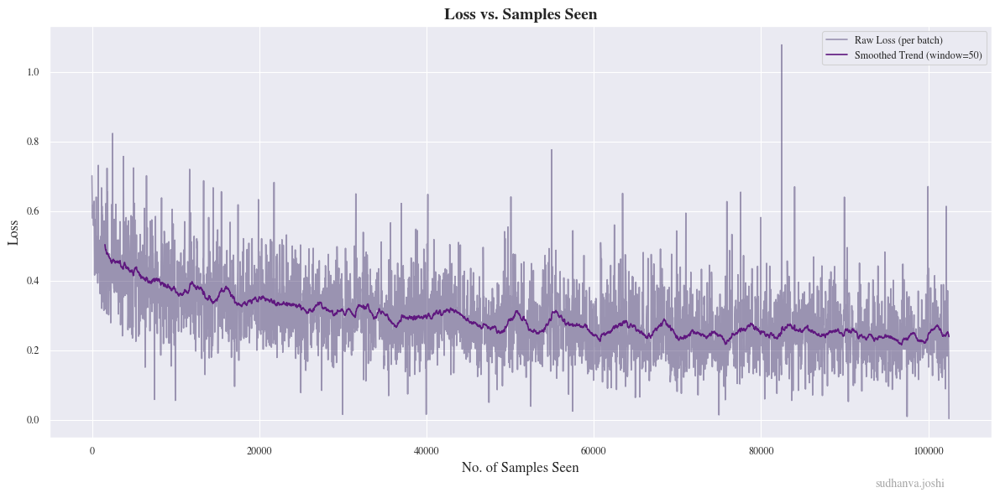

Saving final model.
Model saved to runs-q1/6nnjzsgn/final_model.npz
Model has 66561 trainable parameters.
Final accuracy: 86.68%
Final Loss: 0.25006300896546757

Final Pixel Accuracy: 86.68%


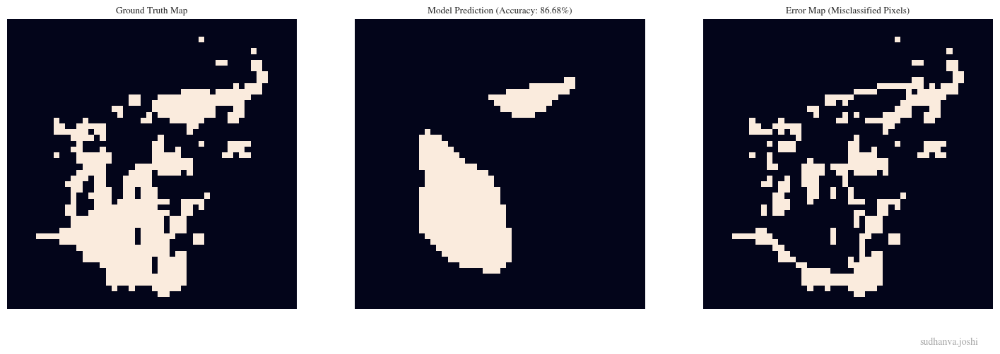

batch_size,32
final_accuracy,0.8668
final_loss,0.25006
grad_steps,2
learning_rate,0.00048
samples_to_converge,102500
time_to_converge,8.50007
total_parameters,66561


wandb: Agent Starting Run: kuk7j3n6 with config:
wandb: 	batch_size: 16
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0007241078097783041
wandb: 	width: 256



Sweep Run
Config: Depth=6, Width=256, LR=0.0007, Batch=16



Early stopping triggered at epoch 46.
Epoch 46 complete. Total samples seen: 115000. Time: 29.34s.


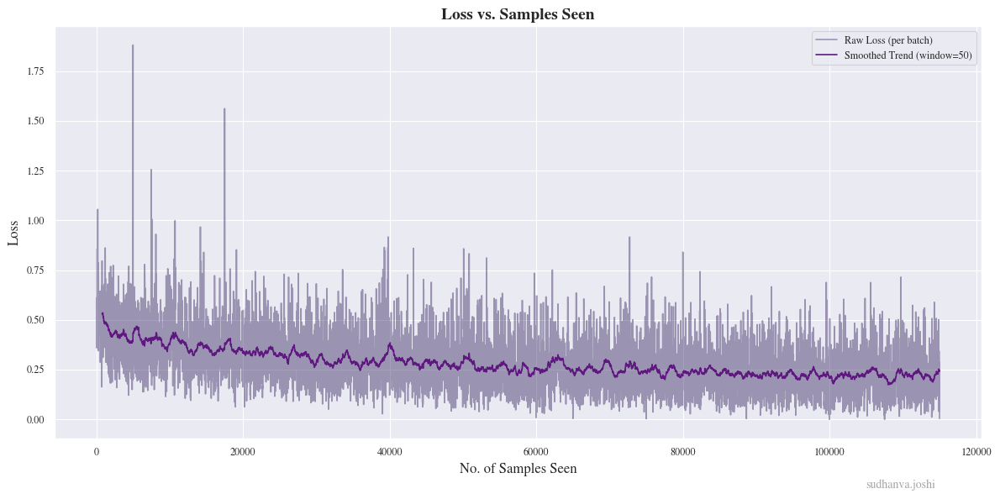

Saving final model.
Model saved to runs-q1/kuk7j3n6/final_model.npz
Model has 264193 trainable parameters.
Final accuracy: 91.32%
Final Loss: 0.22039196950396536

Final Pixel Accuracy: 91.32%


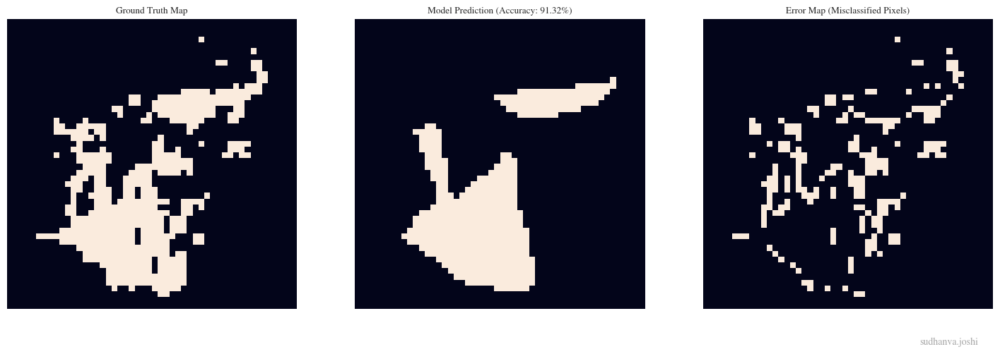

batch_size,16
final_accuracy,0.9132
final_loss,0.22039
grad_steps,4
learning_rate,0.00072
samples_to_converge,115000
time_to_converge,29.34356
total_parameters,264193


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: u1ksuk97 with config:
wandb: 	batch_size: 128
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0007846681562630138
wandb: 	width: 256



Sweep Run
Config: Depth=3, Width=256, LR=0.0008, Batch=128


Epoch 50 complete. Total samples seen: 125000. Time: 6.83s.


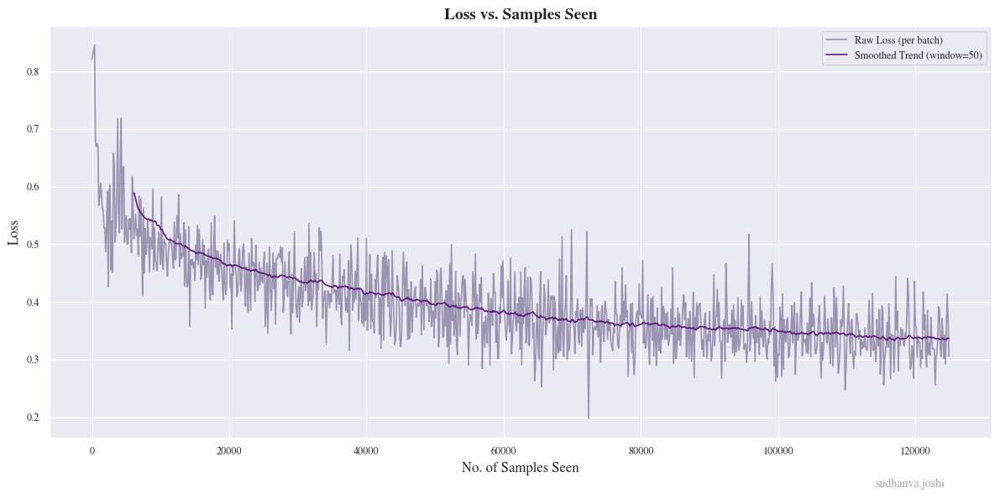

Saving final model.
Model saved to runs-q1/u1ksuk97/final_model.npz
Model has 66817 trainable parameters.
Final accuracy: 84.32%
Final Loss: 0.33393797862608793

Final Pixel Accuracy: 84.32%


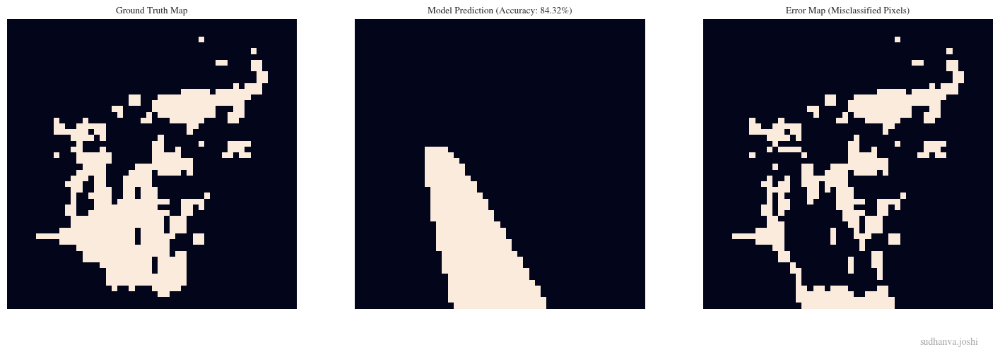

batch_size,128
final_accuracy,0.8432
final_loss,0.33394
grad_steps,4
learning_rate,0.00078
samples_to_converge,125000
time_to_converge,6.83445
total_parameters,66817


wandb: Agent Starting Run: 73uh00wy with config:
wandb: 	batch_size: 64
wandb: 	depth: 5
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.0003674167320894418
wandb: 	width: 64



Sweep Run
Config: Depth=5, Width=64, LR=0.0004, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 1.84s.


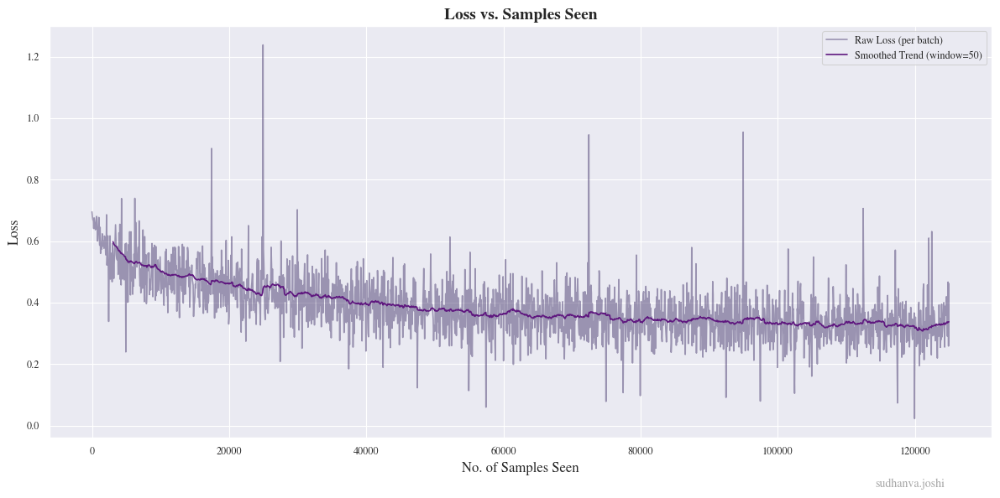

Saving final model.
Model saved to runs-q1/73uh00wy/final_model.npz
Model has 12737 trainable parameters.
Final accuracy: 84.64%
Final Loss: 0.32845232691969

Final Pixel Accuracy: 84.64%


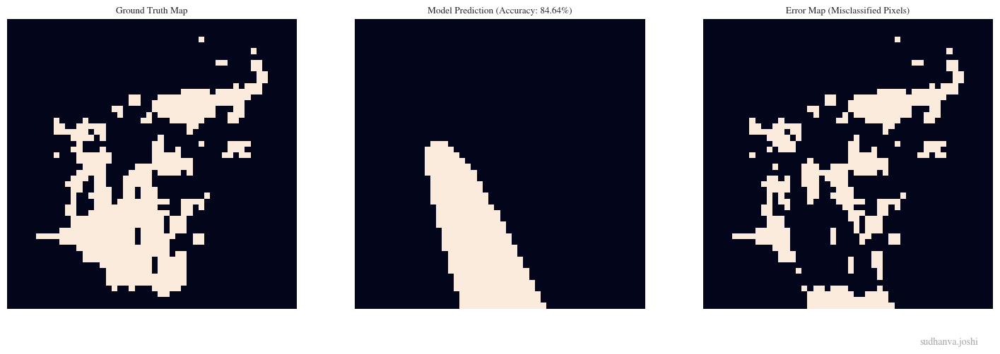

batch_size,64
final_accuracy,0.8464
final_loss,0.32845
grad_steps,4
learning_rate,0.00037
samples_to_converge,125000
time_to_converge,1.837
total_parameters,12737


wandb: Agent Starting Run: n6xurz32 with config:
wandb: 	batch_size: 64
wandb: 	depth: 3
wandb: 	grad_accumulation_steps: 4
wandb: 	learning_rate: 0.00017771727803460048
wandb: 	width: 32



Sweep Run
Config: Depth=3, Width=32, LR=0.0002, Batch=64


Epoch 50 complete. Total samples seen: 125000. Time: 0.99s.


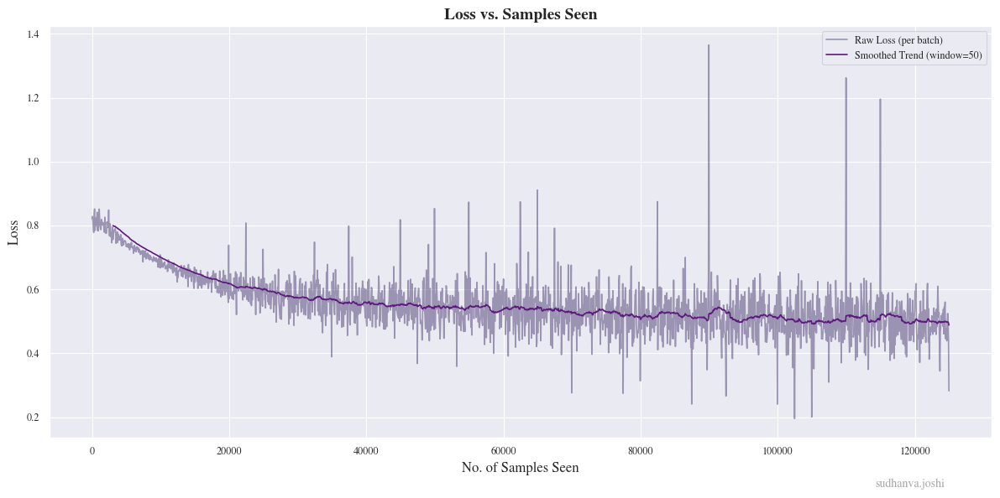

Saving final model.
Model saved to runs-q1/n6xurz32/final_model.npz
Model has 1185 trainable parameters.
Final accuracy: 79.44%
Final Loss: 0.49646027451241864

Final Pixel Accuracy: 79.44%


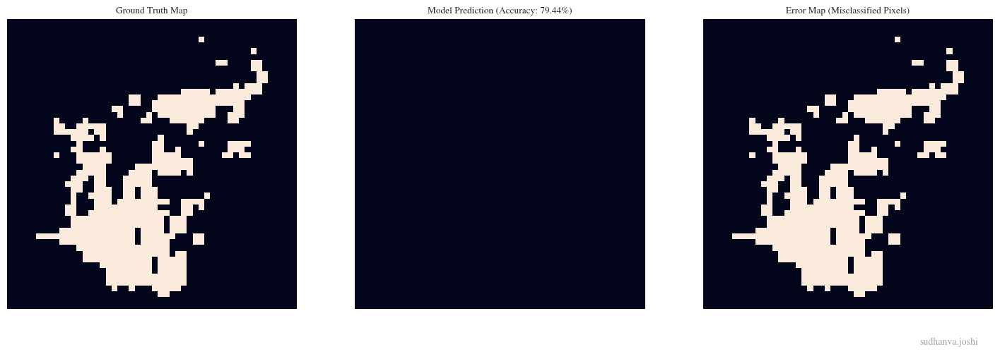

batch_size,64
final_accuracy,0.7944
final_loss,0.49646
grad_steps,4
learning_rate,0.00018
samples_to_converge,125000
time_to_converge,0.98951
total_parameters,1185


wandb: Agent Starting Run: uj3n9s9e with config:
wandb: 	batch_size: 32
wandb: 	depth: 6
wandb: 	grad_accumulation_steps: 2
wandb: 	learning_rate: 0.00010402174363711116
wandb: 	width: 64



Sweep Run
Config: Depth=6, Width=64, LR=0.0001, Batch=32


Epoch 50 complete. Total samples seen: 125000. Time: 4.57s.


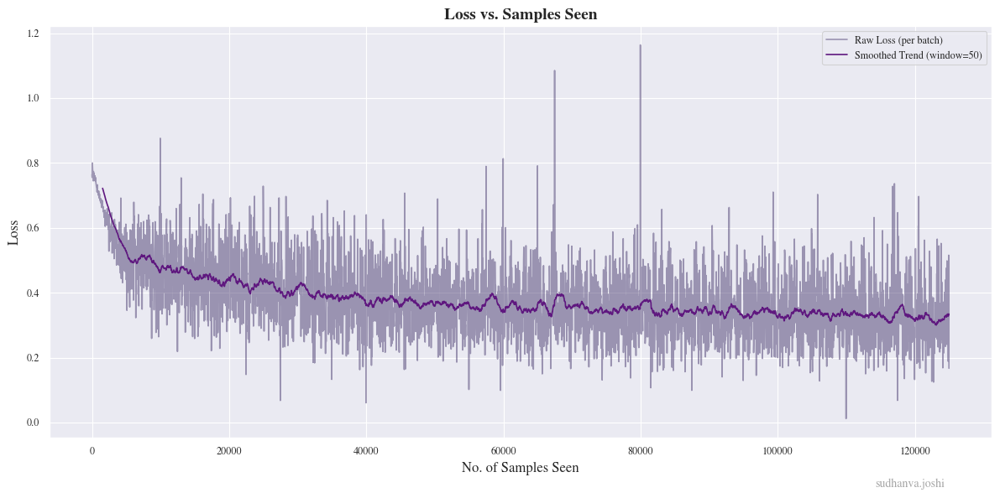

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 16897 trainable parameters.
Final accuracy: 84.64%
Final Loss: 0.32586673134078753

Final Pixel Accuracy: 84.64%


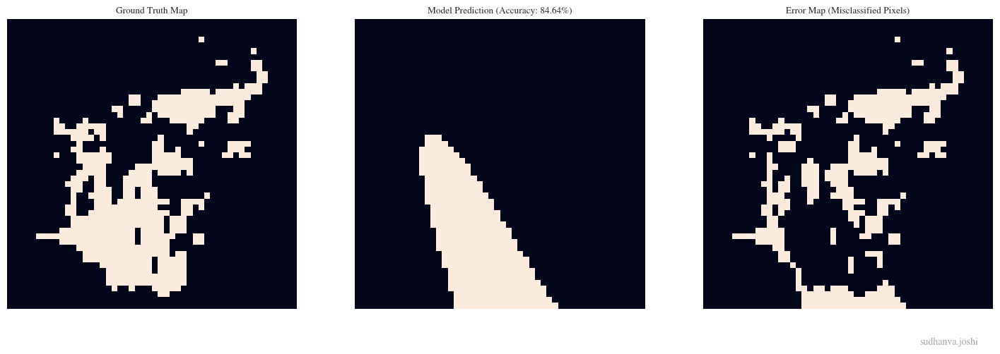

batch_size,32
final_accuracy,0.8464
final_loss,0.32587
grad_steps,2
learning_rate,0.0001
samples_to_converge,125000
time_to_converge,4.57011
total_parameters,16897


In [22]:
# 1. Define the sweep configuration
sweep_config = {
    'method': 'bayes',
    # metric can be changed to satisfy constraaints
    'metric': {
        'name': 'final_accuracy',
        'goal': 'maximize'   
    },
    'parameters': {
        'depth': {'values': [3, 4, 5, 6]},
        'width': {'values': [32, 64, 128, 256]},
        'learning_rate': {
            'distribution': 'uniform',
            'min': 0.0001,
            'max': 0.001
        },
        'batch_size': {'values': [16, 32, 64, 128]},
        'grad_accumulation_steps': {'values': [1, 2, 4]}
    }
}

# Fixed parameters for the sweep
INPUT_DIM = 2
OUTPUT_DIM = 1
EPOCHS = 50 

def train_run():
    """
    This function is called by the wandb agent for each new hyperparameter combination.
    """
    # Initialize a new wandb run for each agent execution.
    with wandb.init(job_type="maximize-accuracy") as run:
        config = wandb.config

        print(f"\nSweep Run")
        print(f"Config: Depth={config.depth}, Width={config.width}, LR={config.learning_rate:.4f}, Batch={config.batch_size}")
        
        # Build the model dynamically based on the sweep's config
        layers = [Linear(INPUT_DIM, config.width, ReLU)]
        for _ in range(config.depth - 2):
            layers.append(Linear(config.width, config.width, ReLU))
        layers.append(Linear(config.width, OUTPUT_DIM, Sigmoid))
        
        model = Model(layers, loss_fn='bce')
        
        # Instead of using underscores, assign samples_seen and time_taken to variables.
        model, run_folder, samples_seen, time_taken, epoch_losses = train_loop(
            model=model,
            dataset=dataset,
            epochs=EPOCHS,
            batch_size=config.batch_size,
            learning_rate=config.learning_rate,
            grad_accumulation_steps=config.grad_accumulation_steps
        )
        
        generate_and_save_maps(model, dataset, run_folder)
        
        # Calculate final metrics
        final_accuracy = calculate_accuracy(model, dataset)
        final_loss = epoch_losses[-1] if epoch_losses else None
        
        wandb.summary["time_to_converge"] = time_taken
        wandb.summary["samples_to_converge"] = samples_seen
        
        wandb.summary['batch_size'] = config.batch_size
        wandb.summary["final_accuracy"] = final_accuracy
        wandb.summary["final_loss"] = final_loss
        wandb.summary["total_parameters"] = count_parameters(model)
        wandb.summary["grad_steps"] = config.grad_accumulation_steps
        wandb.summary["learning_rate"] = config.learning_rate
        
# 2. Initialize the sweep on the W&B server
sweep_id = wandb.sweep(sweep_config, project="smai-a3-q1")

# 3. Start the agent.
wandb.agent(sweep_id, function=train_run, count=100) 

### 1.4.2 Experimentation with Architecture

![Experimentation with Architecture](./plots/1/architecture_.png)


Varying Depth (Width fixed at 64)



Training model with Depth: 3, Width: 64



Early stopping triggered at epoch 42.
Epoch 42 complete. Total samples seen: 105000. Time: 1.64s.


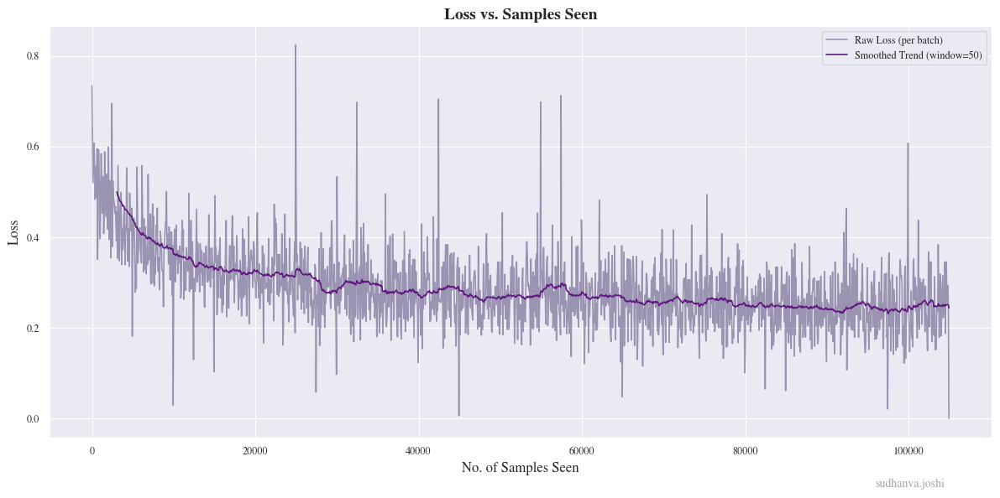

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 4417 trainable parameters.
Final accuracy: 87.48%
Final Loss: 0.2524173749218283



Training model with Depth: 4, Width: 64



Early stopping triggered at epoch 26.
Epoch 26 complete. Total samples seen: 65000. Time: 1.35s.


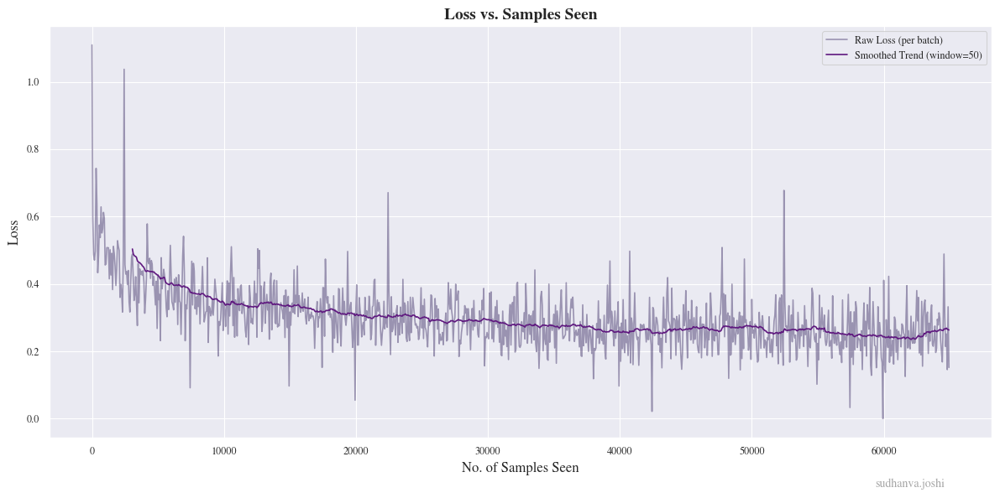

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 8577 trainable parameters.
Final accuracy: 89.24%
Final Loss: 0.27016932460507076



Training model with Depth: 5, Width: 64



Early stopping triggered at epoch 19.
Epoch 19 complete. Total samples seen: 47500. Time: 1.03s.


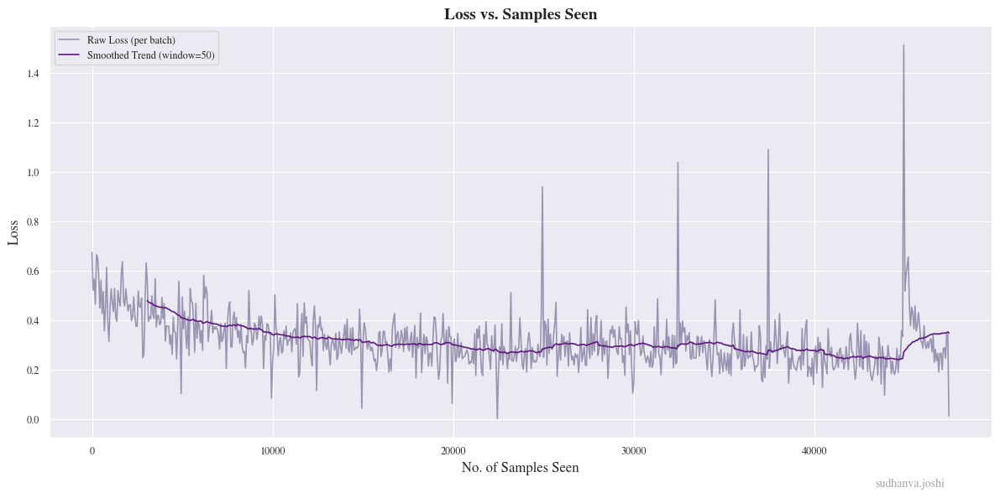

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 12737 trainable parameters.
Final accuracy: 86.12%
Final Loss: 0.35039964289620945



Training model with Depth: 6, Width: 64



Early stopping triggered at epoch 20.
Epoch 20 complete. Total samples seen: 50000. Time: 1.21s.


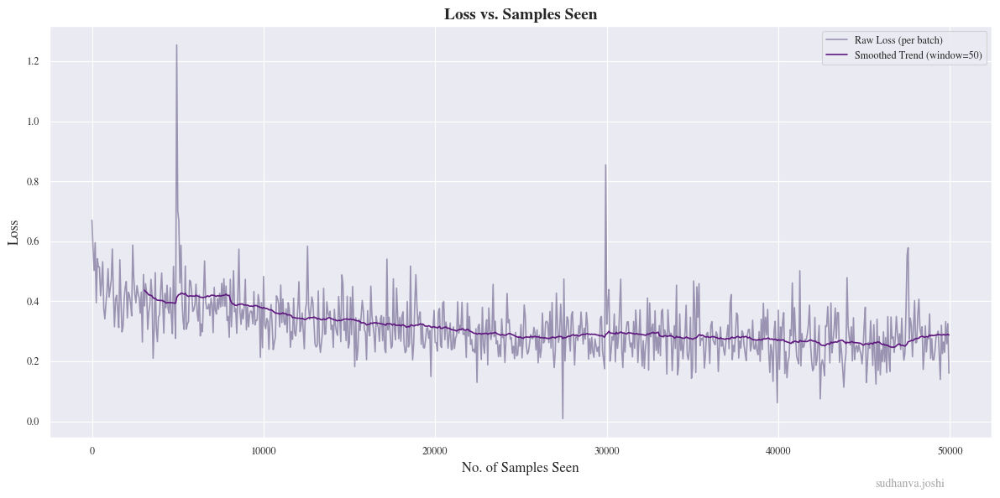

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 16897 trainable parameters.
Final accuracy: 84.92%
Final Loss: 0.2919362737360254



Varying Width (Depth fixed at 4)



Training model with Depth: 4, Width: 16



Early stopping triggered at epoch 49.
Epoch 49 complete. Total samples seen: 122500. Time: 1.28s.


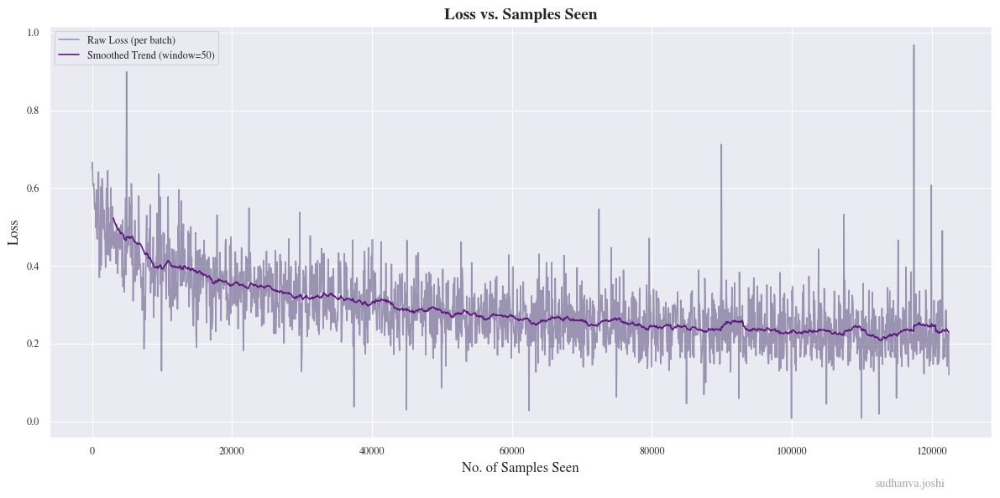

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 609 trainable parameters.
Final accuracy: 90.40%
Final Loss: 0.22991671110640932



Training model with Depth: 4, Width: 32



Early stopping triggered at epoch 27.
Epoch 27 complete. Total samples seen: 67500. Time: 0.83s.


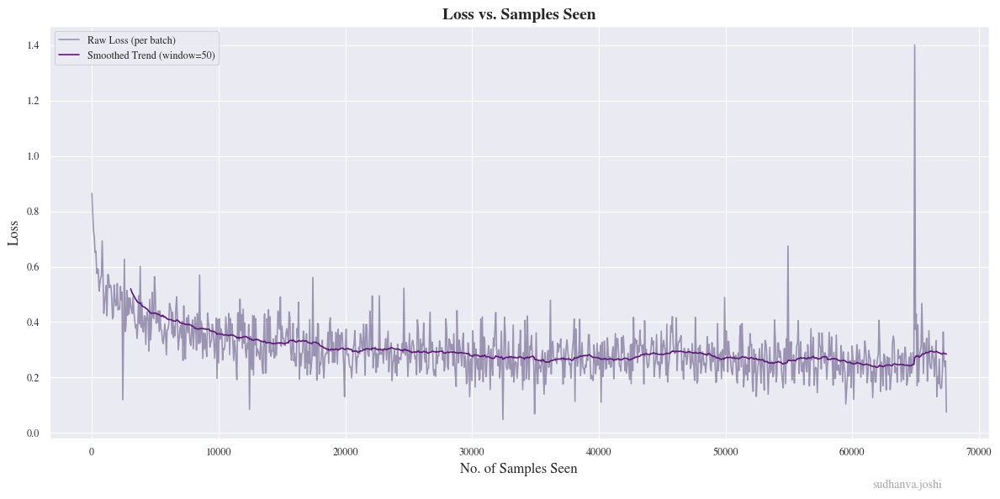

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 2241 trainable parameters.
Final accuracy: 88.60%
Final Loss: 0.27002097827979904



Training model with Depth: 4, Width: 64



Early stopping triggered at epoch 25.
Epoch 25 complete. Total samples seen: 62500. Time: 0.96s.


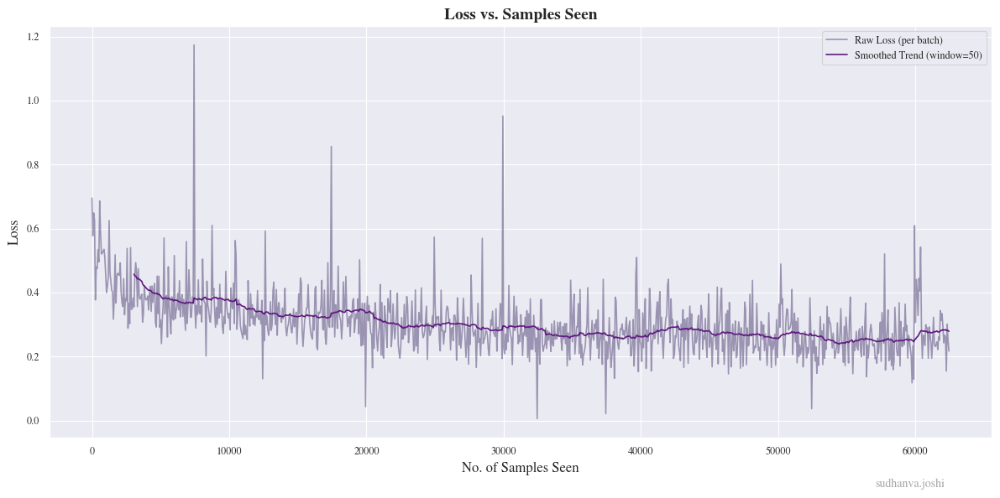

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 8577 trainable parameters.
Final accuracy: 89.40%
Final Loss: 0.2870046925928345



Training model with Depth: 4, Width: 128



Early stopping triggered at epoch 35.
Epoch 35 complete. Total samples seen: 87500. Time: 2.67s.


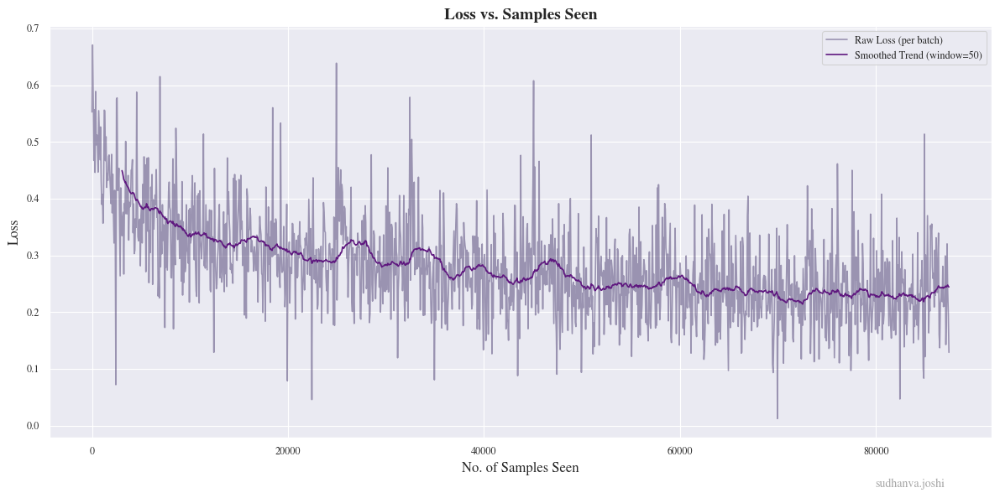

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 33537 trainable parameters.
Final accuracy: 89.56%
Final Loss: 0.24974903875763899



Training model with Depth: 4, Width: 256



Early stopping triggered at epoch 38.
Epoch 38 complete. Total samples seen: 95000. Time: 41.98s.


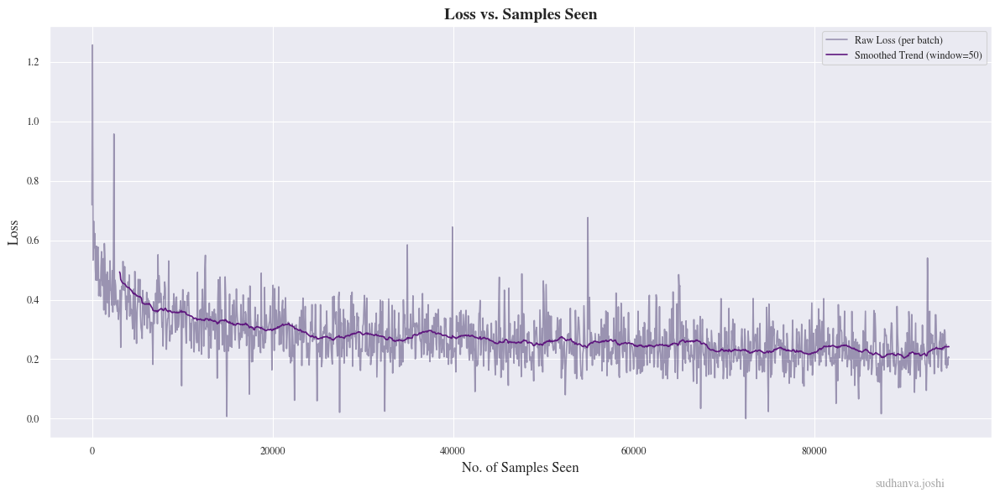

Saving final model.
Model saved to runs-q1/uj3n9s9e/final_model.npz
Model has 132609 trainable parameters.
Final accuracy: 88.40%
Final Loss: 0.25020266085108717


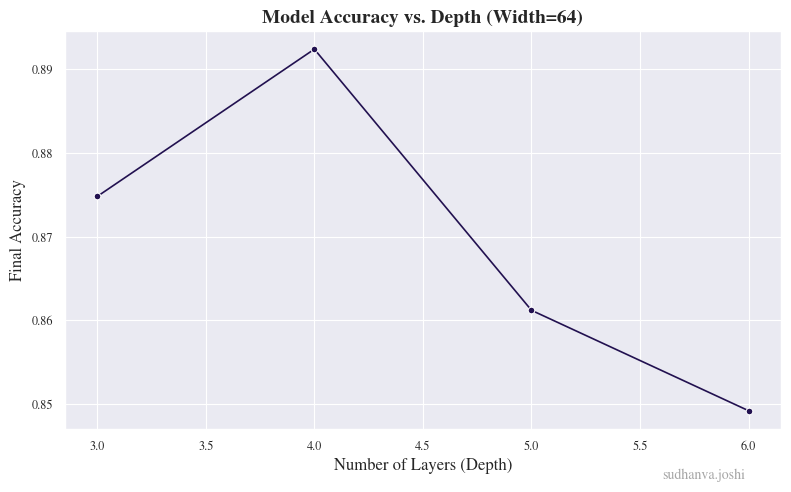

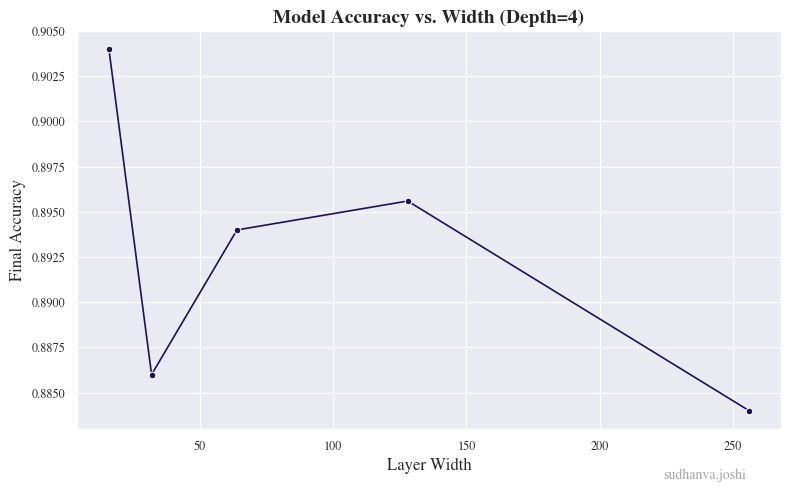

In [23]:
EPOCHS = 50
BATCH_SIZE = 64
LEARNING_RATE = 0.005
INPUT_DIM = 2
OUTPUT_DIM = 1

best_run_info = {
    "accuracy": 0.0,
    "model_path": None,
    "run_folder": None,
    "config": {}
}

FIXED_WIDTH = 64
depths_to_test = [3, 4, 5, 6]
depth_results = []

print(f"\nVarying Depth (Width fixed at {FIXED_WIDTH})")
for depth in depths_to_test:
    with wandb.init(project="smai-a3-q1", job_type="manual-depth-search", reinit=True) as run:
        print(f"\nTraining model with Depth: {depth}, Width: {FIXED_WIDTH}")
        layers = [Linear(INPUT_DIM, FIXED_WIDTH, ReLU)]
        for _ in range(depth - 2):
            layers.append(Linear(FIXED_WIDTH, FIXED_WIDTH, ReLU))
        layers.append(Linear(FIXED_WIDTH, OUTPUT_DIM, Sigmoid))
        model = Model(layers, loss_fn='bce')

        trained_model, run_folder, _, _, _ = train_loop(
            model, dataset, EPOCHS, BATCH_SIZE, LEARNING_RATE, patience=10
        )
        final_accuracy = calculate_accuracy(trained_model, dataset)
        depth_results.append({'depth': depth, 'accuracy': final_accuracy})

        if final_accuracy > best_run_info["accuracy"]:
            best_run_info.update({
                "accuracy": final_accuracy,
                "model_path": os.path.join(run_folder, "final_model.npz"),
                "run_folder": run_folder,
                "config": {"Depth": depth, "Width": FIXED_WIDTH}
            })

# 2. Experiment 2: Varying Width
FIXED_DEPTH = 4
widths_to_test = [16, 32, 64, 128, 256]
width_results = []

print(f"\nVarying Width (Depth fixed at {FIXED_DEPTH})")
for width in widths_to_test:
    with wandb.init(project="smai-a3-q1", job_type="manual-width-search", reinit=True) as run:
        print(f"\nTraining model with Depth: {FIXED_DEPTH}, Width: {width}")
        layers = [Linear(INPUT_DIM, width, ReLU)]
        for _ in range(FIXED_DEPTH - 2):
            layers.append(Linear(width, width, ReLU))
        layers.append(Linear(width, OUTPUT_DIM, Sigmoid))
        model = Model(layers, loss_fn='bce')

        trained_model, run_folder, _, _, _ = train_loop(
            model, dataset, EPOCHS, BATCH_SIZE, LEARNING_RATE, patience=10
        )
        final_accuracy = calculate_accuracy(trained_model, dataset)
        width_results.append({'width': width, 'accuracy': final_accuracy})

        if final_accuracy > best_run_info["accuracy"]:
            best_run_info.update({
                "accuracy": final_accuracy,
                "model_path": os.path.join(run_folder, "final_model.npz"),
                "run_folder": run_folder,
                "config": {"Depth": FIXED_DEPTH, "Width": width}
            })

depth_df = pd.DataFrame(depth_results)
plt.figure(figsize=(8, 5))
sns.lineplot(data=depth_df, x='depth', y='accuracy', marker='o')
plotinfo("Model Accuracy vs. Depth (Width=64)", "Number of Layers (Depth)", "Final Accuracy")

width_df = pd.DataFrame(width_results)
plt.figure(figsize=(8, 5))
sns.lineplot(data=width_df, x='width', y='accuracy', marker='o')
plotinfo(f"Model Accuracy vs. Width (Depth={FIXED_DEPTH})", "Layer Width", "Final Accuracy")

### 1.4.4 Experimentation with Hyperparameters

![Experimentation with Hyperparameters](./plots/1/hyperparameters_.png)

## 1.5 Final Challenge

Since the following relation is generally established in my testing:
$$
\text{Model Size} \propto \text{Convergence Time (No. of Epochs)}
$$
This means that larger models tend to require more time and epochs to converge to an optimal solution.

The following observations are made:

- Optimal Learning Rate: A narrow range of 0.0001 to 0.0005 was essential for success.

- Required Model Capacity: A minimum layer width of 64 was necessary to reach the target accuracy.

- Effective Architecture: The best models consistently used a depth of 4 or 5 layers with a width of 64 or more.


![Summary](./plots/1/summary_.png)

![Final Display](./plots/1/final_.png)


### 1.5.1 Minimize Model Size

- Optimal Architecture: The smallest model to achieve >91% accuracy had a Depth of 4 and a Width of 32.

- Layer width was the most significant factor for both model size and its ability to capture the complex 2D boundary, making it a more critical hyperparameter than depth for this task.

![Architecture](./plots/1/final_arch_.png)


### 1.5.2 Minimize Training Samples

- Optimal Hyperparameters: The fastest convergence was achieved with a large batch size (128) and a moderately high learning rate (~0.0008).

- A large batch size drastically reduces the number of samples required by processing more data per update step.

![Architecture](./plots/1/final_hyper_.png)
